In [1]:
import pandas as pd

# Load the original dataset
df = pd.read_csv("../../data/raw/customer_support_tickets.csv")

# Separate features and target
X = df["instruction"]
y = df["category"]

print("Dataset shape:", df.shape)
print("Number of features:", len(X))
print("Number of targets:", len(y))
print("\nCategories:")
print(y.value_counts())

Dataset shape: (26872, 5)
Number of features: 26872
Number of targets: 26872

Categories:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         1999
CONTACT         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64


In [2]:
# Calculate category distribution
category_distribution = (
    y.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(category_distribution)

category
ACCOUNT         22.28
ORDER           14.84
REFUND          11.13
INVOICE          7.44
CONTACT          7.44
PAYMENT          7.44
FEEDBACK         7.43
DELIVERY         7.42
SHIPPING         7.33
SUBSCRIPTION     3.72
CANCEL           3.54
Name: proportion, dtype: float64


In [3]:
category_counts = y.value_counts()

largest_category = category_counts.idxmax()
smallest_category = category_counts.idxmin()

imbalance_ratio = (
    category_counts.max() / category_counts.min()
)

print("Largest category:", largest_category)
print("Smallest category:", smallest_category)
print("Imbalance ratio:", round(imbalance_ratio, 2))

Largest category: ACCOUNT
Smallest category: CANCEL
Imbalance ratio: 6.3


In [4]:
from pathlib import Path

benchmark_files = {
    "Development": "../../data/benchmark/development.csv",
    "Locked Test": "../../data/benchmark/locked_test.csv",
    "Challenge": "../../data/benchmark/challenge.csv",
}

for name, file_path in benchmark_files.items():
    data = pd.read_csv(file_path)

    print(f"\n{name}")
    print("-" * 35)
    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())


Development
-----------------------------------
Shape: (27, 11)
Columns: ['example_id', 'text', 'expected_category', 'expected_intent', 'test_type', 'challenge_type', 'expected_categories', 'expected_intents', 'requires_clarification', 'annotation_rationale', 'guideline_version']

Locked Test
-----------------------------------
Shape: (108, 11)
Columns: ['example_id', 'text', 'expected_category', 'expected_intent', 'test_type', 'challenge_type', 'expected_categories', 'expected_intents', 'requires_clarification', 'annotation_rationale', 'guideline_version']

Challenge
-----------------------------------
Shape: (22, 11)
Columns: ['example_id', 'text', 'expected_category', 'expected_intent', 'test_type', 'challenge_type', 'expected_categories', 'expected_intents', 'requires_clarification', 'annotation_rationale', 'guideline_version']


In [5]:
python - <<'PY'
import json
from pathlib import Path

path = Path("notebooks/01_data_exploration.ipynb")
notebook = json.loads(path.read_text(encoding="utf-8"))

for i in [27, 30, 43]:
    cell = notebook["cells"][i]

    print("\n" + "=" * 70)
    print(f"CELL {i} — SAVED OUTPUTS")
    print("=" * 70)

    for output in cell.get("outputs", []):
        if "text" in output:
            print("".join(output["text"]))

        elif "data" in output:
            text_data = output["data"].get("text/plain")
            if text_data:
                print("".join(text_data))
PY

SyntaxError: invalid syntax (424484367.py, line 1)

In [6]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

from sklearn.model_selection import StratifiedGroupKFold

print("StratifiedGroupKFold: Available")

Scikit-learn version: 1.9.1
StratifiedGroupKFold: Available


In [7]:
# Count unique normalized instructions for each category

split_data = df[["instruction", "category"]].copy()

split_data["clean_instruction"] = (
    split_data["instruction"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

groups_per_category = (
    split_data.groupby("category")["clean_instruction"]
    .nunique()
    .sort_values()
)

print("Unique groups per category:")
display(groups_per_category)

print("\nTotal unique groups:", split_data["clean_instruction"].nunique())

Unique groups per category:


category
CANCEL           941
SUBSCRIPTION     992
DELIVERY        1645
INVOICE         1801
SHIPPING        1951
CONTACT         1966
PAYMENT         1986
FEEDBACK        1990
REFUND          2577
ORDER           3067
ACCOUNT         5358
Name: clean_instruction, dtype: int64


Total unique groups: 24274


In [8]:
# Check whether normalized groups have conflicting categories

category_conflicts = (
    split_data.groupby("clean_instruction")["category"]
    .nunique()
)

conflicting_groups = category_conflicts[
    category_conflicts > 1
]

print("Groups with conflicting categories:", len(conflicting_groups))

if len(conflicting_groups) > 0:
    display(
        split_data[
            split_data["clean_instruction"].isin(
                conflicting_groups.index
            )
        ].sort_values("clean_instruction").head(20)
    )
else:
    print("PASS: Every normalized group has exactly one category.")

Groups with conflicting categories: 0
PASS: Every normalized group has exactly one category.


In [9]:
# Check category distribution across 5 folds

from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

X_split = split_data["clean_instruction"]
y_split = split_data["category"]
groups_split = split_data["clean_instruction"]

fold_summary = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_split, y_split, groups_split),
    start=1
):
    train_categories = y_split.iloc[train_idx].nunique()
    val_categories = y_split.iloc[val_idx].nunique()

    fold_summary.append({
        "Fold": fold,
        "Training Samples": len(train_idx),
        "Validation Samples": len(val_idx),
        "Training Categories": train_categories,
        "Validation Categories": val_categories
    })

fold_summary = pd.DataFrame(fold_summary)

display(fold_summary)

,Fold,Training Samples,Validation Samples,Training Categories,Validation Categories
0,1,21497,5375,11,11
1,2,21498,5374,11,11
2,3,21497,5375,11,11
3,4,21498,5374,11,11
4,5,21498,5374,11,11


In [10]:
fold_distributions = []

for fold, (_, val_idx) in enumerate(
    cv.split(X_split, y_split, groups_split),
    start=1
):
    distribution = (
        y_split.iloc[val_idx]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )

    distribution.name = f"Fold {fold}"
    fold_distributions.append(distribution)

fold_distribution_df = pd.concat(
    fold_distributions,
    axis=1
)

display(fold_distribution_df)

,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
category,,,,,
ACCOUNT,22.27,22.27,22.27,22.29,22.27
ORDER,14.85,14.85,14.83,14.83,14.85
REFUND,11.13,11.13,11.14,11.15,11.13
INVOICE,7.44,7.42,7.44,7.44,7.44
PAYMENT,7.44,7.44,7.44,7.42,7.42
CONTACT,7.44,7.44,7.44,7.42,7.44
FEEDBACK,7.42,7.44,7.42,7.42,7.44
DELIVERY,7.42,7.41,7.42,7.42,7.42
SHIPPING,7.33,7.33,7.33,7.33,7.33


Feature Extraction — Introduction

In [11]:
# Example customer support messages

sample_messages = [
    "I want to cancel my order",
    "I want to track my order",
    "I need a refund"
]

for message in sample_messages:
    print(message)

I want to cancel my order
I want to track my order
I need a refund


In [12]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

X_counts = vectorizer.fit_transform(sample_messages)

print("Vocabulary:")
print(vectorizer.get_feature_names_out())

print("\nNumerical Matrix:")
print(X_counts.toarray())

Vocabulary:
['cancel' 'my' 'need' 'order' 'refund' 'to' 'track' 'want']

Numerical Matrix:
[[1 1 0 1 0 1 0 1]
 [0 1 0 1 0 1 1 1]
 [0 0 1 0 1 0 0 0]]


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()

X_tfidf = tfidf_vectorizer.fit_transform(sample_messages)

print("Vocabulary:")
print(tfidf_vectorizer.get_feature_names_out())

print("\nTF-IDF Matrix:")
print(X_tfidf.toarray().round(3))

Vocabulary:
['cancel' 'my' 'need' 'order' 'refund' 'to' 'track' 'want']

TF-IDF Matrix:
[[0.549 0.418 0.    0.418 0.    0.418 0.    0.418]
 [0.    0.418 0.    0.418 0.    0.418 0.549 0.418]
 [0.    0.    0.707 0.    0.707 0.    0.    0.   ]]


In [14]:
from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    ngram_range=(1, 2)
)

X_bigrams = bigram_vectorizer.fit_transform(sample_messages)

print("Vocabulary:")
print(bigram_vectorizer.get_feature_names_out())

print("\nMatrix Shape:")
print(X_bigrams.shape)

Vocabulary:
['cancel' 'cancel my' 'my' 'my order' 'need' 'need refund' 'order'
 'refund' 'to' 'to cancel' 'to track' 'track' 'track my' 'want' 'want to']

Matrix Shape:
(3, 15)


In [15]:
# Text preprocessing example

messy_messages = [
    "I WANT TO CANCEL MY ORDER!!!",
    "I want to cancel my order",
    "i want to cancel my order"
]

clean_messages = [
    message.lower()
    for message in messy_messages
]

for original, clean in zip(messy_messages, clean_messages):
    print("Original:", original)
    print("Clean:", clean)
    print("-" * 40)

Original: I WANT TO CANCEL MY ORDER!!!
Clean: i want to cancel my order!!!
----------------------------------------
Original: I want to cancel my order
Clean: i want to cancel my order
----------------------------------------
Original: i want to cancel my order
Clean: i want to cancel my order
----------------------------------------


In [16]:
import re

clean_without_punctuation = [
    re.sub(r"[^\w\s]", "", message)
    for message in clean_messages
]

for original, clean in zip(clean_messages, clean_without_punctuation):
    print("Before:", original)
    print("After:", clean)
    print("-" * 40)

Before: i want to cancel my order!!!
After: i want to cancel my order
----------------------------------------
Before: i want to cancel my order
After: i want to cancel my order
----------------------------------------
Before: i want to cancel my order
After: i want to cancel my order
----------------------------------------


In [17]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

sample_text = "I do not want to cancel my order"

words = sample_text.lower().split()

filtered_words = [
    word for word in words
    if word not in ENGLISH_STOP_WORDS
]

print("Original words:", words)
print("After removing stop words:", filtered_words)

Original words: ['i', 'do', 'not', 'want', 'to', 'cancel', 'my', 'order']
After removing stop words: ['want', 'cancel', 'order']


In [18]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ["cancelling", "studies", "better"]

for word in words:
    print(
        word,
        "| Stemming:", stemmer.stem(word),
        "| Lemmatization:", lemmatizer.lemmatize(word)
    )

ModuleNotFoundError: No module named 'nltk'

In [19]:
%pip install nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 6.0 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [nltk]3/4 [nltk]
Note: you may need to restart the kernel to use updated packages.


In [20]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

words = ["cancelling", "studies", "better"]

for word in words:
    print(
        word,
        "| Stemming:", stemmer.stem(word),
        "| Lemmatization:", lemmatizer.lemmatize(word)
    )

LookupError: 
**********************************************************************
  Resource 'wordnet' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('wordnet')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'corpora/wordnet'

  Searched in:
    - '/Users/raghad/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/share/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [21]:
words = ["cancelling", "studies", "better"]

for word in words:
    print(
        word,
        "| Lemma as noun:", lemmatizer.lemmatize(word, pos="n"),
        "| Lemma as verb:", lemmatizer.lemmatize(word, pos="v"),
        "| Lemma as adjective:", lemmatizer.lemmatize(word, pos="a")
    )
    

LookupError: 
**********************************************************************
  Resource 'wordnet' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('wordnet')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'corpora/wordnet'

  Searched in:
    - '/Users/raghad/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/share/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [22]:
import nltk

nltk.download("wordnet")

[nltk_data] Error loading wordnet: <urlopen error [SSL:
[nltk_data]     CERTIFICATE_VERIFY_FAILED] certificate verify failed:
[nltk_data]     unable to get local issuer certificate (_ssl.c:1000)>


False

In [23]:
words = ["cancelling", "studies", "better"]

for word in words:
    print(
        word,
        "| Lemma as noun:", lemmatizer.lemmatize(word, pos="n"),
        "| Lemma as verb:", lemmatizer.lemmatize(word, pos="v"),
        "| Lemma as adjective:", lemmatizer.lemmatize(word, pos="a")
    )

LookupError: 
**********************************************************************
  Resource 'wordnet' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('wordnet')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'corpora/wordnet'

  Searched in:
    - '/Users/raghad/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/share/nltk_data'
    - '/Users/raghad/Desktop/Lumora/.venv/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'
**********************************************************************


In [24]:
from nltk.stem import PorterStemmer

stemmer = PorterStemmer()

words = ["cancelling", "studies", "better", "running", "orders"]

for word in words:
    print(word, "→", stemmer.stem(word))

cancelling → cancel
studies → studi
better → better
running → run
orders → order


In [25]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

lumora_baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        lowercase=True
    )),
    
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print(lumora_baseline)

Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


In [26]:
# Features and Target
X = split_data["instruction"]
y = split_data["category"]

# Groups: normalized instructions
groups = split_data["clean_instruction"]

print("Number of samples:", len(X))
print("Number of categories:", y.nunique())
print("Number of unique groups:", groups.nunique())

Number of samples: 26872
Number of categories: 11
Number of unique groups: 24274


In [27]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

cv_results = cross_validate(
    lumora_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True
)

print("Cross-Validation Results:\n")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric}: "
        f"Mean = {scores.mean():.4f} | "
        f"Std = {scores.std():.4f}"
    )

Cross-Validation Results:

accuracy: Mean = 0.9973 | Std = 0.0007
precision_macro: Mean = 0.9984 | Std = 0.0005
recall_macro: Mean = 0.9969 | Std = 0.0009
f1_macro: Mean = 0.9976 | Std = 0.0007
f1_weighted: Mean = 0.9973 | Std = 0.0007


In [28]:
print("Training vs Validation\n")

for metric in ["accuracy", "f1_macro"]:
    train_scores = cv_results[f"train_{metric}"]
    val_scores = cv_results[f"test_{metric}"]

    print(f"{metric.upper()}")
    print(f"Training Mean:   {train_scores.mean():.4f}")
    print(f"Validation Mean: {val_scores.mean():.4f}")
    print(f"Difference:      {train_scores.mean() - val_scores.mean():.4f}")
    print("-" * 40)

Training vs Validation

ACCURACY
Training Mean:   0.9989
Validation Mean: 0.9973
Difference:      0.0015
----------------------------------------
F1_MACRO
Training Mean:   0.9990
Validation Mean: 0.9976
Difference:      0.0013
----------------------------------------


In [29]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

oof_predictions = cross_val_predict(
    lumora_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    n_jobs=-1
)

class_report = classification_report(
    y,
    oof_predictions,
    digits=4,
    zero_division=0
)

print(class_report)

              precision    recall  f1-score   support

     ACCOUNT     0.9912    1.0000    0.9956      5986
      CANCEL     0.9989    1.0000    0.9995       950
     CONTACT     1.0000    0.9985    0.9992      1999
    DELIVERY     0.9960    0.9990    0.9975      1994
    FEEDBACK     0.9995    0.9995    0.9995      1997
     INVOICE     0.9995    1.0000    0.9997      1999
       ORDER     0.9997    0.9952    0.9975      3988
     PAYMENT     1.0000    0.9890    0.9945      1998
      REFUND     0.9983    0.9990    0.9987      2992
    SHIPPING     0.9990    0.9919    0.9954      1970
SUBSCRIPTION     1.0000    0.9940    0.9970       999

    accuracy                         0.9973     26872
   macro avg     0.9984    0.9969    0.9976     26872
weighted avg     0.9973    0.9973    0.9973     26872



In [30]:
import pandas as pd
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=lumora_baseline.classes_
)

cm_df = pd.DataFrame(
    cm,
    index=lumora_baseline.classes_,
    columns=lumora_baseline.classes_
)

display(cm_df)

AttributeError: 'LogisticRegression' object has no attribute 'classes_'

In [31]:
import pandas as pd
from sklearn.metrics import confusion_matrix

class_labels = sorted(y.unique())

cm = confusion_matrix(
    y,
    oof_predictions,
    labels=class_labels
)

cm_df = pd.DataFrame(
    cm,
    index=class_labels,
    columns=class_labels
)

display(cm_df)

,ACCOUNT,CANCEL,CONTACT,DELIVERY,FEEDBACK,INVOICE,ORDER,PAYMENT,REFUND,SHIPPING,SUBSCRIPTION
ACCOUNT,5986,0,0,0,0,0,0,0,0,0,0
CANCEL,0,950,0,0,0,0,0,0,0,0,0
CONTACT,1,0,1996,0,0,0,0,0,1,1,0
DELIVERY,2,0,0,1992,0,0,0,0,0,0,0
FEEDBACK,0,0,0,0,1996,0,0,0,0,1,0
INVOICE,0,0,0,0,0,1999,0,0,0,0,0
ORDER,14,0,0,2,1,1,3969,0,1,0,0
PAYMENT,17,0,0,4,0,0,0,1976,1,0,0
REFUND,0,1,0,1,0,0,1,0,2989,0,0
SHIPPING,15,0,0,1,0,0,0,0,0,1954,0


In [32]:
misclassified = pd.DataFrame({
    "instruction": X.values,
    "true_category": y.values,
    "predicted_category": oof_predictions
})

misclassified = misclassified[
    misclassified["true_category"] !=
    misclassified["predicted_category"]
]

print("Number of errors:", len(misclassified))

display(misclassified)

Number of errors: 72


,instruction,true_category,predicted_category
166,would you give me information about cancelling...,ORDER,ACCOUNT
579,question about canceling a bloody purchase,ORDER,ACCOUNT
1076,update purchase00004587345,ORDER,ACCOUNT
1180,need to edit order113542617735902 how to do it,ORDER,ACCOUNT
1226,update purchase732201349959,ORDER,ACCOUNT
...,...,...,...
23851,the delivery addrses isnt valid can i get some...,SHIPPING,DELIVERY
25056,i want help to track purchase00123842,ORDER,REFUND
25118,i dont know how i can check the eta of my last...,ORDER,DELIVERY
25589,i have to see the damn ETA of my delivery helpme,ORDER,DELIVERY


In [33]:
error_patterns = (
    misclassified
    .groupby(["true_category", "predicted_category"])
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

display(error_patterns)

,true_category,predicted_category,error_count
10,PAYMENT,ACCOUNT,17
16,SHIPPING,ACCOUNT,15
5,ORDER,ACCOUNT,14
18,SUBSCRIPTION,ACCOUNT,4
11,PAYMENT,DELIVERY,4
6,ORDER,DELIVERY,2
19,SUBSCRIPTION,REFUND,2
3,DELIVERY,ACCOUNT,2
7,ORDER,FEEDBACK,1
8,ORDER,INVOICE,1


In [34]:
main_errors = misclassified[
    (
        (misclassified["true_category"] == "PAYMENT") |
        (misclassified["true_category"] == "SHIPPING") |
        (misclassified["true_category"] == "ORDER")
    )
    &
    (misclassified["predicted_category"] == "ACCOUNT")
]

print("Main error examples:", len(main_errors))

display(
    main_errors[
        ["instruction", "true_category", "predicted_category"]
    ].reset_index(drop=True)
)

Main error examples: 46


,instruction,true_category,predicted_category
0,would you give me information about cancelling...,ORDER,ACCOUNT
1,question about canceling a bloody purchase,ORDER,ACCOUNT
2,update purchase00004587345,ORDER,ACCOUNT
3,need to edit order113542617735902 how to do it,ORDER,ACCOUNT
4,update purchase732201349959,ORDER,ACCOUNT
5,modify order370795561790,ORDER,ACCOUNT
6,can I update order00004587345?,ORDER,ACCOUNT
7,modify order113542617735902,ORDER,ACCOUNT
8,modify order732201349959,ORDER,ACCOUNT
9,modify order00123842,ORDER,ACCOUNT


In [35]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

char_baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        lowercase=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

char_results = cross_validate(
    char_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

print("CHARACTER TF-IDF — 5-FOLD CROSS-VALIDATION")
print("=" * 55)

for metric in scoring:
    scores = char_results[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

CHARACTER TF-IDF — 5-FOLD CROSS-VALIDATION
accuracy: 0.9997 ± 0.0001
precision_macro: 0.9998 ± 0.0001
recall_macro: 0.9997 ± 0.0002
f1_macro: 0.9998 ± 0.0001
f1_weighted: 0.9997 ± 0.0001


In [36]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

word_char_baseline = Pipeline([
    ("features", FeatureUnion([
        ("word_tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            lowercase=True
        )),
        ("char_tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            lowercase=True
        ))
    ])),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

word_char_results = cross_validate(
    word_char_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

print("WORD + CHARACTER TF-IDF — 5-FOLD CROSS-VALIDATION")
print("=" * 60)

for metric in scoring:
    scores = word_char_results[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

WORD + CHARACTER TF-IDF — 5-FOLD CROSS-VALIDATION
accuracy: 0.9996 ± 0.0002
precision_macro: 0.9997 ± 0.0002
recall_macro: 0.9996 ± 0.0002
f1_macro: 0.9997 ± 0.0002
f1_weighted: 0.9996 ± 0.0002


In [37]:
from sklearn.model_selection import cross_val_predict
import pandas as pd

oof_char_predictions = cross_val_predict(
    char_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    n_jobs=1
)

char_errors = pd.DataFrame({
    "instruction": X.values,
    "true_category": y.values,
    "predicted_category": oof_char_predictions
})

char_errors = char_errors[
    char_errors["true_category"] != char_errors["predicted_category"]
].copy()

print("Total samples:", len(X))
print("Misclassified samples:", len(char_errors))
print("Correct predictions:", len(X) - len(char_errors))
print("Error rate:", f"{len(char_errors) / len(X) * 100:.4f}%")

Total samples: 26872
Misclassified samples: 7
Correct predictions: 26865
Error rate: 0.0260%


In [38]:
print("ERROR PATTERNS")
print("=" * 45)

error_patterns = (
    char_errors
    .groupby(["true_category", "predicted_category"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_patterns)

ERROR PATTERNS


,true_category,predicted_category,count
2,PAYMENT,ACCOUNT,3
1,ORDER,DELIVERY,2
0,ORDER,ACCOUNT,1
3,PAYMENT,DELIVERY,1


In [39]:
pd.set_option("display.max_colwidth", None)

display(
    char_errors[
        ["instruction", "true_category", "predicted_category"]
    ].reset_index(drop=True)
)

,instruction,true_category,predicted_category
0,would you give me information about cancelling orders?,ORDER,ACCOUNT
1,do ya accept card,PAYMENT,ACCOUNT
2,i get an error when i try to make a transfer report it,PAYMENT,ACCOUNT
3,I get an error when I try to check out,PAYMENT,DELIVERY
4,I want to inform of pamyent issues,PAYMENT,ACCOUNT
5,i dont know how i can check the eta of my last delivery,ORDER,DELIVERY
6,i have to see the damn ETA of my delivery helpme,ORDER,DELIVERY


In [40]:
error_details = df[
    df["instruction"].isin(char_errors["instruction"])
][["instruction", "category", "intent"]].copy()

display(error_details.reset_index(drop=True))

,instruction,category,intent
0,would you give me information about cancelling orders?,ORDER,cancel_order
1,do ya accept card,PAYMENT,check_payment_methods
2,i get an error when i try to make a transfer report it,PAYMENT,payment_issue
3,I get an error when I try to check out,PAYMENT,payment_issue
4,I want to inform of pamyent issues,PAYMENT,payment_issue
5,i dont know how i can check the eta of my last delivery,ORDER,track_order
6,i have to see the damn ETA of my delivery helpme,ORDER,track_order


In [41]:
from pathlib import Path

benchmark_path = Path("../../data/benchmark")

print("Benchmark files:")
for file in sorted(benchmark_path.glob("*")):
    print(file.name)

Benchmark files:
challenge.csv
development.csv
locked_test.csv


In [42]:
development_df = pd.read_csv(
    "../../data/benchmark/development.csv"
)

print("Development shape:", development_df.shape)
print("\nColumns:")
print(development_df.columns.tolist())

display(
    development_df[
        ["instruction", "category", "intent"]
    ].head(10)
)

Development shape: (27, 11)

Columns:
['example_id', 'text', 'expected_category', 'expected_intent', 'test_type', 'challenge_type', 'expected_categories', 'expected_intents', 'requires_clarification', 'annotation_rationale', 'guideline_version']


KeyError: "None of [Index(['instruction', 'category', 'intent'], dtype='str')] are in the [columns]"

In [43]:
display(
    development_df[
        ["example_id", "text", "expected_category", "expected_intent"]
    ].head(10)
)

,example_id,text,expected_category,expected_intent
0,DEV-001,I need to register a new profile before I can use the service,ACCOUNT,create_account
1,DEV-002,The sign-up page keeps rejecting my details even though I filled everything in,ACCOUNT,registration_problems
2,DEV-003,Please close my membership profile permanently,ACCOUNT,delete_account
3,DEV-004,The mobile number saved in my profile is no longer current; how do I update it?,ACCOUNT,edit_account
4,DEV-005,How can I switch from my personal account to my business account?,ACCOUNT,switch_account
5,DEV-006,I can no longer access my profile because I forgot the security password,ACCOUNT,recover_password
6,DEV-007,An order I submitted needs to be withdrawn before it proceeds any further,ORDER,cancel_order
7,DEV-008,Can the items in my submitted purchase be replaced with different ones?,ORDER,change_order
8,DEV-009,What steps should I follow to purchase something through your website?,ORDER,place_order
9,DEV-010,Has my purchase moved beyond the processing stage yet?,ORDER,track_order


In [44]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Train on the original dataset
char_baseline.fit(X, y)

# Predict Development examples
dev_predictions = char_baseline.predict(
    development_df["text"]
)

# True labels
dev_true = development_df["expected_category"]

# Evaluation
print("CHARACTER TF-IDF — DEVELOPMENT EVALUATION")
print("=" * 55)

print(f"Accuracy:        {accuracy_score(dev_true, dev_predictions):.4f}")
print(f"Macro Precision: {precision_score(dev_true, dev_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:    {recall_score(dev_true, dev_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro F1:        {f1_score(dev_true, dev_predictions, average='macro', zero_division=0):.4f}")

print("\nClassification Report:")
print(
    classification_report(
        dev_true,
        dev_predictions,
        zero_division=0
    )
)

CHARACTER TF-IDF — DEVELOPMENT EVALUATION
Accuracy:        0.8148
Macro Precision: 0.7924
Macro Recall:    0.7273
Macro F1:        0.7315

Classification Report:
              precision    recall  f1-score   support

     ACCOUNT       0.75      1.00      0.86         6
      CANCEL       1.00      1.00      1.00         1
     CONTACT       0.67      1.00      0.80         2
    DELIVERY       0.50      0.50      0.50         2
    FEEDBACK       1.00      1.00      1.00         2
     INVOICE       1.00      0.50      0.67         2
       ORDER       0.80      1.00      0.89         4
     PAYMENT       1.00      0.50      0.67         2
      REFUND       1.00      1.00      1.00         3
    SHIPPING       1.00      0.50      0.67         2
SUBSCRIPTION       0.00      0.00      0.00         1

    accuracy                           0.81        27
   macro avg       0.79      0.73      0.73        27
weighted avg       0.82      0.81      0.79        27



In [45]:
dev_results = development_df[
    ["example_id", "text", "expected_category", "expected_intent"]
].copy()

dev_results["predicted_category"] = dev_predictions

dev_errors = dev_results[
    dev_results["expected_category"] != dev_results["predicted_category"]
].copy()

print("Development Errors:", len(dev_errors))
print("=" * 70)

display(dev_errors.reset_index(drop=True))

Development Errors: 5


,example_id,text,expected_category,expected_intent,predicted_category
0,DEV-016,"My card transaction was declined during checkout, but the amount appears to have been attempted",PAYMENT,payment_issue,ACCOUNT
1,DEV-019,"If I purchase today, approximately how many business days should delivery take?",DELIVERY,delivery_period,ORDER
2,DEV-021,I need a file containing the billing document associated with an earlier transaction,INVOICE,get_invoice,CONTACT
3,DEV-025,The courier has the wrong street details for my current shipment; I need to correct them,SHIPPING,change_shipping_address,DELIVERY
4,DEV-027,Please remove me from the weekly product update emails,SUBSCRIPTION,newsletter_subscription,ACCOUNT


In [46]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Word TF-IDF": lumora_baseline,
    "Character TF-IDF": char_baseline,
    "Word + Character TF-IDF": word_char_baseline
}

dev_comparison = []

for model_name, model in models.items():

    model_copy = clone(model)

    model_copy.fit(X, y)

    predictions = model_copy.predict(development_df["text"])

    dev_comparison.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            development_df["expected_category"], predictions
        ),
        "Macro Precision": precision_score(
            development_df["expected_category"],
            predictions,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            development_df["expected_category"],
            predictions,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            development_df["expected_category"],
            predictions,
            average="macro",
            zero_division=0
        )
    })

dev_comparison_df = pd.DataFrame(dev_comparison)

display(
    dev_comparison_df.round(4).sort_values(
        "Macro F1", ascending=False
    ).reset_index(drop=True)
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Character TF-IDF,0.8148,0.7924,0.7273,0.7315
1,Word + Character TF-IDF,0.7778,0.7742,0.7045,0.7113
2,Word TF-IDF,0.7407,0.7894,0.6742,0.6939


In [47]:
import pandas as pd

feature_names = char_baseline.named_steps["tfidf"].get_feature_names_out()

classifier = char_baseline.named_steps["classifier"]

class_labels = classifier.classes_

for class_index, class_name in enumerate(class_labels):

    top_indices = classifier.coef_[class_index].argsort()[-15:][::-1]

    top_features = feature_names[top_indices]

    print(f"\n{class_name}")
    print("-" * 40)
    print(", ".join(top_features))


ACCOUNT
----------------------------------------
acc, cco, acco, coun, count, ccou, accou, ccoun, unt, oun, cou, ount,  ac,  acc,  acco

CANCEL
----------------------------------------
 fee, fee,  fe, rge, he , arg, arge,  the , the , char, har, harge, harg, charg,  th

CONTACT
----------------------------------------
ome, tal, talk, alk, tom, stom, omer, omer , mer s,  tal,  talk, gen, gent, cus, tome

DELIVERY
----------------------------------------
ive, ship, hip, shi,  ship,  shi,  sh, deli, eliv, rive, elive, iver, arr, riv, deliv

FEEDBACK
----------------------------------------
cla, lai, e a ,  a c,  a , a c, e a, e a c, feed,  feed, dba, edb, edba, dbac, edbac

INVOICE
----------------------------------------
 bi, bil,  bil, bill,  bill, ill, l #, bill , ll #, 777, nvo, inv, invo, ill , voi

ORDER
----------------------------------------
rder, order, rde, orde, ord, der, rder , der ,  or,  ord,  orde, item,  ite, tem,  item

PAYMENT
----------------------------------------
p

In [48]:
dev_probabilities = char_baseline.predict_proba(
    development_df["text"]
)

dev_probability_df = pd.DataFrame(
    dev_probabilities,
    columns=char_baseline.classes_
)

dev_probability_df.insert(
    0,
    "text",
    development_df["text"].values
)

dev_probability_df.insert(
    1,
    "expected_category",
    development_df["expected_category"].values
)

dev_probability_df.insert(
    2,
    "predicted_category",
    dev_predictions
)

dev_probability_df["confidence"] = dev_probability_df[
    char_baseline.classes_
].max(axis=1)

display(
    dev_probability_df[
        dev_probability_df["expected_category"] !=
        dev_probability_df["predicted_category"]
    ].sort_values("confidence", ascending=False).round(4)
)

,text,expected_category,predicted_category,ACCOUNT,CANCEL,CONTACT,DELIVERY,FEEDBACK,INVOICE,ORDER,PAYMENT,REFUND,SHIPPING,SUBSCRIPTION,confidence
24,The courier has the wrong street details for my current shipment; I need to correct them,SHIPPING,DELIVERY,0.2430,0.0298,0.0283,0.3709,0.0371,0.0303,0.0423,0.0212,0.0927,0.0864,0.0180,0.3709
26,Please remove me from the weekly product update emails,SUBSCRIPTION,ACCOUNT,0.3005,0.0372,0.0286,0.0689,0.0978,0.0819,0.2240,0.0249,0.0608,0.0519,0.0236,0.3005
18,"If I purchase today, approximately how many business days should delivery take?",DELIVERY,ORDER,0.0781,0.0221,0.0405,0.2759,0.0579,0.0372,0.2908,0.0267,0.0687,0.0856,0.0166,0.2908
15,"My card transaction was declined during checkout, but the amount appears to have been attempted",PAYMENT,ACCOUNT,0.2320,0.0547,0.0774,0.0883,0.0827,0.0557,0.0892,0.0840,0.1619,0.0480,0.0260,0.2320
20,I need a file containing the billing document associated with an earlier transaction,INVOICE,CONTACT,0.1483,0.0769,0.2291,0.0365,0.1162,0.0986,0.0718,0.0824,0.0740,0.0446,0.0216,0.2291


In [49]:
from sklearn.model_selection import ParameterGrid
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, accuracy_score

param_grid = {
    "ngram_range": [(2, 4), (3, 5), (3, 6)],
    "min_df": [1, 2],
    "C": [0.5, 1.0, 2.0]
}

tuning_results = []

for params in ParameterGrid(param_grid):

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            analyzer="char",
            ngram_range=params["ngram_range"],
            lowercase=True,
            min_df=params["min_df"]
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            C=params["C"],
            random_state=42
        ))
    ])

    model.fit(X, y)

    predictions = model.predict(development_df["text"])

    tuning_results.append({
        "ngram_range": params["ngram_range"],
        "min_df": params["min_df"],
        "C": params["C"],
        "Accuracy": accuracy_score(
            development_df["expected_category"],
            predictions
        ),
        "Macro_F1": f1_score(
            development_df["expected_category"],
            predictions,
            average="macro",
            zero_division=0
        )
    })

tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.sort_values(
        "Macro_F1",
        ascending=False
    ).reset_index(drop=True)
)

,ngram_range,min_df,C,Accuracy,Macro_F1
0,"(3, 6)",2,2.0,0.814815,0.731457
1,"(3, 5)",2,1.0,0.814815,0.731457
2,"(3, 5)",2,2.0,0.814815,0.731457
3,"(3, 6)",1,2.0,0.814815,0.731457
4,"(3, 5)",1,2.0,0.814815,0.731457
5,"(3, 5)",1,1.0,0.814815,0.731457
6,"(2, 4)",2,2.0,0.777778,0.705844
7,"(2, 4)",1,2.0,0.777778,0.705844
8,"(2, 4)",1,0.5,0.777778,0.705844
9,"(2, 4)",1,1.0,0.777778,0.705844


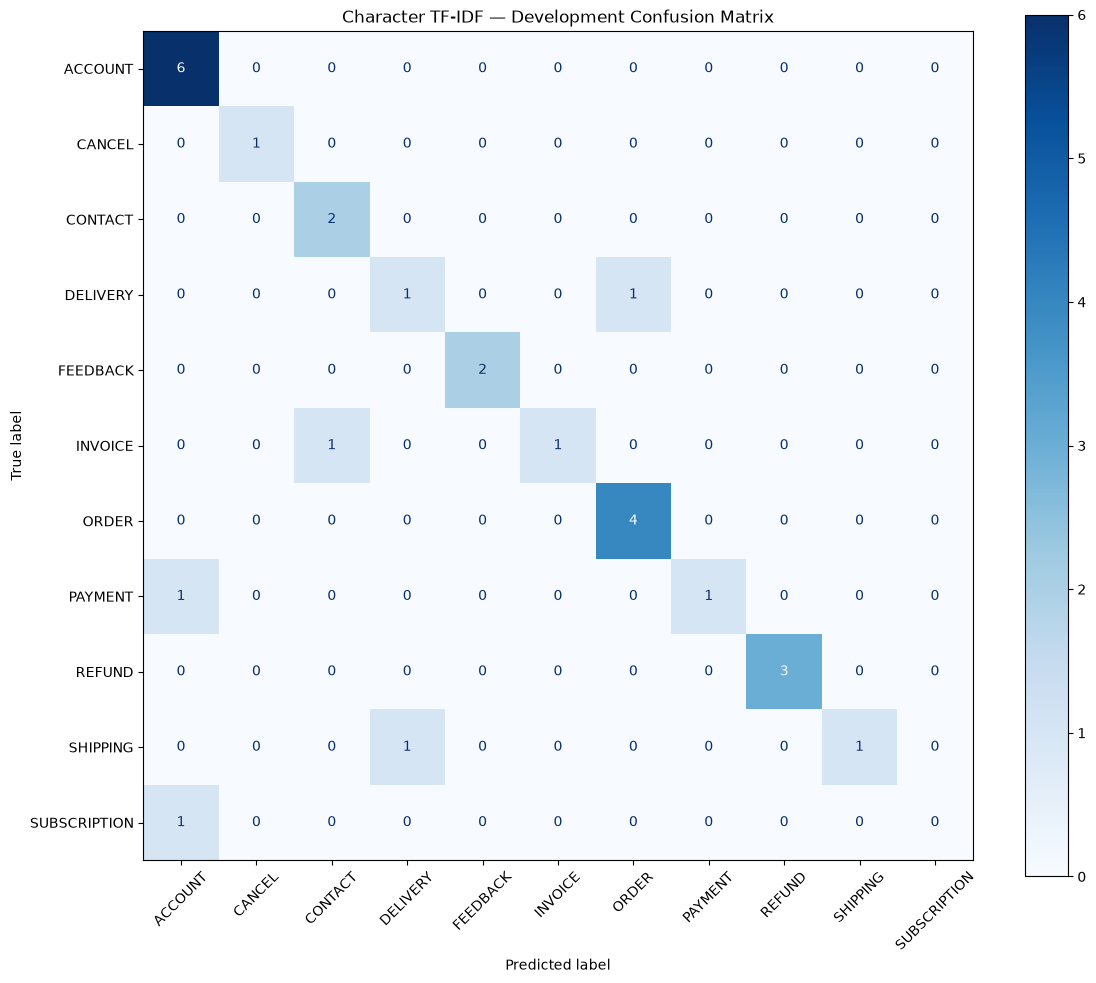

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

dev_predictions = char_baseline.predict(development_df["text"])

labels = sorted(development_df["expected_category"].unique())

cm = confusion_matrix(
    development_df["expected_category"],
    dev_predictions,
    labels=labels
)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(12, 10))

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Character TF-IDF — Development Confusion Matrix")
plt.tight_layout()
plt.show()

In [51]:
import pandas as pd
import numpy as np

dev_probabilities = char_baseline.predict_proba(
    development_df["text"]
)

dev_predictions = char_baseline.predict(
    development_df["text"]
)

max_confidence = dev_probabilities.max(axis=1)

dev_analysis = pd.DataFrame({
    "text": development_df["text"],
    "true_category": development_df["expected_category"],
    "predicted_category": dev_predictions,
    "confidence": max_confidence,
    "correct": (
        dev_predictions ==
        development_df["expected_category"]
    )
})

display(
    dev_analysis.sort_values(
        "confidence",
        ascending=False
    ).reset_index(drop=True)
)

,text,true_category,predicted_category,confidence,correct
0,How can I switch from my personal account to my business account?,ACCOUNT,ACCOUNT,0.979818,True
1,I can no longer access my profile because I forgot the security password,ACCOUNT,ACCOUNT,0.932748,True
2,I need to register a new profile before I can use the service,ACCOUNT,ACCOUNT,0.925907,True
3,I want to save an additional delivery address so I can select it during checkout,SHIPPING,SHIPPING,0.892656,True
4,The sign-up page keeps rejecting my details even though I filled everything in,ACCOUNT,ACCOUNT,0.831558,True
5,What steps should I follow to purchase something through your website?,ORDER,ORDER,0.790454,True
6,I want to submit an official complaint about the service I received,FEEDBACK,FEEDBACK,0.787320,True
7,Please close my membership profile permanently,ACCOUNT,ACCOUNT,0.773411,True
8,"Do you offer home delivery to my area, or is store pickup the only available option?",DELIVERY,DELIVERY,0.607843,True
9,The mobile number saved in my profile is no longer current; how do I update it?,ACCOUNT,ACCOUNT,0.606390,True


In [52]:
confidence_summary = (
    dev_analysis
    .groupby("correct")["confidence"]
    .agg(["count", "mean", "median", "min", "max"])
)

confidence_summary.index = [
    "Incorrect Predictions",
    "Correct Predictions"
]

display(confidence_summary)

,count,mean,median,min,max
Incorrect Predictions,5,0.284668,0.290838,0.229076,0.370928
Correct Predictions,22,0.579004,0.551954,0.175822,0.979818


In [53]:
calibration_data = dev_analysis.copy()

bins = np.linspace(0, 1, 6)

calibration_data["confidence_bin"] = pd.cut(
    calibration_data["confidence"],
    bins=bins,
    include_lowest=True
)

reliability_summary = (
    calibration_data
    .groupby("confidence_bin", observed=False)
    .agg(
        mean_confidence=("confidence", "mean"),
        accuracy=("correct", "mean"),
        sample_count=("correct", "count")
    )
)

display(reliability_summary)

,mean_confidence,accuracy,sample_count
confidence_bin,,,
"(-0.001, 0.2]",0.175822,1.000000,1
"(0.2, 0.4]",0.310401,0.545455,11
"(0.4, 0.6]",0.488619,1.000000,5
"(0.6, 0.8]",0.713084,1.000000,5
"(0.8, 1.0]",0.912538,1.000000,5


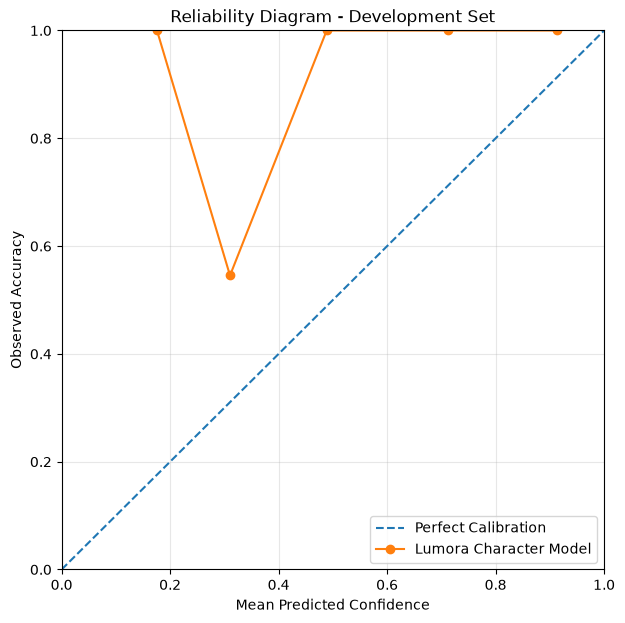

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.plot(
    reliability_summary["mean_confidence"],
    reliability_summary["accuracy"],
    marker="o",
    label="Lumora Character Model"
)

plt.xlabel("Mean Predicted Confidence")
plt.ylabel("Observed Accuracy")
plt.title("Reliability Diagram - Development Set")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [55]:
reliability_summary[
    ["mean_confidence", "accuracy", "sample_count"]
].round(3)

,mean_confidence,accuracy,sample_count
confidence_bin,,,
"(-0.001, 0.2]",0.176,1.000,1
"(0.2, 0.4]",0.310,0.545,11
"(0.4, 0.6]",0.489,1.000,5
"(0.6, 0.8]",0.713,1.000,5
"(0.8, 1.0]",0.913,1.000,5


In [56]:
from sklearn.base import clone

# Create an independent copy of the selected model
final_model = clone(char_baseline)

# Train on the complete original dataset
final_model.fit(X, y)

# Verify the final model
print("Final Model Training")
print("-" * 40)

print("Training samples:", len(X))
print("Number of classes:", len(final_model.named_steps["classifier"].classes_))

print("\nClasses:")
print(final_model.named_steps["classifier"].classes_)

print("\nNumber of learned character features:")
print(len(final_model.named_steps["tfidf"].vocabulary_))

print("\nModel training completed successfully.")

Final Model Training
----------------------------------------
Training samples: 26872
Number of classes: 11

Classes:
['ACCOUNT' 'CANCEL' 'CONTACT' 'DELIVERY' 'FEEDBACK' 'INVOICE' 'ORDER'
 'PAYMENT' 'REFUND' 'SHIPPING' 'SUBSCRIPTION']

Number of learned character features:
34970

Model training completed successfully.


In [57]:
# Load the untouched Locked Test benchmark
locked_test = pd.read_csv("../../data/benchmark/locked_test.csv")

# Prepare test inputs and true labels
X_locked = locked_test["text"]
y_locked = locked_test["expected_category"]

# Generate predictions
locked_predictions = final_model.predict(X_locked)

# Evaluate predictions
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("LOCKED TEST RESULTS")
print("=" * 45)

print("Samples:", len(X_locked))
print("Accuracy:", accuracy_score(y_locked, locked_predictions))
print("Macro Precision:", precision_score(
    y_locked, locked_predictions, average="macro", zero_division=0
))
print("Macro Recall:", recall_score(
    y_locked, locked_predictions, average="macro", zero_division=0
))
print("Macro F1:", f1_score(
    y_locked, locked_predictions, average="macro", zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_locked,
    locked_predictions,
    zero_division=0
))

LOCKED TEST RESULTS
Samples: 108
Accuracy: 0.7685185185185185
Macro Precision: 0.8389817519004121
Macro Recall: 0.7026515151515151
Macro F1: 0.7444253654217065

Classification Report:
              precision    recall  f1-score   support

     ACCOUNT       0.70      0.96      0.81        24
      CANCEL       1.00      0.50      0.67         4
     CONTACT       0.71      0.62      0.67         8
    DELIVERY       0.67      0.75      0.71         8
    FEEDBACK       1.00      0.88      0.93         8
     INVOICE       1.00      0.62      0.77         8
       ORDER       0.68      0.81      0.74        16
     PAYMENT       0.80      0.50      0.62         8
      REFUND       1.00      0.83      0.91        12
    SHIPPING       0.67      0.75      0.71         8
SUBSCRIPTION       1.00      0.50      0.67         4

    accuracy                           0.77       108
   macro avg       0.84      0.70      0.74       108
weighted avg       0.80      0.77      0.77       108



In [58]:
# Build a detailed prediction analysis
locked_analysis = locked_test[
    ["example_id", "text", "expected_category"]
].copy()

locked_analysis["predicted_category"] = locked_predictions

locked_analysis["correct"] = (
    locked_analysis["expected_category"]
    == locked_analysis["predicted_category"]
)

# Extract incorrect predictions
locked_errors = (
    locked_analysis[locked_analysis["correct"] == False]
    .reset_index(drop=True)
)

print("Incorrect Predictions:", len(locked_errors))
print("\nError Details:")

display(
    locked_errors[
        [
            "example_id",
            "text",
            "expected_category",
            "predicted_category"
        ]
    ]
)

Incorrect Predictions: 25

Error Details:


,example_id,text,expected_category,predicted_category
0,TST-013,Where can I change the email address attached to my login?,ACCOUNT,SHIPPING
1,TST-032,Can the delivery selection on my submitted order be adjusted?,ORDER,DELIVERY
2,TST-037,Has the parcel associated with my order left the warehouse?,ORDER,ACCOUNT
3,TST-039,"I received a dispatch notification several days ago, but I have no idea where the shipment is now.",ORDER,DELIVERY
4,TST-041,Is there a phone line or email address for general support?,CONTACT,SHIPPING
5,TST-043,Where should I send a question about my account?,CONTACT,ACCOUNT
6,TST-045,I need a live representative to help resolve this.,CONTACT,ACCOUNT
7,TST-049,The service issue I experienced needs to be formally reported.,FEEDBACK,ACCOUNT
8,TST-059,"Before I discontinue the service, I want to understand any early-exit costs.",CANCEL,CONTACT
9,TST-060,Would cancelling before renewal result in an additional fee?,CANCEL,ACCOUNT


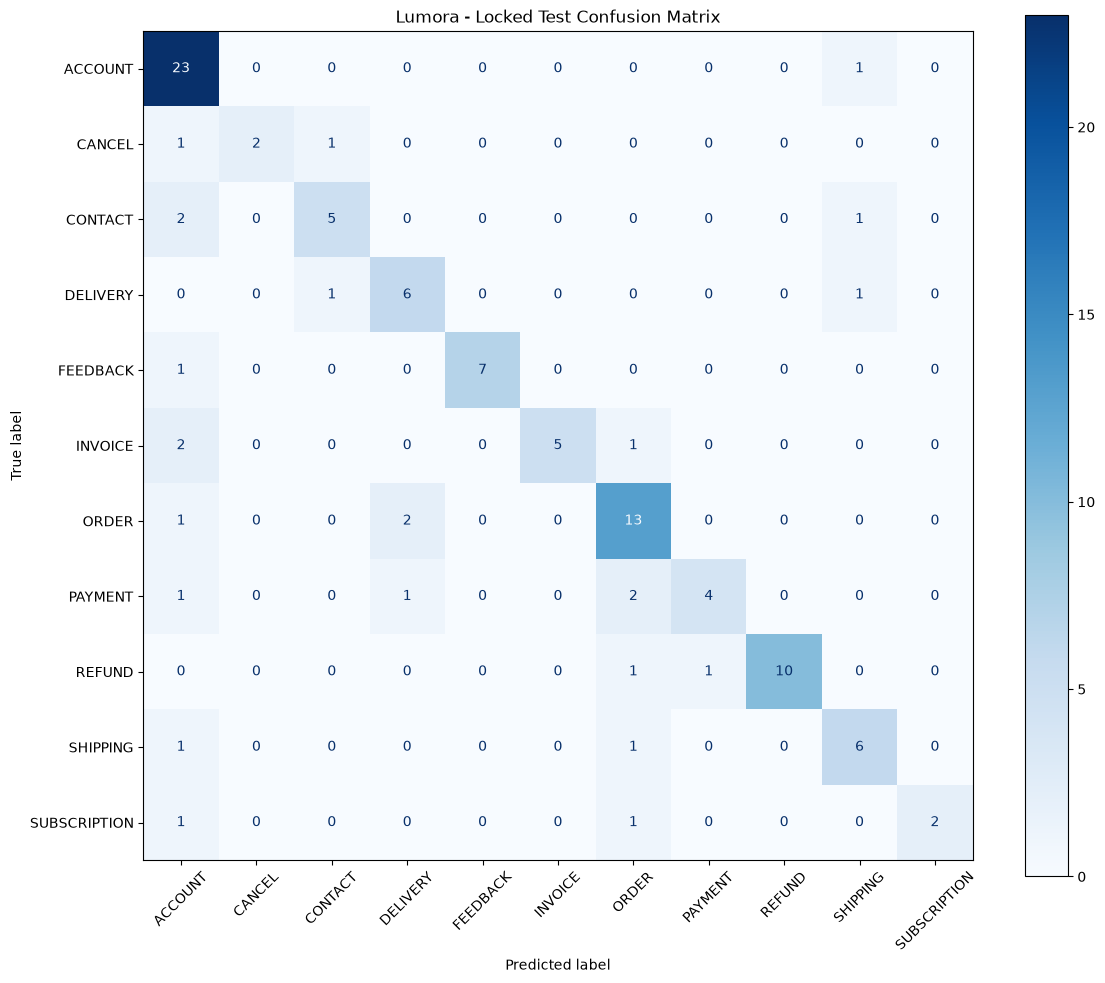

In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

class_labels = final_model.named_steps["classifier"].classes_

cm = confusion_matrix(
    y_locked,
    locked_predictions,
    labels=class_labels
)

fig, ax = plt.subplots(figsize=(12, 10))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_labels
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Lumora - Locked Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [60]:
import pandas as pd

confusion_table = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels]
)

display(confusion_table)

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [61]:
from IPython.display import display as show_table

confusion_table = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels]
)

show_table(confusion_table)

,Predicted: ACCOUNT,Predicted: CANCEL,Predicted: CONTACT,Predicted: DELIVERY,Predicted: FEEDBACK,Predicted: INVOICE,Predicted: ORDER,Predicted: PAYMENT,Predicted: REFUND,Predicted: SHIPPING,Predicted: SUBSCRIPTION
Actual: ACCOUNT,23,0,0,0,0,0,0,0,0,1,0
Actual: CANCEL,1,2,1,0,0,0,0,0,0,0,0
Actual: CONTACT,2,0,5,0,0,0,0,0,0,1,0
Actual: DELIVERY,0,0,1,6,0,0,0,0,0,1,0
Actual: FEEDBACK,1,0,0,0,7,0,0,0,0,0,0
Actual: INVOICE,2,0,0,0,0,5,1,0,0,0,0
Actual: ORDER,1,0,0,2,0,0,13,0,0,0,0
Actual: PAYMENT,1,0,0,1,0,0,2,4,0,0,0
Actual: REFUND,0,0,0,0,0,0,1,1,10,0,0
Actual: SHIPPING,1,0,0,0,0,0,1,0,0,6,0


In [62]:
# Get probability scores for all Locked Test predictions
locked_probabilities = final_model.predict_proba(X_locked)

# Add confidence to the analysis
locked_analysis["confidence"] = locked_probabilities.max(axis=1)

# Extract top 3 predicted classes for each error
top_3_indices = locked_probabilities.argsort(axis=1)[:, -3:][:, ::-1]

locked_errors_analysis = locked_analysis[
    ~locked_analysis["correct"]
].copy()

error_positions = locked_errors_analysis.index

locked_errors_analysis["top_3_predictions"] = [
    [
        (
            final_model.named_steps["classifier"].classes_[i],
            round(float(locked_probabilities[pos, i]), 4)
        )
        for i in top_3_indices[pos]
    ]
    for pos in error_positions
]

display(
    locked_errors_analysis[
        [
            "example_id",
            "text",
            "expected_category",
            "predicted_category",
            "confidence",
            "top_3_predictions"
        ]
    ].reset_index(drop=True)
)

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [63]:
from IPython.display import display as show_table

show_table(
    locked_errors_analysis[
        [
            "example_id",
            "text",
            "expected_category",
            "predicted_category",
            "confidence",
            "top_3_predictions"
        ]
    ].reset_index(drop=True)
)

,example_id,text,expected_category,predicted_category,confidence,top_3_predictions
0,TST-013,Where can I change the email address attached to my login?,ACCOUNT,SHIPPING,0.657974,"[(SHIPPING, 0.658), (ACCOUNT, 0.0946), (ORDER, 0.0457)]"
1,TST-032,Can the delivery selection on my submitted order be adjusted?,ORDER,DELIVERY,0.311922,"[(DELIVERY, 0.3119), (SHIPPING, 0.2453), (ORDER, 0.1266)]"
2,TST-037,Has the parcel associated with my order left the warehouse?,ORDER,ACCOUNT,0.319079,"[(ACCOUNT, 0.3191), (ORDER, 0.2349), (DELIVERY, 0.1162)]"
3,TST-039,"I received a dispatch notification several days ago, but I have no idea where the shipment is now.",ORDER,DELIVERY,0.288717,"[(DELIVERY, 0.2887), (ACCOUNT, 0.1594), (ORDER, 0.1348)]"
4,TST-041,Is there a phone line or email address for general support?,CONTACT,SHIPPING,0.416763,"[(SHIPPING, 0.4168), (CONTACT, 0.1374), (FEEDBACK, 0.0824)]"
5,TST-043,Where should I send a question about my account?,CONTACT,ACCOUNT,0.887232,"[(ACCOUNT, 0.8872), (FEEDBACK, 0.0283), (REFUND, 0.0176)]"
6,TST-045,I need a live representative to help resolve this.,CONTACT,ACCOUNT,0.329117,"[(ACCOUNT, 0.3291), (REFUND, 0.1568), (CONTACT, 0.1044)]"
7,TST-049,The service issue I experienced needs to be formally reported.,FEEDBACK,ACCOUNT,0.381204,"[(ACCOUNT, 0.3812), (FEEDBACK, 0.1343), (REFUND, 0.0992)]"
8,TST-059,"Before I discontinue the service, I want to understand any early-exit costs.",CANCEL,CONTACT,0.230588,"[(CONTACT, 0.2306), (ACCOUNT, 0.178), (CANCEL, 0.1354)]"
9,TST-060,Would cancelling before renewal result in an additional fee?,CANCEL,ACCOUNT,0.280660,"[(ACCOUNT, 0.2807), (ORDER, 0.1557), (CANCEL, 0.1183)]"


In [64]:
import pandas as pd

# Analyze training data coverage
coverage = (
    df.groupby(["category", "intent"])
    .agg(
        sample_count=("instruction", "size"),
        unique_instructions=("instruction", "nunique"),
        avg_instruction_length=("instruction", lambda x: x.str.split().str.len().mean())
    )
    .reset_index()
    .sort_values(["category", "sample_count"], ascending=[True, True])
)

display(coverage)

print("Total intents:", coverage["intent"].nunique())
print("Total training examples:", coverage["sample_count"].sum())
print("Intents with fewer than 100 examples:",
      (coverage["sample_count"] < 100).sum())

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [65]:
from IPython.display import display as show_table

show_table(coverage)

print("Total intents:", coverage["intent"].nunique())
print("Total training examples:", coverage["sample_count"].sum())
print(
    "Intents with fewer than 100 examples:",
    (coverage["sample_count"] < 100).sum()
)

,category,intent,sample_count,unique_instructions,avg_instruction_length
1,ACCOUNT,delete_account,995,918,9.020101
3,ACCOUNT,recover_password,995,995,9.084422
0,ACCOUNT,create_account,997,892,8.095286
4,ACCOUNT,registration_problems,999,999,8.619620
2,ACCOUNT,edit_account,1000,777,6.349000
5,ACCOUNT,switch_account,1000,862,8.527000
6,CANCEL,check_cancellation_fee,950,950,8.168421
8,CONTACT,contact_human_agent,999,999,8.119119
7,CONTACT,contact_customer_service,1000,1000,9.516000
9,DELIVERY,delivery_options,995,660,8.372864


Total intents: 27
Total training examples: 26872
Intents with fewer than 100 examples: 0


In [66]:
print("Columns:")
print(coverage.columns.tolist())

print("\nIndex:")
print(coverage.index)

print("\nData types:")
print(coverage.dtypes)

print("\nFirst 5 rows:")
show_table(coverage.head())

Columns:
['category', 'intent', 'sample_count', 'unique_instructions', 'avg_instruction_length']

Index:
Index([ 1,  3,  0,  4,  2,  5,  6,  8,  7,  9, 10, 12, 11, 14, 13, 18, 16, 15,
       17, 19, 20, 21, 22, 23, 24, 25, 26],
      dtype='int64')

Data types:
category                      str
intent                        str
sample_count                int64
unique_instructions         int64
avg_instruction_length    float64
dtype: object

First 5 rows:


,category,intent,sample_count,unique_instructions,avg_instruction_length
1,ACCOUNT,delete_account,995,918,9.020101
3,ACCOUNT,recover_password,995,995,9.084422
0,ACCOUNT,create_account,997,892,8.095286
4,ACCOUNT,registration_problems,999,999,8.619620
2,ACCOUNT,edit_account,1000,777,6.349000


In [67]:
# Normalize customer instructions
coverage_data = df.copy()

coverage_data["normalized_instruction"] = (
    coverage_data["instruction"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

# Analyze repetition within each intent
repetition_analysis = (
    coverage_data
    .groupby(["category", "intent"])
    .agg(
        total_samples=("instruction", "size"),
        unique_raw=("instruction", "nunique"),
        unique_normalized=("normalized_instruction", "nunique")
    )
    .reset_index()
)

repetition_analysis["normalized_repetition_rate"] = (
    1 - repetition_analysis["unique_normalized"]
    / repetition_analysis["total_samples"]
) * 100

repetition_analysis = repetition_analysis.sort_values(
    "normalized_repetition_rate",
    ascending=False
)

show_table(
    repetition_analysis.round(2)
)

print(
    "\nOverall normalized repetition rate:",
    round(
        (1 - coverage_data["normalized_instruction"].nunique()
         / len(coverage_data)) * 100,
        2
    ),
    "%"
)

,category,intent,total_samples,unique_raw,unique_normalized,normalized_repetition_rate
15,ORDER,cancel_order,998,493,436,56.31
9,DELIVERY,delivery_options,995,660,655,34.17
23,REFUND,track_refund,998,707,692,30.66
2,ACCOUNT,edit_account,1000,777,766,23.40
18,ORDER,track_order,995,807,783,21.31
5,ACCOUNT,switch_account,1000,862,836,16.40
16,ORDER,change_order,997,870,856,14.14
0,ACCOUNT,create_account,997,892,875,12.24
14,INVOICE,get_invoice,999,909,888,11.11
1,ACCOUNT,delete_account,995,918,901,9.45



Overall normalized repetition rate: 9.67 %


In [68]:
# Inspect the most repeated instructions in cancel_order

cancel_examples = coverage_data[
    coverage_data["intent"] == "cancel_order"
]

cancel_frequency = (
    cancel_examples
    .groupby("normalized_instruction")
    .agg(
        occurrences=("instruction", "size"),
        original_variations=("instruction", "nunique")
    )
    .reset_index()
    .sort_values("occurrences", ascending=False)
)

show_table(cancel_frequency.head(15))

print("\nTotal normalized unique instructions:",
      cancel_frequency.shape[0])

print("Instructions appearing more than once:",
      (cancel_frequency["occurrences"] > 1).sum())

,normalized_instruction,occurrences,original_variations
43,cancel purchase {{order number}},9,2
282,i need help cancelling purchase {{order number}},8,2
338,i want help to cancel purchase {{order number}},8,2
267,i need assistance cancelling purchase {{order number}},8,2
270,i need assistance to cancel order {{order number}},7,2
285,i need help to cancel purchase {{order number}},7,2
335,i want help cancelling purchase {{order number}},7,2
253,i have problems with cancelling purchase {{order number}},7,3
329,i want assistance to cancel purchase {{order number}},7,2
131,i can no longer afford purchase {{order number}},7,2



Total normalized unique instructions: 436
Instructions appearing more than once: 201


In [69]:
import re

# Normalize placeholders and variable values
def normalize_template(text):
    text = str(text).lower().strip()

    # Normalize placeholders
    text = re.sub(r"\{\{.*?\}\}", "<variable>", text)

    # Normalize email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b",
        "<email>",
        text
    )

    # Normalize standalone numbers
    text = re.sub(r"\b\d+\b", "<number>", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text)

    return text


coverage_data["template_instruction"] = (
    coverage_data["instruction"].apply(normalize_template)
)

template_analysis = (
    coverage_data
    .groupby(["category", "intent"])
    .agg(
        total_samples=("instruction", "size"),
        unique_normalized=("normalized_instruction", "nunique"),
        unique_templates=("template_instruction", "nunique")
    )
    .reset_index()
)

template_analysis["template_repetition_rate"] = (
    1 - template_analysis["unique_templates"]
    / template_analysis["total_samples"]
) * 100

template_analysis = template_analysis.sort_values(
    "template_repetition_rate",
    ascending=False
)

show_table(template_analysis.round(2))

,category,intent,total_samples,unique_normalized,unique_templates,template_repetition_rate
15,ORDER,cancel_order,998,436,436,56.31
9,DELIVERY,delivery_options,995,655,641,35.58
23,REFUND,track_refund,998,692,692,30.66
2,ACCOUNT,edit_account,1000,766,699,30.10
14,INVOICE,get_invoice,999,888,760,23.92
5,ACCOUNT,switch_account,1000,836,773,22.70
18,ORDER,track_order,995,783,783,21.31
0,ACCOUNT,create_account,997,875,812,18.56
16,ORDER,change_order,997,856,856,14.14
13,INVOICE,check_invoice,1000,913,863,13.70


In [70]:
show_table(intent_similarity.head(20).round(4))

NameError: name 'intent_similarity' is not defined

In [71]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# 1. Combine instructions belonging to each intent
intent_texts = (
    df.groupby("intent")["instruction"]
    .apply(lambda x: " ".join(x.astype(str)))
)

intent_names = intent_texts.index.tolist()

# 2. Convert intent text into TF-IDF features
intent_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    stop_words="english",
    min_df=1
)

intent_matrix = intent_vectorizer.fit_transform(intent_texts)

# 3. Calculate pairwise similarity
similarity_matrix = cosine_similarity(intent_matrix)

# 4. Build comparison table
similarity_results = []

for i in range(len(intent_names)):
    for j in range(i + 1, len(intent_names)):
        similarity_results.append({
            "intent_1": intent_names[i],
            "intent_2": intent_names[j],
            "similarity": similarity_matrix[i, j]
        })

intent_similarity = pd.DataFrame(similarity_results)

intent_similarity = intent_similarity.sort_values(
    "similarity",
    ascending=False
).reset_index(drop=True)

# 5. Display results
show_table(intent_similarity.head(20).round(4))

print("\nTotal intent pairs:", len(intent_similarity))

,intent_1,intent_2,similarity
0,cancel_order,change_order,0.8994
1,change_order,track_order,0.8790
2,create_account,delete_account,0.8431
3,delete_account,switch_account,0.8366
4,cancel_order,track_order,0.8356
5,delete_account,edit_account,0.8056
6,change_shipping_address,set_up_shipping_address,0.7866
7,create_account,switch_account,0.7681
8,edit_account,switch_account,0.7525
9,create_account,edit_account,0.7462



Total intent pairs: 351


In [72]:
# Map each intent to its category
intent_category_map = (
    df[["intent", "category"]]
    .drop_duplicates()
)

# Add category information to similarity results
cross_category_similarity = (
    intent_similarity
    .merge(
        intent_category_map,
        left_on="intent_1",
        right_on="intent"
    )
    .rename(columns={"category": "category_1"})
    .drop(columns="intent")
    .merge(
        intent_category_map,
        left_on="intent_2",
        right_on="intent"
    )
    .rename(columns={"category": "category_2"})
    .drop(columns="intent")
)

# Keep only pairs belonging to different categories
cross_category_similarity = (
    cross_category_similarity[
        cross_category_similarity["category_1"]
        != cross_category_similarity["category_2"]
    ]
    .sort_values("similarity", ascending=False)
    .reset_index(drop=True)
)

show_table(cross_category_similarity.head(20).round(4))

print(
    "\nTotal cross-category intent pairs:",
    len(cross_category_similarity)
)

,intent_1,intent_2,similarity,category_1,category_2
0,payment_issue,registration_problems,0.3387,PAYMENT,ACCOUNT
1,delivery_options,set_up_shipping_address,0.1958,DELIVERY,SHIPPING
2,check_payment_methods,delivery_options,0.1722,PAYMENT,DELIVERY
3,complaint,contact_customer_service,0.1691,FEEDBACK,CONTACT
4,change_shipping_address,delivery_options,0.1573,SHIPPING,DELIVERY
5,delivery_period,place_order,0.1256,DELIVERY,ORDER
6,place_order,review,0.1185,ORDER,FEEDBACK
7,contact_human_agent,get_invoice,0.1108,CONTACT,INVOICE
8,track_order,track_refund,0.1086,ORDER,REFUND
9,check_invoice,contact_human_agent,0.1058,INVOICE,CONTACT



Total cross-category intent pairs: 321


In [73]:
# Inspect actual examples from the two most similar cross-category intents

selected_intents = [
    "payment_issue",
    "registration_problems"
]

for intent_name in selected_intents:
    examples = (
        df.loc[
            df["intent"] == intent_name,
            ["category", "intent", "instruction"]
        ]
        .sample(n=12, random_state=42)
        .reset_index(drop=True)
    )

    print(f"\n{'=' * 70}")
    print(f"INTENT: {intent_name}")
    print(f"{'=' * 70}")

    show_table(examples)


INTENT: payment_issue


,category,intent,instruction
0,PAYMENT,payment_issue,can you help me reporting problems with online payment?
1,PAYMENT,payment_issue,assistance to notify of issues with online payments
2,PAYMENT,payment_issue,i cant make payments how to inform of issues with payment
3,PAYMENT,payment_issue,"I cannot make a payment, I want help to report a problem"
4,PAYMENT,payment_issue,how do I notify of an issue with payment?
5,PAYMENT,payment_issue,where do i inform of a trouble with payments
6,PAYMENT,payment_issue,"the payment did not go through, report an error"
7,PAYMENT,payment_issue,"the payment failed, how to report an error with payment?"
8,PAYMENT,payment_issue,i dont know what i have to do to report issues with payments
9,PAYMENT,payment_issue,notify of trouble with online payments



INTENT: registration_problems


,category,intent,instruction
0,ACCOUNT,registration_problems,i dont know how to report signup issues
1,ACCOUNT,registration_problems,assistance opening user account
2,ACCOUNT,registration_problems,need assistance to notify of errors with a registration
3,ACCOUNT,registration_problems,help to inform of a problem with a registration
4,ACCOUNT,registration_problems,"I cannot open a user, I have to inform of a signup issue"
5,ACCOUNT,registration_problems,help me to inform of a registration issue
6,ACCOUNT,registration_problems,i cannot sign up i need to report sign-up problems
7,ACCOUNT,registration_problems,i want help regarding my sign-up
8,ACCOUNT,registration_problems,assistance informing of an error with a signup
9,ACCOUNT,registration_problems,help me to informof an issue with a registration


In [74]:
# Fresh, manually authored customer messages
realistic_messages = [
    "My card was charged but my order was never confirmed.",
    "I keep getting an error when I try to create my account.",
    "Why does my payment fail every time I check out?",
    "I cannot register because the website says my email is already in use.",
    "The money was deducted from my account but the payment still shows as pending.",
    "I entered all my details but the sign up button does nothing.",
    "Can I pay using Apple Pay or a credit card?",
    "I cannot log into my account after changing my password.",
    "The checkout page keeps rejecting my card.",
    "I never received the confirmation email after registration.",
    "I was charged twice for the same purchase.",
    "How can I update my billing information?"
]

# Predict categories and probabilities
message_probabilities = final_model.predict_proba(realistic_messages)
message_predictions = final_model.predict(realistic_messages)

# Build readable results
prediction_results = []

for i, message in enumerate(realistic_messages):
    prediction_results.append({
        "message": message,
        "predicted_category": message_predictions[i],
        "confidence": message_probabilities[i].max()
    })

prediction_table = pd.DataFrame(prediction_results)

show_table(
    prediction_table.round({"confidence": 4})
)

,message,predicted_category,confidence
0,My card was charged but my order was never confirmed.,ORDER,0.3034
1,I keep getting an error when I try to create my account.,ACCOUNT,0.9083
2,Why does my payment fail every time I check out?,PAYMENT,0.5714
3,I cannot register because the website says my email is already in use.,ACCOUNT,0.7326
4,The money was deducted from my account but the payment still shows as pending.,PAYMENT,0.3469
5,I entered all my details but the sign up button does nothing.,ACCOUNT,0.6017
6,Can I pay using Apple Pay or a credit card?,ACCOUNT,0.2766
7,I cannot log into my account after changing my password.,ACCOUNT,0.9468
8,The checkout page keeps rejecting my card.,ACCOUNT,0.2705
9,I never received the confirmation email after registration.,ACCOUNT,0.6391


In [75]:
# Examine the full probability distribution for each message

probability_details = final_model.predict_proba(realistic_messages)
model_classes = final_model.classes_

probability_rows = []

for i, message in enumerate(realistic_messages):

    probabilities = probability_details[i]

    top_indices = np.argsort(probabilities)[::-1][:3]

    probability_rows.append({
        "message_id": i,
        "message": message,
        "top_1": model_classes[top_indices[0]],
        "top_1_probability": probabilities[top_indices[0]],
        "top_2": model_classes[top_indices[1]],
        "top_2_probability": probabilities[top_indices[1]],
        "top_3": model_classes[top_indices[2]],
        "top_3_probability": probabilities[top_indices[2]],
        "probability_gap": (
            probabilities[top_indices[0]]
            - probabilities[top_indices[1]]
        )
    })

probability_analysis = pd.DataFrame(probability_rows)

show_table(
    probability_analysis.round({
        "top_1_probability": 4,
        "top_2_probability": 4,
        "top_3_probability": 4,
        "probability_gap": 4
    })
)

,message_id,message,top_1,top_1_probability,top_2,top_2_probability,top_3,top_3_probability,probability_gap
0,0,My card was charged but my order was never confirmed.,ORDER,0.3034,ACCOUNT,0.1817,FEEDBACK,0.0895,0.1217
1,1,I keep getting an error when I try to create my account.,ACCOUNT,0.9083,SHIPPING,0.0152,PAYMENT,0.0137,0.8931
2,2,Why does my payment fail every time I check out?,PAYMENT,0.5714,DELIVERY,0.0916,ACCOUNT,0.0562,0.4798
3,3,I cannot register because the website says my email is already in use.,ACCOUNT,0.7326,REFUND,0.0477,ORDER,0.0371,0.6848
4,4,The money was deducted from my account but the payment still shows as pending.,PAYMENT,0.3469,ACCOUNT,0.2775,REFUND,0.1178,0.0694
5,5,I entered all my details but the sign up button does nothing.,ACCOUNT,0.6017,SHIPPING,0.0635,ORDER,0.0617,0.5381
6,6,Can I pay using Apple Pay or a credit card?,ACCOUNT,0.2766,PAYMENT,0.2402,ORDER,0.1036,0.0364
7,7,I cannot log into my account after changing my password.,ACCOUNT,0.9468,SHIPPING,0.0101,ORDER,0.0082,0.9367
8,8,The checkout page keeps rejecting my card.,ACCOUNT,0.2705,REFUND,0.1583,DELIVERY,0.1080,0.1122
9,9,I never received the confirmation email after registration.,ACCOUNT,0.6391,REFUND,0.0957,FEEDBACK,0.0467,0.5434


In [76]:
# Test paraphrase robustness

paraphrase_groups = {
    "payment_failure": [
        "My payment failed during checkout.",
        "The checkout process rejected my payment.",
        "I cannot complete my purchase because the payment is not working.",
        "Why is my card being declined when I try to pay?",
        "I am having trouble paying for my order.",
        "The payment transaction keeps failing."
    ],

    "registration_problem": [
        "I cannot create an account.",
        "The registration process is not working.",
        "I am unable to sign up on the website.",
        "The website gives me an error when I register.",
        "I am having trouble creating a new account.",
        "My account registration keeps failing."
    ],

    "payment_method_question": [
        "Which payment methods do you accept?",
        "Can I use Apple Pay to pay for my order?",
        "Do you accept credit cards?",
        "What payment options are available?",
        "Can I pay using a debit card?",
        "Is PayPal accepted at checkout?"
    ]
}

paraphrase_results = []

for intent_name, messages in paraphrase_groups.items():

    predictions = final_model.predict(messages)
    probabilities = final_model.predict_proba(messages)

    for message, prediction, probability in zip(
        messages,
        predictions,
        probabilities
    ):
        top_indices = np.argsort(probability)[::-1][:2]

        paraphrase_results.append({
            "group": intent_name,
            "message": message,
            "predicted_category": prediction,
            "confidence": probability[top_indices[0]],
            "second_category": final_model.classes_[top_indices[1]],
            "second_probability": probability[top_indices[1]],
            "probability_gap": (
                probability[top_indices[0]]
                - probability[top_indices[1]]
            )
        })

paraphrase_df = pd.DataFrame(paraphrase_results)

show_table(
    paraphrase_df.round({
        "confidence": 4,
        "second_probability": 4,
        "probability_gap": 4
    })
)

,group,message,predicted_category,confidence,second_category,second_probability,probability_gap
0,payment_failure,My payment failed during checkout.,PAYMENT,0.8494,REFUND,0.0223,0.8270
1,payment_failure,The checkout process rejected my payment.,PAYMENT,0.7128,ACCOUNT,0.0711,0.6418
2,payment_failure,I cannot complete my purchase because the payment is not working.,PAYMENT,0.5428,ORDER,0.1275,0.4153
3,payment_failure,Why is my card being declined when I try to pay?,ACCOUNT,0.1718,DELIVERY,0.1693,0.0025
4,payment_failure,I am having trouble paying for my order.,ACCOUNT,0.2212,ORDER,0.2179,0.0033
5,payment_failure,The payment transaction keeps failing.,PAYMENT,0.8646,ACCOUNT,0.0238,0.8407
6,registration_problem,I cannot create an account.,ACCOUNT,0.9458,ORDER,0.0112,0.9346
7,registration_problem,The registration process is not working.,ACCOUNT,0.8125,REFUND,0.0460,0.7665
8,registration_problem,I am unable to sign up on the website.,ACCOUNT,0.5154,REFUND,0.0838,0.4316
9,registration_problem,The website gives me an error when I register.,ACCOUNT,0.6467,DELIVERY,0.0710,0.5757


In [77]:
# Inspect the most influential character features
# for PAYMENT and ACCOUNT classes.

classifier = final_model.named_steps["classifier"]
vectorizer = final_model.named_steps["tfidf"]

feature_names = vectorizer.get_feature_names_out()
classes = classifier.classes_

selected_classes = ["PAYMENT", "ACCOUNT"]

for class_name in selected_classes:

    class_index = np.where(classes == class_name)[0][0]

    coefficients = classifier.coef_[class_index]

    top_indices = np.argsort(coefficients)[::-1][:25]

    feature_table = pd.DataFrame({
        "character_feature": feature_names[top_indices],
        "coefficient": coefficients[top_indices]
    })

    print(f"\n{'=' * 60}")
    print(f"CLASS: {class_name}")
    print(f"{'=' * 60}")

    show_table(feature_table.round({"coefficient": 4}))


CLASS: PAYMENT


,character_feature,coefficient
0,pay,3.7662
1,pay,3.6991
2,aym,3.5585
3,paym,3.5550
4,yme,3.5414
5,ymen,3.5187
6,yment,3.4932
7,paym,3.4861
8,pa,3.4787
9,ayme,3.4490



CLASS: ACCOUNT


,character_feature,coefficient
0,acc,2.8761
1,cco,2.7956
2,acco,2.7918
3,coun,2.7140
4,count,2.6939
5,ccou,2.6794
6,accou,2.6756
7,ccoun,2.6651
8,unt,2.6231
9,oun,2.5441


In [78]:
# Test the model's dependence on explicit keywords

keyword_tests = [
    {
        "original": "I have a problem with my payment.",
        "modified": "I have a problem with this transaction."
    },
    {
        "original": "My payment failed during checkout.",
        "modified": "The transaction failed during checkout."
    },
    {
        "original": "I cannot create my account.",
        "modified": "I cannot complete my registration."
    },
    {
        "original": "I have an account registration problem.",
        "modified": "I have a problem signing up."
    },
    {
        "original": "My card payment was declined.",
        "modified": "My card was declined during checkout."
    },
    {
        "original": "I cannot pay for my order.",
        "modified": "I cannot complete my purchase."
    }
]

test_rows = []

for item in keyword_tests:

    messages = [item["original"], item["modified"]]

    predictions = final_model.predict(messages)
    probabilities = final_model.predict_proba(messages)

    for version, message, prediction, probability in zip(
        ["original", "modified"],
        messages,
        predictions,
        probabilities
    ):
        top_indices = np.argsort(probability)[::-1][:2]

        test_rows.append({
            "version": version,
            "message": message,
            "predicted_category": prediction,
            "confidence": probability[top_indices[0]],
            "second_category": final_model.classes_[top_indices[1]],
            "second_probability": probability[top_indices[1]]
        })

keyword_test_results = pd.DataFrame(test_rows)

show_table(
    keyword_test_results.round({
        "confidence": 4,
        "second_probability": 4
    })
)

,version,message,predicted_category,confidence,second_category,second_probability
0,original,I have a problem with my payment.,PAYMENT,0.8815,ACCOUNT,0.0840
1,modified,I have a problem with this transaction.,ACCOUNT,0.5132,CONTACT,0.0977
2,original,My payment failed during checkout.,PAYMENT,0.8494,REFUND,0.0223
3,modified,The transaction failed during checkout.,ACCOUNT,0.1792,REFUND,0.1579
4,original,I cannot create my account.,ACCOUNT,0.9825,REFUND,0.0027
5,modified,I cannot complete my registration.,ACCOUNT,0.8785,REFUND,0.0437
6,original,I have an account registration problem.,ACCOUNT,0.9971,FEEDBACK,0.0006
7,modified,I have a problem signing up.,ACCOUNT,0.8473,ORDER,0.0300
8,original,My card payment was declined.,PAYMENT,0.8546,ORDER,0.0224
9,modified,My card was declined during checkout.,ACCOUNT,0.1805,REFUND,0.1297


In [81]:
import importlib.util
from pathlib import Path
import os

# Check whether required libraries are installed
packages = [
    "sentence_transformers",
    "transformers",
    "torch",
    "huggingface_hub"
]

print("INSTALLED PACKAGES")
print("=" * 45)

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Not installed'}")


# Check available Hugging Face model cache
cache_path = Path.home() / ".cache" / "huggingface" / "hub"

print("\nMODEL CACHE")
print("=" * 45)

if cache_path.exists():
    cached_models = [
        path.name
        for path in cache_path.iterdir()
        if path.is_dir()
    ]

    if cached_models:
        for model in cached_models:
            print(model)
    else:
        print("No cached models found.")
else:
    print("Hugging Face cache directory does not exist.")


# Check available memory information
print("\nENVIRONMENT")
print("=" * 45)

print("Python:", os.sys.version.split()[0])
print("Project working directory:", os.getcwd())

INSTALLED PACKAGES
sentence_transformers: Not installed
transformers: Not installed
torch: Not installed
huggingface_hub: Not installed

MODEL CACHE
Hugging Face cache directory does not exist.

ENVIRONMENT
Python: 3.12.7
Project working directory: /Users/raghad/Desktop/Lumora/notebooks/ml


In [82]:
import torch
import sentence_transformers

print("PyTorch:", torch.__version__)
print("Sentence Transformers:", sentence_transformers.__version__)

print("MPS available:", torch.backends.mps.is_available())
print("CUDA available:", torch.cuda.is_available())

/Users/raghad/Desktop/Lumora/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 16:22:04.223000 9698 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


PyTorch: 2.15.0
Sentence Transformers: 6.2.0
MPS available: True
CUDA available: False


In [83]:
from sentence_transformers import SentenceTransformer

embedding_model_name = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(
    embedding_model_name,
    device="mps"
)

print("Model loaded successfully.")
print("Model:", embedding_model_name)
print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())
print("Device:", embedding_model.device)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13082.59it/s]


Model loaded successfully.
Model: sentence-transformers/all-MiniLM-L6-v2
Embedding dimension: 384
Device: mps:0


/var/folders/b0/n2mx6szd13543s36zvr2sfrh0000gn/T/ipykernel_9698/3366431784.py:12: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", embedding_model.get_sentence_embedding_dimension())


In [84]:
sample_texts = df["instruction"].head(5).tolist()

sample_embeddings = embedding_model.encode(
    sample_texts,
    batch_size=5,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=False
)

print("Number of messages:", len(sample_texts))
print("Embeddings shape:", sample_embeddings.shape)
print("Data type:", sample_embeddings.dtype)
print("First embedding (first 10 values):")
print(sample_embeddings[0][:10])

Number of messages: 5
Embeddings shape: (5, 384)
Data type: float32
First embedding (first 10 values):
[-0.06532242  0.08452144  0.10246464  0.03392778 -0.04188797  0.02350871
  0.00772556 -0.07428649  0.10199016  0.04596752]


In [85]:
import numpy as np
import time

embedding_start = time.time()

X_embeddings = embedding_model.encode(
    df["instruction"].astype(str).tolist(),
    batch_size=32,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

embedding_elapsed = time.time() - embedding_start

print("\nEmbedding generation completed.")
print("Embeddings shape:", X_embeddings.shape)
print("Data type:", X_embeddings.dtype)
print("Total messages:", len(X_embeddings))
print("Generation time:", round(embedding_elapsed, 2), "seconds")

# Verify that all embeddings are valid
print("Contains NaN:", np.isnan(X_embeddings).any())
print("Contains infinite values:", np.isinf(X_embeddings).any())

# Verify normalized vector lengths
embedding_norms = np.linalg.norm(X_embeddings, axis=1)

print("Average vector norm:", round(embedding_norms.mean(), 4))
print("Minimum vector norm:", round(embedding_norms.min(), 4))
print("Maximum vector norm:", round(embedding_norms.max(), 4))

Batches: 100%|██████████| 840/840 [00:27<00:00, 30.34it/s]



Embedding generation completed.
Embeddings shape: (26872, 384)
Data type: float32
Total messages: 26872
Generation time: 27.98 seconds
Contains NaN: False
Contains infinite values: False
Average vector norm: 1.0
Minimum vector norm: 1.0
Maximum vector norm: 1.0


In [86]:
print("DataFrame shape:", df.shape)
print("Embeddings shape:", X_embeddings.shape)

print("\nTarget distribution:")
print(df["category"].value_counts())

print("\nAvailable split variables:")
for name in [
    "cv",
    "skf",
    "sgkf",
    "groups",
    "normalized_groups",
    "X",
    "y"
]:
    print(f"{name}: {name in globals()}")

DataFrame shape: (26872, 5)
Embeddings shape: (26872, 384)

Target distribution:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         1999
CONTACT         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64

Available split variables:
cv: True
skf: False
sgkf: False
groups: True
normalized_groups: False
X: True
y: True


In [87]:
print("Cross-validation object:")
print(cv)

print("\nNumber of folds:", cv.n_splits)

print("\nGroups information:")
print("Number of samples:", len(groups))
print("Number of unique groups:", len(np.unique(groups)))

print("\nTarget information:")
print("Number of labels:", y.nunique() if hasattr(y, "nunique") else len(np.unique(y)))
print("Number of samples:", len(y))

print("\nAlignment checks:")
print("df and embeddings:", len(df) == len(X_embeddings))
print("df and y:", len(df) == len(y))
print("df and groups:", len(df) == len(groups))

Cross-validation object:
StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)

Number of folds: 5

Groups information:
Number of samples: 26872
Number of unique groups: 24274

Target information:
Number of labels: 11
Number of samples: 26872

Alignment checks:
df and embeddings: True
df and y: True
df and groups: True


In [88]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

embedding_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

embedding_scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

embedding_cv_results = cross_validate(
    embedding_classifier,
    X_embeddings,
    y,
    cv=cv,
    groups=groups,
    scoring=embedding_scoring,
    return_train_score=True,
    n_jobs=1
)

print("Sentence Embeddings + Logistic Regression")
print("=" * 55)

for metric in embedding_scoring:
    train_metric = f"train_{metric}"
    test_metric = f"test_{metric}"

    print(
        f"{metric}: "
        f"{embedding_cv_results[test_metric].mean():.4f} "
        f"+/- {embedding_cv_results[test_metric].std():.4f}"
    )

print("\nTraining scores:")
for metric in embedding_scoring:
    print(
        f"{metric}: "
        f"{embedding_cv_results[f'train_{metric}'].mean():.4f}"
    )

Sentence Embeddings + Logistic Regression
accuracy: 0.9981 +/- 0.0008
precision_macro: 0.9982 +/- 0.0007
recall_macro: 0.9979 +/- 0.0009
f1_macro: 0.9980 +/- 0.0008
f1_weighted: 0.9981 +/- 0.0008

Training scores:
accuracy: 0.9988
precision_macro: 0.9989
recall_macro: 0.9988
f1_macro: 0.9989
f1_weighted: 0.9988


In [89]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression

embedding_oof_predictions = cross_val_predict(
    LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    X_embeddings,
    y,
    cv=cv,
    groups=groups,
    method="predict",
    n_jobs=1
)

print("Sentence Embeddings - Out-of-Fold Evaluation")
print("=" * 55)

print(classification_report(
    y,
    embedding_oof_predictions,
    zero_division=0
))

embedding_errors = df.loc[
    np.asarray(y) != embedding_oof_predictions,
    ["instruction", "category", "intent"]
].copy()

embedding_errors["predicted_category"] = np.asarray(
    embedding_oof_predictions
)[np.asarray(y) != embedding_oof_predictions]

print("\nNumber of errors:", len(embedding_errors))
display(embedding_errors.head(20))

Sentence Embeddings - Out-of-Fold Evaluation
              precision    recall  f1-score   support

     ACCOUNT       1.00      1.00      1.00      5986
      CANCEL       1.00      1.00      1.00       950
     CONTACT       1.00      1.00      1.00      1999
    DELIVERY       0.99      1.00      1.00      1994
    FEEDBACK       1.00      0.99      1.00      1997
     INVOICE       1.00      1.00      1.00      1999
       ORDER       1.00      1.00      1.00      3988
     PAYMENT       1.00      1.00      1.00      1998
      REFUND       1.00      1.00      1.00      2992
    SHIPPING       1.00      1.00      1.00      1970
SUBSCRIPTION       1.00      1.00      1.00       999

    accuracy                           1.00     26872
   macro avg       1.00      1.00      1.00     26872
weighted avg       1.00      1.00      1.00     26872


Number of errors: 52


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [90]:
print("Number of errors:", len(embedding_errors))

show_table(embedding_errors.head(20))

Number of errors: 52


,instruction,category,intent,predicted_category
1443,could you help me to delete something?,ORDER,change_order,ACCOUNT
2114,I want help trying to edit my addreds,SHIPPING,change_shipping_address,ACCOUNT
2361,I chose a wrong delivery addreds,SHIPPING,change_shipping_address,DELIVERY
2643,wanna correct the acdress can uhelp me,SHIPPING,change_shipping_address,ACCOUNT
3924,i need assistance giving a quick look at the bvill #37777,INVOICE,check_invoice,ORDER
4259,i have to find the biol #12588 how to do it,INVOICE,check_invoice,ORDER
4684,I need help checking the biol #37777,INVOICE,check_invoice,ACCOUNT
5597,can uhelp me check what damn pamyent options are accepted,PAYMENT,check_payment_methods,ACCOUNT
6070,I need to check how long rimbursements take,REFUND,check_refund_policy,DELIVERY
6586,I need help checking how long rdimbursements take,REFUND,check_refund_policy,DELIVERY


In [91]:
print("Character model available:", "char_baseline" in globals())
print("Embedding model available:", "embedding_model" in globals())
print("Embedding classifier available:", "embedding_classifier" in globals())
print("Diagnostic test variables:")
for name in ["diagnostic_df", "manual_test", "test_messages"]:
    print(name, ":", name in globals())

Character model available: True
Embedding model available: True
Embedding classifier available: True
Diagnostic test variables:
diagnostic_df : False
manual_test : False
test_messages : False


In [92]:
print("Variables containing test / diagnostic / message:")

for name in sorted(globals()):
    if any(
        keyword in name.lower()
        for keyword in ["test", "diagnostic", "message", "manual"]
    ):
        value = globals()[name]

        if isinstance(value, (list, tuple, dict, pd.DataFrame, pd.Series)):
            print(
                f"{name}: {type(value).__name__}, "
                f"length={len(value)}"
            )

Variables containing test / diagnostic / message:
clean_messages: list, length=3
keyword_test_results: DataFrame, length=12
keyword_tests: list, length=6
locked_test: DataFrame, length=108
messages: list, length=2
messy_messages: list, length=3
realistic_messages: list, length=12
sample_messages: list, length=3
test_rows: list, length=12


In [93]:
print("KEYWORD TESTS")
print("=" * 50)
print(keyword_tests)

print("\nKEYWORD TEST RESULTS")
print("=" * 50)
show_table(keyword_test_results)

print("\nREALISTIC MESSAGES")
print("=" * 50)
print(realistic_messages)

KEYWORD TESTS
[{'original': 'I have a problem with my payment.', 'modified': 'I have a problem with this transaction.'}, {'original': 'My payment failed during checkout.', 'modified': 'The transaction failed during checkout.'}, {'original': 'I cannot create my account.', 'modified': 'I cannot complete my registration.'}, {'original': 'I have an account registration problem.', 'modified': 'I have a problem signing up.'}, {'original': 'My card payment was declined.', 'modified': 'My card was declined during checkout.'}, {'original': 'I cannot pay for my order.', 'modified': 'I cannot complete my purchase.'}]

KEYWORD TEST RESULTS


,version,message,predicted_category,confidence,second_category,second_probability
0,original,I have a problem with my payment.,PAYMENT,0.881457,ACCOUNT,0.083962
1,modified,I have a problem with this transaction.,ACCOUNT,0.513219,CONTACT,0.097704
2,original,My payment failed during checkout.,PAYMENT,0.849362,REFUND,0.022326
3,modified,The transaction failed during checkout.,ACCOUNT,0.179204,REFUND,0.157885
4,original,I cannot create my account.,ACCOUNT,0.982516,REFUND,0.002673
5,modified,I cannot complete my registration.,ACCOUNT,0.878538,REFUND,0.043698
6,original,I have an account registration problem.,ACCOUNT,0.997077,FEEDBACK,0.000564
7,modified,I have a problem signing up.,ACCOUNT,0.847259,ORDER,0.029958
8,original,My card payment was declined.,PAYMENT,0.854602,ORDER,0.022408
9,modified,My card was declined during checkout.,ACCOUNT,0.180471,REFUND,0.129674



REALISTIC MESSAGES
['My card was charged but my order was never confirmed.', 'I keep getting an error when I try to create my account.', 'Why does my payment fail every time I check out?', 'I cannot register because the website says my email is already in use.', 'The money was deducted from my account but the payment still shows as pending.', 'I entered all my details but the sign up button does nothing.', 'Can I pay using Apple Pay or a credit card?', 'I cannot log into my account after changing my password.', 'The checkout page keeps rejecting my card.', 'I never received the confirmation email after registration.', 'I was charged twice for the same purchase.', 'How can I update my billing information?']


In [94]:
# 1. Prepare the same diagnostic messages
keyword_texts = [
    message
    for pair in keyword_tests
    for message in [pair["original"], pair["modified"]]
]

all_diagnostic_texts = keyword_texts + realistic_messages

# 2. Fit the embedding classifier on the raw training data
embedding_final_classifier = LogisticRegression(
    max_iter=1000,
    random_state=42
)

embedding_final_classifier.fit(X_embeddings, y)

# 3. Generate embeddings for diagnostic messages
diagnostic_embeddings = embedding_model.encode(
    all_diagnostic_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=False
)

# 4. Get predictions and probabilities from both models
char_predictions = char_baseline.predict(all_diagnostic_texts)
char_probabilities = char_baseline.predict_proba(all_diagnostic_texts)

embedding_predictions = embedding_final_classifier.predict(
    diagnostic_embeddings
)

embedding_probabilities = embedding_final_classifier.predict_proba(
    diagnostic_embeddings
)

# 5. Build comparison table
comparison_rows = []

for i, message in enumerate(all_diagnostic_texts):

    char_top_idx = np.argmax(char_probabilities[i])
    embedding_top_idx = np.argmax(embedding_probabilities[i])

    comparison_rows.append({
        "message": message,

        "char_prediction": char_predictions[i],
        "char_confidence": round(
            char_probabilities[i][char_top_idx], 4
        ),

        "embedding_prediction": embedding_predictions[i],
        "embedding_confidence": round(
            embedding_probabilities[i][embedding_top_idx], 4
        ),

        "predictions_agree": (
            char_predictions[i] == embedding_predictions[i]
        )
    })

model_comparison_df = pd.DataFrame(comparison_rows)

print("Total diagnostic messages:", len(model_comparison_df))
print(
    "Model agreement:",
    model_comparison_df["predictions_agree"].sum(),
    "/",
    len(model_comparison_df)
)

show_table(model_comparison_df)

Total diagnostic messages: 24
Model agreement: 17 / 24


,message,char_prediction,char_confidence,embedding_prediction,embedding_confidence,predictions_agree
0,I have a problem with my payment.,PAYMENT,0.8815,PAYMENT,0.9821,True
1,I have a problem with this transaction.,ACCOUNT,0.5132,PAYMENT,0.4363,False
2,My payment failed during checkout.,PAYMENT,0.8494,PAYMENT,0.9675,True
3,The transaction failed during checkout.,ACCOUNT,0.1792,PAYMENT,0.6124,False
4,I cannot create my account.,ACCOUNT,0.9825,ACCOUNT,0.9971,True
5,I cannot complete my registration.,ACCOUNT,0.8785,ACCOUNT,0.9877,True
6,I have an account registration problem.,ACCOUNT,0.9971,ACCOUNT,0.9994,True
7,I have a problem signing up.,ACCOUNT,0.8473,ACCOUNT,0.9762,True
8,My card payment was declined.,PAYMENT,0.8546,PAYMENT,0.8269,True
9,My card was declined during checkout.,ACCOUNT,0.1805,PAYMENT,0.4363,False


In [95]:
from pathlib import Path
import pandas as pd

# Locate Lumora project root
current_path = Path.cwd()

possible_roots = [
    current_path,
    current_path.parent,
    current_path.parent.parent
]

project_root = next(
    (
        path for path in possible_roots
        if (path / "docs" / "annotation_guidelines.md").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate Lumora project root."
    )

print("Project root:", project_root)

# Read annotation guidelines
guidelines_path = project_root / "docs" / "annotation_guidelines.md"

print("\n" + "=" * 70)
print("ANNOTATION GUIDELINES")
print("=" * 70)

print(guidelines_path.read_text(encoding="utf-8"))

# Read benchmark specification
spec_path = project_root / "docs" / "benchmark_specification.md"

print("\n" + "=" * 70)
print("BENCHMARK SPECIFICATION")
print("=" * 70)

print(spec_path.read_text(encoding="utf-8"))

# Inspect existing Development Benchmark
development_path = project_root / "data" / "benchmark" / "development.csv"

development_v1 = pd.read_csv(development_path)

print("\n" + "=" * 70)
print("DEVELOPMENT BENCHMARK V1")
print("=" * 70)

print("Shape:", development_v1.shape)
print("Columns:", development_v1.columns.tolist())

show_table(
    development_v1[
        ["example_id", "expected_category", "expected_intent", "text"]
    ]
)

Project root: /Users/raghad/Desktop/Lumora

ANNOTATION GUIDELINES
# Lumora — Annotation Guidelines

**Document:** Category and Intent Annotation Guidelines  
**Version:** 1.3  
**Project:** Lumora — AI-Powered Customer Support & Intelligence Platform  
**Status:** Reviewed and Benchmark-Validated — v1.3

---

## 1. Purpose

This document defines the annotation rules used to classify customer support messages in Lumora.

Its purpose is to establish consistent definitions for the available categories and intents, reduce ambiguity between similar labels, and provide a reliable reference for dataset preparation, benchmark construction, and model evaluation.

The guidelines are refined through inspection of representative examples from all 27 intents in the original dataset. They remain subject to further review and validation.

---

## 2. Annotation Structure

Lumora's initial classification dataset contains:

- 11 customer support categories.
- 27 associated intents.
- A single category a

,example_id,expected_category,expected_intent,text
0,DEV-001,ACCOUNT,create_account,I need to register a new profile before I can use the service
1,DEV-002,ACCOUNT,registration_problems,The sign-up page keeps rejecting my details even though I filled everything in
2,DEV-003,ACCOUNT,delete_account,Please close my membership profile permanently
3,DEV-004,ACCOUNT,edit_account,The mobile number saved in my profile is no longer current; how do I update it?
4,DEV-005,ACCOUNT,switch_account,How can I switch from my personal account to my business account?
5,DEV-006,ACCOUNT,recover_password,I can no longer access my profile because I forgot the security password
6,DEV-007,ORDER,cancel_order,An order I submitted needs to be withdrawn before it proceeds any further
7,DEV-008,ORDER,change_order,Can the items in my submitted purchase be replaced with different ones?
8,DEV-009,ORDER,place_order,What steps should I follow to purchase something through your website?
9,DEV-010,ORDER,track_order,Has my purchase moved beyond the processing stage yet?


In [96]:
from pathlib import Path

# List documentation files
docs_dir = project_root / "docs"

print("DOCUMENTATION FILES")
print("=" * 60)

for file in sorted(docs_dir.rglob("*")):
    if file.is_file():
        print(file.relative_to(project_root))

# List benchmark files
benchmark_dir = project_root / "data" / "benchmark"

print("\nBENCHMARK FILES")
print("=" * 60)

for file in sorted(benchmark_dir.rglob("*")):
    if file.is_file():
        print(file.relative_to(project_root))

# Show the annotation guidelines in numbered sections
guidelines_path = docs_dir / "annotation_guidelines.md"

guideline_lines = guidelines_path.read_text(
    encoding="utf-8"
).splitlines()

print("\nGUIDELINES — LINES 1 TO 120")
print("=" * 60)

for number, line in enumerate(guideline_lines[:120], start=1):
    print(f"{number:03}: {line}")

DOCUMENTATION FILES
docs/annotation_guidelines.backup_20261110_111808.md
docs/annotation_guidelines.md
docs/benchmark_release_manifest.txt
docs/benchmark_specification.backup_20261110_111808.md
docs/benchmark_specification.md

BENCHMARK FILES
data/benchmark/challenge.csv
data/benchmark/development.csv
data/benchmark/locked_test.csv

GUIDELINES — LINES 1 TO 120
001: # Lumora — Annotation Guidelines
002: 
003: **Document:** Category and Intent Annotation Guidelines  
004: **Version:** 1.3  
005: **Project:** Lumora — AI-Powered Customer Support & Intelligence Platform  
006: **Status:** Reviewed and Benchmark-Validated — v1.3
007: 
008: ---
009: 
010: ## 1. Purpose
011: 
012: This document defines the annotation rules used to classify customer support messages in Lumora.
013: 
014: Its purpose is to establish consistent definitions for the available categories and intents, reduce ambiguity between similar labels, and provide a reliable reference for dataset preparation, benchmark constru

In [97]:
# Read the remaining annotation guidelines
guidelines_lines = guidelines_path.read_text(
    encoding="utf-8"
).splitlines()

print("ANNOTATION GUIDELINES — REMAINING SECTIONS")
print("=" * 70)

for number, line in enumerate(guidelines_lines[120:], start=121):
    print(f"{number:03}: {line}")


# Read benchmark specification
spec_path = docs_dir / "benchmark_specification.md"

spec_lines = spec_path.read_text(
    encoding="utf-8"
).splitlines()

print("\n\nBENCHMARK SPECIFICATION")
print("=" * 70)
print("Total lines:", len(spec_lines))

for number, line in enumerate(spec_lines, start=1):
    print(f"{number:03}: {line}")

ANNOTATION GUIDELINES — REMAINING SECTIONS
121: - A negative opinion does not automatically represent a formal complaint.
122: - The word "feedback" alone does not determine the intent; classification must consider the customer's primary purpose.
123: - A message clearly requesting both a formal complaint and a separate review should be recorded as multi-intent for separate evaluation.
124: 
125: ### 3.6 INVOICE
126: 
127: Requests concerning viewing, checking, locating, or obtaining invoices and bills.
128: 
129: | Intent | Definition |
130: |---|---|
131: | check_invoice | Requesting help locating, accessing, viewing, or checking an existing invoice or bill, including invoices associated with a previous purchase or a specified person. |
132: | get_invoice | Requesting to obtain, download, receive, or have an existing invoice or bill sent, including invoices associated with a specified person, purchase, or time period. |
133: 
134: **Boundary rules:**
135: 
136: - Asking where to find

In [98]:
# Print guidelines in smaller sections
def print_section(lines, start, end, title):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

    for number in range(start, min(end, len(lines)) + 1):
        print(f"{number:03}: {lines[number - 1]}")


# Guidelines: lines 121–220
print_section(
    guidelines_lines,
    121,
    220,
    "ANNOTATION GUIDELINES — PART 2"
)


ANNOTATION GUIDELINES — PART 2
121: - A negative opinion does not automatically represent a formal complaint.
122: - The word "feedback" alone does not determine the intent; classification must consider the customer's primary purpose.
123: - A message clearly requesting both a formal complaint and a separate review should be recorded as multi-intent for separate evaluation.
124: 
125: ### 3.6 INVOICE
126: 
127: Requests concerning viewing, checking, locating, or obtaining invoices and bills.
128: 
129: | Intent | Definition |
130: |---|---|
131: | check_invoice | Requesting help locating, accessing, viewing, or checking an existing invoice or bill, including invoices associated with a previous purchase or a specified person. |
132: | get_invoice | Requesting to obtain, download, receive, or have an existing invoice or bill sent, including invoices associated with a specified person, purchase, or time period. |
133: 
134: **Boundary rules:**
135: 
136: - Asking where to find, view, or 

In [99]:
print_section(
    guidelines_lines,
    121,
    145,
    "ANNOTATION GUIDELINES — PART 2A"
)


ANNOTATION GUIDELINES — PART 2A
121: - A negative opinion does not automatically represent a formal complaint.
122: - The word "feedback" alone does not determine the intent; classification must consider the customer's primary purpose.
123: - A message clearly requesting both a formal complaint and a separate review should be recorded as multi-intent for separate evaluation.
124: 
125: ### 3.6 INVOICE
126: 
127: Requests concerning viewing, checking, locating, or obtaining invoices and bills.
128: 
129: | Intent | Definition |
130: |---|---|
131: | check_invoice | Requesting help locating, accessing, viewing, or checking an existing invoice or bill, including invoices associated with a previous purchase or a specified person. |
132: | get_invoice | Requesting to obtain, download, receive, or have an existing invoice or bill sent, including invoices associated with a specified person, purchase, or time period. |
133: 
134: **Boundary rules:**
135: 
136: - Asking where to find, view, or

In [100]:
print_section(
    guidelines_lines,
    146,
    170,
    "ANNOTATION GUIDELINES — PART 2B"
)


ANNOTATION GUIDELINES — PART 2B
146: | Intent | Definition |
147: |---|---|
148: | cancel_order | Requesting cancellation of an existing order or purchase, either directly or by asking for help or instructions to cancel it. |
149: | change_order | Requesting modifications to an existing order, including adding products, removing products, or changing its contents. |
150: | place_order | Asking to create or place a new order, expressing an intention to purchase products, or requesting assistance with the purchasing process. |
151: | track_order | Checking the current status of an existing order, tracking its progress or location, or asking about its estimated time of arrival (ETA). |
152: 
153: **Boundary rules:**
154: 
155: - Cancelling an entire existing order belongs to `cancel_order`.
156: - Adding or removing individual products from an existing order belongs to `change_order`, not `cancel_order`.
157: - Modifying the contents of an existing order belongs to `change_order`.
158: -

In [101]:
print_section(
    guidelines_lines,
    171,
    195,
    "ANNOTATION GUIDELINES — PART 2C"
)


ANNOTATION GUIDELINES — PART 2C
171: | payment_issue | Requesting help reporting, addressing, or resolving payment problems, including failed or unsuccessful online payment transactions. |
172: 
173: **Boundary rules:**
174: 
175: - Asking which payment methods or options are accepted belongs to `check_payment_methods`.
176: - Reporting a failed or unsuccessful payment transaction belongs to `payment_issue`.
177: - Asking for help with a payment problem belongs to `payment_issue`.
178: - Asking about available payment options is different from reporting a problem with an attempted payment.
179: - A payment problem should not automatically be classified as ACCOUNT or ORDER simply because the message mentions an account or purchase.
180: - A request to obtain money back after a purchase belongs to REFUND when the primary purpose is reimbursement rather than resolving the original payment transaction.
181: 
182: ### 3.9 REFUND
183: 
184: Requests concerning refund policies, refund reques

In [102]:
print_section(
    guidelines_lines,
    196,
    220,
    "ANNOTATION GUIDELINES — PART 2D"
)


ANNOTATION GUIDELINES — PART 2D
196: - Asking for an update on an already requested refund belongs to `track_refund`.
197: - Asking about refund eligibility is different from requesting an actual refund.
198: - Asking about the status of an existing refund is different from submitting a new refund request.
199: - Terms such as "reimbursement", "rebate", and "money back" may indicate a refund-related request.
200: - The term "compensation" may have different meanings in real-world contexts. Annotators should consider whether the message clearly refers to money paid back or to another form of compensation.
201: 
202: ### 3.10 SHIPPING
203: 
204: Requests concerning adding, submitting, modifying, or correcting shipping addresses.
205: 
206: | Intent | Definition |
207: |---|---|
208: | change_shipping_address | Requesting help modifying, updating, or correcting an existing shipping or delivery address, including resolving problems encountered while changing the address. |
209: | set_up_s

In [103]:
print_section(
    guidelines_lines,
    220,
    245,
    "ANNOTATION GUIDELINES — PART 2E"
)


ANNOTATION GUIDELINES — PART 2E
220: ### 3.11 SUBSCRIPTION
221: 
222: Requests concerning newsletter subscriptions.
223: 
224: | Intent | Definition |
225: |---|---|
226: | newsletter_subscription | Requesting to subscribe to or unsubscribe from a newsletter, or reporting difficulties managing newsletter subscription preferences. |
227: 
228: **Boundary rules:**
229: 
230: - Asking to subscribe to a newsletter belongs to `newsletter_subscription`.
231: - Asking to unsubscribe from a newsletter belongs to `newsletter_subscription`.
232: - Asking to stop receiving promotional or newsletter emails may belong to this intent when the primary purpose is managing newsletter preferences.
233: - A request concerning a paid service subscription should not automatically be treated as a newsletter request. Additional context may be required because the original taxonomy defines this intent around newsletters.
234: 
235: ---
236: 
237: ## 4. Important Classification Boundaries
238: 
239: The follo

In [104]:
print_section(
    guidelines_lines,
    237,
    270,
    "IMPORTANT CLASSIFICATION BOUNDARIES"
)


IMPORTANT CLASSIFICATION BOUNDARIES
237: ## 4. Important Classification Boundaries
238: 
239: The following distinctions are particularly important when annotating similar customer requests.
240: 
241: | Distinction | Classification Rule |
242: |---|---|
243: | CANCEL vs. ORDER | Cancellation fees belong to CANCEL; cancelling a purchase belongs to ORDER. |
244: | DELIVERY vs. SHIPPING | Delivery options, availability, and estimated arrival times belong to DELIVERY; adding or changing an address belongs to SHIPPING. |
245: | PAYMENT vs. REFUND | Payment transaction problems belong to PAYMENT; requesting money back or checking refund status belongs to REFUND. |
246: | INVOICE vs. PAYMENT | Finding or obtaining an invoice belongs to INVOICE; payment methods and transaction problems belong to PAYMENT. |
247: | get_refund vs. track_refund | Requesting a new refund belongs to get_refund; checking an existing refund belongs to track_refund. |
248: | check_refund_policy vs. get_refund | Askin

In [105]:
print_section(
    guidelines_lines,
    267,
    310,
    "AMBIGUOUS AND MULTI-INTENT RULES"
)


AMBIGUOUS AND MULTI-INTENT RULES
267: ### 5.1 Ambiguous Messages
268: 
269: A message is ambiguous when its intended meaning cannot be determined confidently from the available information.
270: 
271: Examples:
272: 
273: **Example 1:**
274: 
275: "Where is my package?"
276: 
277: The message may refer to order tracking or delivery information.
278: 
279: **Example 2:**
280: 
281: "My package has not arrived yet."
282: 
283: The message indicates a delivery-related concern, but does not clearly establish whether the customer wants to track the order, ask about a delay, or report a delivery problem.
284: 
285: **Example 3:**
286: 
287: "I want to stop receiving your emails."
288: 
289: The message may refer to newsletter preferences or another type of email communication.
290: 
291: **Annotation rule:**
292: 
293: Do not invent missing context. Mark the example as ambiguous for separate evaluation and identify what clarification is needed.
294: 
295: ### 5.2 Multi-Intent Messages
296: 

In [106]:
print_section(
    guidelines_lines,
    285,
    310,
    "AMBIGUOUS AND MULTI-INTENT — DETAILS"
)


AMBIGUOUS AND MULTI-INTENT — DETAILS
285: **Example 3:**
286: 
287: "I want to stop receiving your emails."
288: 
289: The message may refer to newsletter preferences or another type of email communication.
290: 
291: **Annotation rule:**
292: 
293: Do not invent missing context. Mark the example as ambiguous for separate evaluation and identify what clarification is needed.
294: 
295: ### 5.2 Multi-Intent Messages
296: 
297: A message is multi-intent when it contains two or more distinct customer requests.
298: 
299: Example:
300: 
301: "I want to cancel my order and check the cancellation fee."
302: 
303: Possible intents:
304: 
305: - cancel_order — ORDER
306: - check_cancellation_fee — CANCEL
307: 
308: **Annotation rule:**
309: 
310: Do not force a multi-intent example into a single-label benchmark. Record its multiple intents separately.


In [107]:
print_section(
    guidelines_lines,
    308,
    360,
    "MULTI-INTENT, OUT-OF-SCOPE AND EVALUATION RULES"
)


MULTI-INTENT, OUT-OF-SCOPE AND EVALUATION RULES
308: **Annotation rule:**
309: 
310: Do not force a multi-intent example into a single-label benchmark. Record its multiple intents separately.
311: 
312: Lumora's v1.0 Challenge Set contains seven independently authored multi-intent examples. These examples are evaluated separately from standard single-label classification.
313: 
314: ---
315: 
316: ## 6. Out-of-Scope Messages
317: 
318: An out-of-scope message does not belong to any of the 11 supported categories.
319: 
320: Examples may include unrelated questions or requests outside the customer support services represented by the classification taxonomy.
321: 
322: **Annotation rule:**
323: 
324: Mark these messages separately. Do not assign an arbitrary category simply because the current classifier only supports 11 classes.
325: 
326: Out-of-scope detection is treated as a separate capability from the standard 11-category classifier.
327: 
328: Lumora's v1.0 Challenge Set contains

In [108]:
spec_path = project_root / "docs" / "benchmark_specification.md"

spec_lines = spec_path.read_text(
    encoding="utf-8"
).splitlines()

print("BENCHMARK SPECIFICATION — PART 1")
print("=" * 70)

for number, line in enumerate(spec_lines[:50], start=1):
    print(f"{number:03}: {line}")

BENCHMARK SPECIFICATION — PART 1
001: # Lumora — Benchmark Specification
002: 
003: **Document:** Benchmark Design and Evaluation Specification  
004: **Version:** 1.0  
005: **Project:** Lumora — AI-Powered Customer Support & Intelligence Platform  
006: **Status:** Approved — Benchmark v1.0 Constructed and Validated  
007: **Purpose:** Independent evaluation of category classification and future intent classification.
008: 
009: ---
010: 
011: ## 1. Purpose
012: 
013: This document defines the methodology for creating and evaluating an independent benchmark for Lumora.
014: 
015: The benchmark is designed to assess whether Lumora can understand customer-support requests across different writing styles and levels of difficulty, rather than simply recognizing repeated wording or familiar templates from the original dataset.
016: 
017: The benchmark will evaluate:
018: 
019: - Category classification.
020: - Intent classification readiness.
021: - Robustness to spelling errors and infor

In [109]:
print_section(
    spec_lines,
    40,
    90,
    "BENCHMARK SPECIFICATION — PART 2"
)


BENCHMARK SPECIFICATION — PART 2
040: 
041: ### 2.1 Development Set
042: 
043: The Development Set contains 27 examples:
044: 
045: - One example for each of the 27 intents.
046: - All 11 categories must be represented.
047: - Examples may be used during development and error analysis.
048: - Examples must not be presented as an independent final evaluation.
049: 
050: This is an initial development set, not a large dataset for extensive model tuning.
051: 
052: ### 2.2 Locked Test Set
053: 
054: The Locked Test Set contains 108 examples.
055: 
056: Each of the 27 intents will have exactly four examples.
057: 
058: The four examples for each intent will target different linguistic conditions:
059: 
060: 1. Natural phrasing.
061: 2. Paraphrased phrasing.
062: 3. Informal language or spelling variation.
063: 4. Contextual or boundary-sensitive phrasing.
064: 
065: The set must:
066: 
067: - Cover all 27 intents.
068: - Cover all 11 categories.
069: - Use newly authored examples.
070: - 

In [110]:
print_section(
    spec_lines,
    85,
    135,
    "BENCHMARK SPECIFICATION — PART 3"
)


BENCHMARK SPECIFICATION — PART 3
085: | Multi-intent requests | 7 | Identify multiple distinct user intentions |
086: | Out-of-scope requests | 7 | Recognize requests outside supported categories |
087: | **Total** | **22** | |
088: 
089: Challenge examples will be evaluated separately from the standard classification test.
090: 
091: A request requiring clarification must not be treated as an ordinary classification error simply because it does not have one clearly identifiable category.
092: 
093: Multi-intent examples must not be forced into a single expected category when multiple intentions are genuinely present.
094: 
095: ## 3. Category and Intent Coverage
096: 
097: Lumora currently uses 11 categories and 27 intents.
098: 
099: The benchmark must follow the approved definitions in:
100: 
101: `docs/annotation_guidelines.md`
102: 
103: The guideline version used during annotation must be recorded.
104: 
105: Each standard example must have:
106: 
107: - One expected category.
1

In [111]:
print_section(
    spec_lines,
    105,
    155,
    "BENCHMARK SPECIFICATION — PART 4"
)


BENCHMARK SPECIFICATION — PART 4
105: Each standard example must have:
106: 
107: - One expected category.
108: - One expected intent.
109: 
110: The Challenge Set may contain:
111: 
112: - Multiple expected categories.
113: - Multiple expected intents.
114: - An ambiguity designation.
115: - An out-of-scope designation.
116: 
117: The benchmark must preserve the distinction between category-level and intent-level evaluation.
118: 
119: **Important:** The existing baseline models predict categories. They must not be described as intent classifiers because they have not been trained to predict the 27 intents.
120: 
121: ## 4. Example Design Principles
122: 
123: All benchmark examples must be independently authored.
124: 
125: ### 4.1 Natural Language
126: 
127: Examples should resemble understandable customer requests without relying on repeated dataset templates.
128: 
129: ### 4.2 Paraphrasing
130: 
131: Examples should express known intents using different sentence structures and v

In [112]:
print_section(
    spec_lines,
    120,
    175,
    "BENCHMARK SPECIFICATION — PART 5"
)


BENCHMARK SPECIFICATION — PART 5
120: 
121: ## 4. Example Design Principles
122: 
123: All benchmark examples must be independently authored.
124: 
125: ### 4.1 Natural Language
126: 
127: Examples should resemble understandable customer requests without relying on repeated dataset templates.
128: 
129: ### 4.2 Paraphrasing
130: 
131: Examples should express known intents using different sentence structures and vocabulary.
132: 
133: Changing only one or two words in an existing dataset instruction is insufficient.
134: 
135: ### 4.3 Typos and Informal Language
136: 
137: Examples may include:
138: 
139: - Common spelling mistakes.
140: - Missing punctuation.
141: - Informal expressions.
142: - Abbreviations.
143: - Inconsistent capitalization.
144: - Minor grammatical errors.
145: 
146: Errors must not make the intended meaning impossible to establish unless the example is intentionally ambiguous.
147: 
148: ### 4.4 Contextual Understanding
149: 
150: Examples should test distinction

In [113]:
print_section(
    spec_lines,
    170,
    225,
    "BENCHMARK SPECIFICATION — PART 6"
)


BENCHMARK SPECIFICATION — PART 6
170: - Previously explored robustness examples.
171: - Examples used to inspect or tune model behavior.
172: 
173: Similarity checks should be used to identify possible overlap, but they must not be treated as proof that two examples have identical meaning.
174: 
175: ## 5. Annotation Schema
176: 
177: Each benchmark example must contain the following fields where applicable.
178: 
179: | Field | Description |
180: |---|---|
181: | `example_id` | Unique example identifier |
182: | `text` | Customer request |
183: | `expected_category` | Expected category for a single-intent example |
184: | `expected_intent` | Expected intent for a single-intent example |
185: | `test_type` | Natural, paraphrase, typo, contextual, or challenge |
186: | `challenge_type` | Ambiguous, multi-intent, or out-of-scope |
187: | `expected_categories` | List of expected categories when multiple are present |
188: | `expected_intents` | List of expected intents when multiple are 

In [114]:
print_section(
    spec_lines,
    190,
    245,
    "BENCHMARK SPECIFICATION — PART 7"
)


BENCHMARK SPECIFICATION — PART 7
190: | `annotation_rationale` | Explanation supporting the annotation |
191: | `guideline_version` | Annotation guideline version used |
192: 
193: Fields that do not apply may remain empty.
194: 
195: The standard single-intent examples must have exactly one expected category and one expected intent.
196: 
197: Challenge examples must use the appropriate fields for their intended evaluation behavior.
198: 
199: ## 6. Annotation and Quality Assurance
200: 
201: Every example must be reviewed against the approved Annotation Guidelines.
202: 
203: The review process must verify:
204: 
205: 1. The wording is understandable.
206: 2. The expected category is supported by the request.
207: 3. The expected intent is consistent with the category.
208: 4. The example tests its assigned condition.
209: 5. The example does not unintentionally duplicate another example.
210: 6. The annotation rationale explains the decision.
211: 7. Ambiguous examples are not assi

In [115]:
print_section(
    spec_lines,
    220,
    285,
    "BENCHMARK SPECIFICATION — PART 8"
)


BENCHMARK SPECIFICATION — PART 8
220: - Out-of-scope examples.
221: 
222: ## 7. Evaluation Methodology
223: 
224: ### 7.1 Standard Classification Evaluation
225: 
226: The Locked Test Set will be used to evaluate category classification.
227: 
228: Primary metrics:
229: 
230: - Macro F1-score.
231: - Macro Precision.
232: - Macro Recall.
233: 
234: Additional metrics:
235: 
236: - Accuracy.
237: - Weighted F1-score.
238: - Confusion matrix.
239: - Per-category precision, recall, and F1-score.
240: 
241: Macro F1 is particularly important because the original dataset has an uneven category distribution.
242: 
243: ### 7.2 Intent Classification Evaluation
244: 
245: Intent classification will be evaluated only after an intent-level model or component has been implemented.
246: 
247: The evaluation must cover all 27 intents.
248: 
249: Category-level results must not be presented as intent-level results.
250: 
251: ### 7.3 Challenge Evaluation
252: 
253: The Challenge Set will be reporte

In [116]:
print_section(
    spec_lines,
    240,
    310,
    "BENCHMARK SPECIFICATION — PART 9"
)


BENCHMARK SPECIFICATION — PART 9
240: 
241: Macro F1 is particularly important because the original dataset has an uneven category distribution.
242: 
243: ### 7.2 Intent Classification Evaluation
244: 
245: Intent classification will be evaluated only after an intent-level model or component has been implemented.
246: 
247: The evaluation must cover all 27 intents.
248: 
249: Category-level results must not be presented as intent-level results.
250: 
251: ### 7.3 Challenge Evaluation
252: 
253: The Challenge Set will be reported separately.
254: 
255: Evaluation will examine:
256: 
257: - Whether ambiguous requests trigger clarification.
258: - Whether multiple intentions are recognized.
259: - Whether unsupported requests are identified as out of scope.
260: - Whether the system avoids presenting unsupported predictions as certain.
261: 
262: Challenge results must not be merged into standard classification accuracy without a clearly defined and justified evaluation method.
263: 
26

In [117]:
print_section(
    spec_lines,
    285,
    340,
    "BENCHMARK SPECIFICATION — PART 10"
)


BENCHMARK SPECIFICATION — PART 10
285: 3. Do not use Locked Test Set results for model selection or threshold tuning.
286: 4. Keep Development Set and Locked Test Set separate.
287: 5. Record benchmark versions and changes.
288: 6. Document any discovered overlap or annotation corrections.
289: 7. If a locked example is changed after evaluation, record the change and its reason.
290: 8. Do not report exploratory test results as independent final results.
291: 
292: The original dataset's synthetic and template-like characteristics must be considered when interpreting model performance.
293: 
294: ## 9. Limitations
295: 
296: This benchmark is manually authored and relatively small.
297: 
298: It cannot establish how Lumora will perform across all real-world customer-support environments.
299: 
300: In particular:
301: 
302: - Four examples per intent provide limited coverage of linguistic variation.
303: - The Challenge Set is designed to probe specific behaviors, not estimate their r

In [118]:
 print_section(
    spec_lines,
    305,
    360,
    "BENCHMARK SPECIFICATION — PART 11"
)

IndentationError: unexpected indent (2533795415.py, line 1)

In [119]:
print_section(
    spec_lines,
    305,
    360,
    "BENCHMARK SPECIFICATION — PART 11"
)


BENCHMARK SPECIFICATION — PART 11
305: - Passing this benchmark does not prove production readiness.
306: - Performance on synthetic training data must not be generalized to real customer-support traffic without further evidence.
307: 
308: The benchmark should be expanded when additional evaluation data becomes available.
309: 
310: ## 10. Versioning and Documentation
311: 
312: The benchmark must be version-controlled.
313: 
314: Recommended project structure:
315: 
316: ```text
317: docs/
318:     annotation_guidelines.md
319:     benchmark_specification.md
320:     benchmark_annotation_notes.md
321: 
322: data/
323:     benchmark/
324:         development.csv
325:         locked_test.csv
326:         challenge.csv
327: ```
328: 
329: The benchmark files must not be mixed with the original training data.
330: 
331: Every evaluation report must record:
332: 
333: - Benchmark version.
334: - Annotation guideline version.
335: - Model name and version.
336: - Preprocessing configurati

In [120]:
print_section(
    spec_lines,
    345,
    390,
    "BENCHMARK SPECIFICATION — FINAL PART"
)


BENCHMARK SPECIFICATION — FINAL PART
345: The Lumora Benchmark v1.0 has been constructed with the following contents:
346: 
347: - Development Set: 27 examples, covering all 27 intents.
348: - Locked Test Set: 108 examples, with exactly four examples per intent.
349: - Challenge Set: 22 examples, consisting of eight ambiguous, seven multi-intent, and seven out-of-scope examples.
350: - Total: 157 independently authored benchmark examples.
351: 
352: ### 11.2 Recorded Validation Results
353: 
354: The final unified structural audit completed with 21/21 checks passing.
355: 
356: The audit covered:
357: 
358: - Consistent schemas across all three benchmark files.
359: - Expected example counts.
360: - Unique example IDs and texts.
361: - Annotation guideline version 1.3.
362: - Correct intent-category mappings.
363: - Correct multi-intent category mappings.
364: - No exact overlap between benchmark sets.
365: - Complete Development and Locked Test intent coverage.
366: 
367: Additional 

In [121]:
print_section(
    guidelines_lines,
    328,
    380,
    "ANNOTATION GUIDELINES — FINAL PART"
)


ANNOTATION GUIDELINES — FINAL PART
328: Lumora's v1.0 Challenge Set contains seven independently authored out-of-scope examples for separate evaluation.
329: 
330: ---
331: 
332: ## 7. Annotation Quality Rules
333: 
334: Annotators should follow these principles:
335: 
336: 1. Classify according to the customer's intended request, not isolated keywords.
337: 2. Consider the complete message and its context.
338: 3. Do not treat spelling mistakes, informal language, or grammatical errors as different intents.
339: 4. Distinguish between requesting an action, asking for information, and tracking an existing process.
340: 5. Do not invent information that is not present in the message.
341: 6. Mark genuinely ambiguous and multi-intent messages separately.
342: 7. Keep annotation decisions consistent across the benchmark.
343: 8. Apply the same classification boundaries to formal, informal, and misspelled messages.
344: 9. Distinguish between modifying part of an existing order and cancel

In [122]:
benchmark_dir = project_root / "data" / "benchmark"

print("BENCHMARK FILES")
print("=" * 55)

for file_path in sorted(benchmark_dir.iterdir()):
    if file_path.is_file():
        print(f"{file_path.name:<35} {file_path.stat().st_size:,} bytes")

BENCHMARK FILES
challenge.csv                       5,619 bytes
development.csv                     5,426 bytes
locked_test.csv                     20,375 bytes


In [123]:
intent_reference = (
    df[["category", "intent"]]
    .drop_duplicates()
    .sort_values(["category", "intent"])
    .reset_index(drop=True)
)

print("INTENT REFERENCE")
print("=" * 65)
print(f"Categories: {intent_reference['category'].nunique()}")
print(f"Intents: {intent_reference['intent'].nunique()}")

show_table(intent_reference)

INTENT REFERENCE
Categories: 11
Intents: 27


,category,intent
0,ACCOUNT,create_account
1,ACCOUNT,delete_account
2,ACCOUNT,edit_account
3,ACCOUNT,recover_password
4,ACCOUNT,registration_problems
5,ACCOUNT,switch_account
6,CANCEL,check_cancellation_fee
7,CONTACT,contact_customer_service
8,CONTACT,contact_human_agent
9,DELIVERY,delivery_options


In [124]:
from pathlib import Path

PROJECT_ROOT = Path.home() / "Desktop" / "Lumora"

guidelines_path = PROJECT_ROOT / "docs" / "annotation_guidelines.md"
spec_path = PROJECT_ROOT / "docs" / "benchmark_specification.md"

# Review Annotation Guidelines v1.3
print("=" * 80)
print("ANNOTATION GUIDELINES v1.3")
print("=" * 80)

guidelines = guidelines_path.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(guidelines[120:], start=121):
    print(f"{i}: {line}")

# Review Benchmark Specification
print("\n" + "=" * 80)
print("BENCHMARK SPECIFICATION")
print("=" * 80)

specification = spec_path.read_text(encoding="utf-8").splitlines()

for i, line in enumerate(specification, start=1):
    print(f"{i}: {line}")

ANNOTATION GUIDELINES v1.3
121: - A negative opinion does not automatically represent a formal complaint.
122: - The word "feedback" alone does not determine the intent; classification must consider the customer's primary purpose.
123: - A message clearly requesting both a formal complaint and a separate review should be recorded as multi-intent for separate evaluation.
124: 
125: ### 3.6 INVOICE
126: 
127: Requests concerning viewing, checking, locating, or obtaining invoices and bills.
128: 
129: | Intent | Definition |
130: |---|---|
131: | check_invoice | Requesting help locating, accessing, viewing, or checking an existing invoice or bill, including invoices associated with a previous purchase or a specified person. |
132: | get_invoice | Requesting to obtain, download, receive, or have an existing invoice or bill sent, including invoices associated with a specified person, purchase, or time period. |
133: 
134: **Boundary rules:**
135: 
136: - Asking where to find, view, or check

In [125]:
print("=" * 80)
print("ANNOTATION GUIDELINES v1.3 — PART 1")
print("=" * 80)

for i, line in enumerate(guidelines[:120], start=1):
    print(f"{i}: {line}")

ANNOTATION GUIDELINES v1.3 — PART 1
1: # Lumora — Annotation Guidelines
2: 
3: **Document:** Category and Intent Annotation Guidelines  
4: **Version:** 1.3  
5: **Project:** Lumora — AI-Powered Customer Support & Intelligence Platform  
6: **Status:** Reviewed and Benchmark-Validated — v1.3
7: 
8: ---
9: 
10: ## 1. Purpose
11: 
12: This document defines the annotation rules used to classify customer support messages in Lumora.
13: 
14: Its purpose is to establish consistent definitions for the available categories and intents, reduce ambiguity between similar labels, and provide a reliable reference for dataset preparation, benchmark construction, and model evaluation.
15: 
16: The guidelines are refined through inspection of representative examples from all 27 intents in the original dataset. They remain subject to further review and validation.
17: 
18: ---
19: 
20: ## 2. Annotation Structure
21: 
22: Lumora's initial classification dataset contains:
23: 
24: - 11 customer support c

In [126]:
for i, line in enumerate(guidelines[19:70], start=20):
    print(f"{i}: {line}")

20: ## 2. Annotation Structure
21: 
22: Lumora's initial classification dataset contains:
23: 
24: - 11 customer support categories.
25: - 27 associated intents.
26: - A single category assigned to each original dataset example.
27: 
28: The current classification task is single-label classification: each input message is assigned one category.
29: 
30: Multi-intent detection, ambiguous requests, and out-of-scope detection will be evaluated as separate capabilities.
31: 
32: ---
33: 
34: ## 3. Category and Intent Definitions
35: 
36: ### 3.1 ACCOUNT
37: 
38: Customer requests related to creating, accessing, and managing personal or user accounts.
39: 
40: | Intent | Definition |
41: |---|---|
42: | create_account | Creating or opening a new customer account. |
43: | delete_account | Closing or deleting an existing account. |
44: | edit_account | Modifying, updating, or correcting existing account or profile information. |
45: | recover_password | Recovering or resetting forgotten or in

In [127]:
for i, line in enumerate(guidelines[69:120], start=70):
    print(f"{i}: {line}")

70: - Asking about cancellation or early termination fees belongs to `check_cancellation_fee`.
71: - Asking to cancel an existing purchase or order belongs to ORDER, specifically `cancel_order`.
72: - A fee inquiry is not the same as a request to cancel a purchase.
73: - Cancellation fees may relate to services or agreements and are not necessarily limited to purchases.
74: 
75: ### 3.3 CONTACT
76: 
77: Requests to communicate with customer support.
78: 
79: | Intent | Definition |
80: |---|---|
81: | contact_customer_service | Asking how to contact customer service, requesting available support channels, or asking about customer service availability and operating hours. |
82: | contact_human_agent | Explicitly requesting communication with a human customer service representative, operator, or support agent. |
83: 
84: **Boundary rules:**
85: 
86: - Asking how to contact customer service or asking about support hours belongs to `contact_customer_service`.
87: - Explicitly requesting to

In [128]:
for i, line in enumerate(guidelines[89:160], start=90):
    print(f"{i}: {line}")

90: ### 3.4 DELIVERY
91: 
92: Requests concerning delivery methods, delivery availability, and estimated delivery times.
93: 
94: | Intent | Definition |
95: |---|---|
96: | delivery_options | Requesting information about available delivery or shipping methods and options, including whether delivery or ordering is available for a specified location. |
97: | delivery_period | Requesting information about the expected delivery timeframe, estimated arrival date, or how long an order, shipment, or parcel takes to arrive. |
98: 
99: **Boundary rules:**
100: 
101: - Asking which delivery or shipping methods are available belongs to `delivery_options`.
102: - Asking whether delivery or ordering is available for a particular city or country may belong to `delivery_options`.
103: - Asking how long delivery takes or when a shipment is expected to arrive belongs to `delivery_period`.
104: - Asking about the status, progress, or location of a specific existing order belongs to ORDER, specifically 

In [129]:
for i, line in enumerate(guidelines[108:190], start=109):
    print(f"{i}: {line}")

109: 
110: Customer complaints, reviews, opinions, and feedback submissions.
111: 
112: | Intent | Definition |
113: |---|---|
114: | complaint | Expressing the intention to file, submit, or lodge a formal complaint or customer claim against a company, organization, product, or service. Also includes asking for guidance on how to submit such a complaint or claim. |
115: | review | Expressing the intention to write, submit, or share a review, comment, opinion, or general feedback about a product, service, company, or customer experience. |
116: 
117: **Boundary rules:**
118: 
119: - Asking to file or lodge a complaint or customer claim belongs to `complaint`.
120: - Asking to leave a review, write a comment, or share an opinion belongs to `review`.
121: - A negative opinion does not automatically represent a formal complaint.
122: - The word "feedback" alone does not determine the intent; classification must consider the customer's primary purpose.
123: - A message clearly requesting bo

In [130]:
for i, line in enumerate(guidelines[130:230], start=131):
    print(f"{i}: {line}")

131: | check_invoice | Requesting help locating, accessing, viewing, or checking an existing invoice or bill, including invoices associated with a previous purchase or a specified person. |
132: | get_invoice | Requesting to obtain, download, receive, or have an existing invoice or bill sent, including invoices associated with a specified person, purchase, or time period. |
133: 
134: **Boundary rules:**
135: 
136: - Asking where to find, view, or check an existing invoice belongs to `check_invoice`.
137: - Asking to obtain, download, receive, or have a copy of an invoice sent belongs to `get_invoice`.
138: - The words "invoice" and "bill" may refer to the same document in this classification context.
139: - A generic request to get an invoice without specifying how should be interpreted using the surrounding context.
140: - Questions about payment methods or transaction problems belong to PAYMENT, not INVOICE.
141: 
142: ### 3.7 ORDER
143: 
144: Requests related to creating, modifying

In [131]:
for i, line in enumerate(guidelines[180:270], start=181):
    print(f"{i}: {line}")

181: 
182: ### 3.9 REFUND
183: 
184: Requests concerning refund policies, refund requests, and refund status.
185: 
186: | Intent | Definition |
187: |---|---|
188: | check_refund_policy | Requesting information about refund policies, eligibility conditions, and circumstances under which a refund or reimbursement can be requested, including whether specific service charges are refundable. |
189: | get_refund | Requesting a refund, reimbursement, rebate, or compensation for money paid, including asking how to submit or obtain a refund. |
190: | track_refund | Requesting updates or information about the status and progress of an existing refund, reimbursement, rebate, or compensation request, including checking for delays or problems. |
191: 
192: **Boundary rules:**
193: 
194: - Asking whether a purchase or service charge is refundable belongs to `check_refund_policy`.
195: - Requesting money back for a purchase belongs to `get_refund`.
196: - Asking for an update on an already requeste

In [132]:
for i, line in enumerate(guidelines[200:267], start=201):
    print(f"{i}: {line}")

201: 
202: ### 3.10 SHIPPING
203: 
204: Requests concerning adding, submitting, modifying, or correcting shipping addresses.
205: 
206: | Intent | Definition |
207: |---|---|
208: | change_shipping_address | Requesting help modifying, updating, or correcting an existing shipping or delivery address, including resolving problems encountered while changing the address. |
209: | set_up_shipping_address | Requesting help adding, entering, submitting, or setting up a new or additional shipping or delivery address, including resolving problems encountered during the process. |
210: 
211: **Boundary rules:**
212: 
213: - Modifying, updating, or correcting an existing address belongs to `change_shipping_address`.
214: - Adding or registering a new or additional address belongs to `set_up_shipping_address`.
215: - Asking how to enter or submit a new delivery address belongs to `set_up_shipping_address`.
216: - Reporting an error while entering or submitting a new address also belongs to `set_up

In [133]:
for i, line in enumerate(guidelines[219:], start=220):
    print(f"{i}: {line}")

220: ### 3.11 SUBSCRIPTION
221: 
222: Requests concerning newsletter subscriptions.
223: 
224: | Intent | Definition |
225: |---|---|
226: | newsletter_subscription | Requesting to subscribe to or unsubscribe from a newsletter, or reporting difficulties managing newsletter subscription preferences. |
227: 
228: **Boundary rules:**
229: 
230: - Asking to subscribe to a newsletter belongs to `newsletter_subscription`.
231: - Asking to unsubscribe from a newsletter belongs to `newsletter_subscription`.
232: - Asking to stop receiving promotional or newsletter emails may belong to this intent when the primary purpose is managing newsletter preferences.
233: - A request concerning a paid service subscription should not automatically be treated as a newsletter request. Additional context may be required because the original taxonomy defines this intent around newsletters.
234: 
235: ---
236: 
237: ## 4. Important Classification Boundaries
238: 
239: The following distinctions are particularl

In [134]:
print("=" * 80)
print("IMPORTANT CLASSIFICATION BOUNDARIES")
print("=" * 80)

for i, line in enumerate(guidelines[236:320], start=237):
    print(f"{i}: {line}")

print("\n" + "=" * 80)
print("AMBIGUOUS AND MULTI-INTENT RULES")
print("=" * 80)

for i, line in enumerate(guidelines[320:], start=321):
    print(f"{i}: {line}")

IMPORTANT CLASSIFICATION BOUNDARIES
237: ## 4. Important Classification Boundaries
238: 
239: The following distinctions are particularly important when annotating similar customer requests.
240: 
241: | Distinction | Classification Rule |
242: |---|---|
243: | CANCEL vs. ORDER | Cancellation fees belong to CANCEL; cancelling a purchase belongs to ORDER. |
244: | DELIVERY vs. SHIPPING | Delivery options, availability, and estimated arrival times belong to DELIVERY; adding or changing an address belongs to SHIPPING. |
245: | PAYMENT vs. REFUND | Payment transaction problems belong to PAYMENT; requesting money back or checking refund status belongs to REFUND. |
246: | INVOICE vs. PAYMENT | Finding or obtaining an invoice belongs to INVOICE; payment methods and transaction problems belong to PAYMENT. |
247: | get_refund vs. track_refund | Requesting a new refund belongs to get_refund; checking an existing refund belongs to track_refund. |
248: | check_refund_policy vs. get_refund | Asking

In [135]:
print("=" * 80)
print("IMPORTANT CLASSIFICATION BOUNDARIES")
print("=" * 80)

for i, line in enumerate(guidelines[236:320], start=237):
    print(f"{i}: {line}")

print("\n" + "=" * 80)
print("AMBIGUOUS AND MULTI-INTENT RULES")
print("=" * 80)

for i, line in enumerate(guidelines[320:], start=321):
    print(f"{i}: {line}")

IMPORTANT CLASSIFICATION BOUNDARIES
237: ## 4. Important Classification Boundaries
238: 
239: The following distinctions are particularly important when annotating similar customer requests.
240: 
241: | Distinction | Classification Rule |
242: |---|---|
243: | CANCEL vs. ORDER | Cancellation fees belong to CANCEL; cancelling a purchase belongs to ORDER. |
244: | DELIVERY vs. SHIPPING | Delivery options, availability, and estimated arrival times belong to DELIVERY; adding or changing an address belongs to SHIPPING. |
245: | PAYMENT vs. REFUND | Payment transaction problems belong to PAYMENT; requesting money back or checking refund status belongs to REFUND. |
246: | INVOICE vs. PAYMENT | Finding or obtaining an invoice belongs to INVOICE; payment methods and transaction problems belong to PAYMENT. |
247: | get_refund vs. track_refund | Requesting a new refund belongs to get_refund; checking an existing refund belongs to track_refund. |
248: | check_refund_policy vs. get_refund | Asking

In [136]:
for i, line in enumerate(guidelines[258:414], start=259):
    print(f"{i}: {line}")

259: | track_order vs. delivery_options | Tracking a specific existing order belongs to track_order; asking about available delivery methods belongs to delivery_options. |
260: | check_payment_methods vs. payment_issue | Asking about accepted payment options belongs to check_payment_methods; reporting a failed or problematic transaction belongs to payment_issue. |
261: | CONTACT vs. other categories | A request for contact information belongs to CONTACT unless another specific support request is the primary purpose of the message. |
262: 
263: ---
264: 
265: ## 5. Ambiguous and Multi-Intent Messages
266: 
267: ### 5.1 Ambiguous Messages
268: 
269: A message is ambiguous when its intended meaning cannot be determined confidently from the available information.
270: 
271: Examples:
272: 
273: **Example 1:**
274: 
275: "Where is my package?"
276: 
277: The message may refer to order tracking or delivery information.
278: 
279: **Example 2:**
280: 
281: "My package has not arrived yet."
28

In [137]:
for i, line in enumerate(guidelines[282:414], start=283):
    print(f"{i}: {line}")

283: The message indicates a delivery-related concern, but does not clearly establish whether the customer wants to track the order, ask about a delay, or report a delivery problem.
284: 
285: **Example 3:**
286: 
287: "I want to stop receiving your emails."
288: 
289: The message may refer to newsletter preferences or another type of email communication.
290: 
291: **Annotation rule:**
292: 
293: Do not invent missing context. Mark the example as ambiguous for separate evaluation and identify what clarification is needed.
294: 
295: ### 5.2 Multi-Intent Messages
296: 
297: A message is multi-intent when it contains two or more distinct customer requests.
298: 
299: Example:
300: 
301: "I want to cancel my order and check the cancellation fee."
302: 
303: Possible intents:
304: 
305: - cancel_order — ORDER
306: - check_cancellation_fee — CANCEL
307: 
308: **Annotation rule:**
309: 
310: Do not force a multi-intent example into a single-label benchmark. Record its multiple intents separ

In [138]:
for i, line in enumerate(guidelines[282:414], start=283):
    print(f"{i}: {line}")

283: The message indicates a delivery-related concern, but does not clearly establish whether the customer wants to track the order, ask about a delay, or report a delivery problem.
284: 
285: **Example 3:**
286: 
287: "I want to stop receiving your emails."
288: 
289: The message may refer to newsletter preferences or another type of email communication.
290: 
291: **Annotation rule:**
292: 
293: Do not invent missing context. Mark the example as ambiguous for separate evaluation and identify what clarification is needed.
294: 
295: ### 5.2 Multi-Intent Messages
296: 
297: A message is multi-intent when it contains two or more distinct customer requests.
298: 
299: Example:
300: 
301: "I want to cancel my order and check the cancellation fee."
302: 
303: Possible intents:
304: 
305: - cancel_order — ORDER
306: - check_cancellation_fee — CANCEL
307: 
308: **Annotation rule:**
309: 
310: Do not force a multi-intent example into a single-label benchmark. Record its multiple intents separ

In [139]:
for i, line in enumerate(guidelines[294:355], start=295):
    print(f"{i}: {line}")

295: ### 5.2 Multi-Intent Messages
296: 
297: A message is multi-intent when it contains two or more distinct customer requests.
298: 
299: Example:
300: 
301: "I want to cancel my order and check the cancellation fee."
302: 
303: Possible intents:
304: 
305: - cancel_order — ORDER
306: - check_cancellation_fee — CANCEL
307: 
308: **Annotation rule:**
309: 
310: Do not force a multi-intent example into a single-label benchmark. Record its multiple intents separately.
311: 
312: Lumora's v1.0 Challenge Set contains seven independently authored multi-intent examples. These examples are evaluated separately from standard single-label classification.
313: 
314: ---
315: 
316: ## 6. Out-of-Scope Messages
317: 
318: An out-of-scope message does not belong to any of the 11 supported categories.
319: 
320: Examples may include unrelated questions or requests outside the customer support services represented by the classification taxonomy.
321: 
322: **Annotation rule:**
323: 
324: Mark these m

In [140]:
for i, line in enumerate(guidelines[315:355], start=316):
    print(f"{i}: {line}")

316: ## 6. Out-of-Scope Messages
317: 
318: An out-of-scope message does not belong to any of the 11 supported categories.
319: 
320: Examples may include unrelated questions or requests outside the customer support services represented by the classification taxonomy.
321: 
322: **Annotation rule:**
323: 
324: Mark these messages separately. Do not assign an arbitrary category simply because the current classifier only supports 11 classes.
325: 
326: Out-of-scope detection is treated as a separate capability from the standard 11-category classifier.
327: 
328: Lumora's v1.0 Challenge Set contains seven independently authored out-of-scope examples for separate evaluation.
329: 
330: ---
331: 
332: ## 7. Annotation Quality Rules
333: 
334: Annotators should follow these principles:
335: 
336: 1. Classify according to the customer's intended request, not isolated keywords.
337: 2. Consider the complete message and its context.
338: 3. Do not treat spelling mistakes, informal language, or 

In [141]:
for i, line in enumerate(guidelines[339:355], start=340):
    print(f"{i}: {line}")

340: 5. Do not invent information that is not present in the message.
341: 6. Mark genuinely ambiguous and multi-intent messages separately.
342: 7. Keep annotation decisions consistent across the benchmark.
343: 8. Apply the same classification boundaries to formal, informal, and misspelled messages.
344: 9. Distinguish between modifying part of an existing order and cancelling the entire order.
345: 10. Do not assume that every example's original dataset label is correct.
346: 11. Record suspected label inconsistencies for review instead of silently changing original labels.
347: 12. Preserve the original dataset and document any proposed corrections separately.
348: 13. Distinguish between adding a new shipping address and modifying an existing one.
349: 14. Distinguish between a payment transaction problem and a request for reimbursement.
350: 15. Use the primary purpose of the message when several related terms appear together.
351: 16. Do not treat model confidence as proof that 

In [142]:
from pathlib import Path

project_root = Path.cwd().parent

print("=" * 60)
print("LUMORA — ML EXPERIMENT INVENTORY")
print("=" * 60)

# 1. Existing notebooks
print("\n[1] NOTEBOOKS")

for path in sorted((project_root / "notebooks").glob("*.ipynb")):
    print(path.relative_to(project_root))

# 2. Existing model and experiment files
print("\n[2] MODEL / EXPERIMENT FILES")

extensions = {".pkl", ".joblib", ".json", ".txt", ".csv"}

for folder_name in ["models", "reports", "artifacts", "data/processed"]:
    folder = project_root / folder_name

    if folder.exists():
        for path in sorted(folder.rglob("*")):
            if path.is_file() and (
                path.suffix in extensions
                or any(word in path.name.lower()
                       for word in ["model", "metric", "result", "report"])
            ):
                print(path.relative_to(project_root))

# 3. Current notebook variables
print("\n[3] CURRENT NOTEBOOK VARIABLES")

keywords = [
    "model", "vectorizer", "tfidf",
    "train", "test", "valid",
    "y_pred", "y_test", "X_train",
    "classification_report", "accuracy"
]

for name, value in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        if not name.startswith("_"):
            print(f"{name}: {type(value).__name__}")

print("\nInventory completed.")

LUMORA — ML EXPERIMENT INVENTORY

[1] NOTEBOOKS

[2] MODEL / EXPERIMENT FILES

[3] CURRENT NOTEBOOK VARIABLES
CountVectorizer: type
TfidfVectorizer: type
X_tfidf: csr_matrix
accuracy_score: function
bigram_vectorizer: CountVectorizer
classification_report: function
cross_validate: function
embedding_model: SentenceTransformer
embedding_model_name: str
final_model: Pipeline
intent_vectorizer: TfidfVectorizer
keyword_test_results: DataFrame
keyword_tests: list
locked_test: DataFrame
model: Pipeline
model_classes: ndarray
model_comparison_df: DataFrame
model_copy: Pipeline
model_name: str
models: dict
test_metric: str
test_rows: list
tfidf_vectorizer: TfidfVectorizer
train_categories: int
train_idx: ndarray
train_metric: str
train_scores: ndarray
vectorizer: TfidfVectorizer

Inventory completed.


In [143]:
import numpy as np
import pandas as pd

print("=" * 60)
print("LUMORA — PREVIOUS ML EXPERIMENTS REVIEW")
print("=" * 60)

# 1. Dataset and split information
print("\n[1] DATA SPLITS")

for name in ["X_train", "X_test", "X_valid", "y_train", "y_test", "y_valid",
             "locked_test"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {getattr(obj, 'shape', type(obj).__name__)}")

# 2. Model information
print("\n[2] EXISTING MODELS")

for name in ["model", "final_model"]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}: {type(obj).__name__}")

        if hasattr(obj, "steps"):
            print("Pipeline steps:", [step[0] for step in obj.steps])

        if hasattr(obj, "classes_"):
            print("Classes:", obj.classes_)

# 3. Evaluation variables
print("\n[3] EVALUATION RESULTS")

for name in [
    "accuracy", "accuracy_score_value",
    "train_scores", "test_scores",
    "cv_scores", "y_pred"
]:
    if name in globals():
        obj = globals()[name]

        if isinstance(obj, (int, float, np.number)):
            print(f"{name}: {obj}")

        elif isinstance(obj, np.ndarray):
            print(f"{name}: shape={obj.shape}, values={obj[:10]}")

        elif isinstance(obj, pd.DataFrame):
            print(f"\n{name}:")
            display(obj.head(10))

# 4. Existing result tables
print("\n[4] RESULT TABLES")

for name in ["keyword_test_results"]:
    if name in globals():
        print(name)
        display(globals()[name].head(15))

print("\nReview completed. No training was performed.")

LUMORA — PREVIOUS ML EXPERIMENTS REVIEW

[1] DATA SPLITS
locked_test: (108, 11)

[2] EXISTING MODELS

model: Pipeline
Pipeline steps: ['tfidf', 'classifier']
Classes: ['ACCOUNT' 'CANCEL' 'CONTACT' 'DELIVERY' 'FEEDBACK' 'INVOICE' 'ORDER'
 'PAYMENT' 'REFUND' 'SHIPPING' 'SUBSCRIPTION']

final_model: Pipeline
Pipeline steps: ['tfidf', 'classifier']
Classes: ['ACCOUNT' 'CANCEL' 'CONTACT' 'DELIVERY' 'FEEDBACK' 'INVOICE' 'ORDER'
 'PAYMENT' 'REFUND' 'SHIPPING' 'SUBSCRIPTION']

[3] EVALUATION RESULTS
train_scores: shape=(5,), values=[0.99897734 0.99864337 0.99915708 0.99909611 0.99901041]

[4] RESULT TABLES
keyword_test_results


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [144]:
import numpy as np
import pandas as pd
from IPython.display import display as show_table

print("=" * 60)
print("LUMORA — ML MODEL STATUS")
print("=" * 60)

# 1. Inspect models
for name in ["model", "final_model"]:
    if name in globals():
        current_model = globals()[name]

        print(f"\n{name}")
        print("Type:", type(current_model).__name__)
        print("Pipeline steps:", [step[0] for step in current_model.steps])
        print("Parameters:")
        print(current_model.get_params()["classifier"])

# 2. Cross-validation results
print("\n[2] CROSS-VALIDATION SCORES")

if "train_scores" in globals():
    scores = np.asarray(train_scores)

    print("Individual scores:", scores)
    print("Mean:", round(scores.mean(), 5))
    print("Standard deviation:", round(scores.std(), 5))

# 3. Locked test inspection
print("\n[3] LOCKED TEST")

if "locked_test" in globals():
    print("Shape:", locked_test.shape)
    print("Columns:", locked_test.columns.tolist())
    show_table(locked_test.head())

# 4. Previous keyword test object
print("\n[4] KEYWORD TEST RESULTS")

if "keyword_test_results" in globals():
    print("Object type:", type(keyword_test_results).__name__)

    if isinstance(keyword_test_results, pd.DataFrame):
        show_table(keyword_test_results.head(10))

    elif hasattr(keyword_test_results, "confusion_matrix"):
        print("Confusion matrix:")
        print(keyword_test_results.confusion_matrix)

        print("Display labels:")
        print(keyword_test_results.display_labels)

# 5. Other evaluation variables
print("\n[5] AVAILABLE EVALUATION VARIABLES")

for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "report", "result", "score", "prediction",
        "confusion", "metric", "test"
    ]):
        if not name.startswith("_"):
            value = globals()[name]
            if isinstance(value, (pd.DataFrame, pd.Series, np.ndarray)):
                print(name, ":", type(value).__name__,
                      getattr(value, "shape", ""))

print("\nInspection completed. No training performed.")

LUMORA — ML MODEL STATUS

model
Type: Pipeline
Pipeline steps: ['tfidf', 'classifier']
Parameters:
LogisticRegression(C=2.0, max_iter=1000, random_state=42)

final_model
Type: Pipeline
Pipeline steps: ['tfidf', 'classifier']
Parameters:
LogisticRegression(max_iter=1000, random_state=42)

[2] CROSS-VALIDATION SCORES
Individual scores: [0.99897734 0.99864337 0.99915708 0.99909611 0.99901041]
Mean: 0.99898
Standard deviation: 0.00018

[3] LOCKED TEST
Shape: (108, 11)
Columns: ['example_id', 'text', 'expected_category', 'expected_intent', 'test_type', 'challenge_type', 'expected_categories', 'expected_intents', 'requires_clarification', 'annotation_rationale', 'guideline_version']


,example_id,text,expected_category,expected_intent,test_type,challenge_type,expected_categories,expected_intents,requires_clarification,annotation_rationale,guideline_version
0,TST-001,Could you walk me through opening a customer account?,ACCOUNT,create_account,natural,NaN,NaN,NaN,False,The customer wants to create a new account.,1.3
1,TST-002,I'd like to join the platform as a new user; where do I begin?,ACCOUNT,create_account,contextual,NaN,NaN,NaN,False,The customer asks how to establish a new user account.,1.3
2,TST-003,I need to register a brand-new account separate from my existing one.,ACCOUNT,create_account,paraphrase,NaN,NaN,NaN,False,"The customer explicitly requests registration of a new, separate account.",1.3
3,TST-004,Please help me set up an account so I can start using the portal,ACCOUNT,create_account,natural,NaN,NaN,NaN,False,The customer wants to register a new account.,1.3
4,TST-005,"Every time I submit the registration form, it returns me to the first page.",ACCOUNT,registration_problems,contextual,NaN,NaN,NaN,False,The customer reports that the registration process cannot be completed.,1.3



[4] KEYWORD TEST RESULTS
Object type: DataFrame


,version,message,predicted_category,confidence,second_category,second_probability
0,original,I have a problem with my payment.,PAYMENT,0.881457,ACCOUNT,0.083962
1,modified,I have a problem with this transaction.,ACCOUNT,0.513219,CONTACT,0.097704
2,original,My payment failed during checkout.,PAYMENT,0.849362,REFUND,0.022326
3,modified,The transaction failed during checkout.,ACCOUNT,0.179204,REFUND,0.157885
4,original,I cannot create my account.,ACCOUNT,0.982516,REFUND,0.002673
5,modified,I cannot complete my registration.,ACCOUNT,0.878538,REFUND,0.043698
6,original,I have an account registration problem.,ACCOUNT,0.997077,FEEDBACK,0.000564
7,modified,I have a problem signing up.,ACCOUNT,0.847259,ORDER,0.029958
8,original,My card payment was declined.,PAYMENT,0.854602,ORDER,0.022408
9,modified,My card was declined during checkout.,ACCOUNT,0.180471,REFUND,0.129674



[5] AVAILABLE EVALUATION VARIABLES
char_predictions : ndarray (24,)
confusion_table : DataFrame (11, 11)
dev_predictions : ndarray (27,)
dev_results : DataFrame (27, 5)
embedding_oof_predictions : ndarray (26872,)
embedding_predictions : ndarray (24,)
keyword_test_results : DataFrame (12, 6)
locked_predictions : ndarray (108,)
locked_test : DataFrame (108, 11)
message_predictions : ndarray (12,)
oof_char_predictions : ndarray (26872,)
oof_predictions : ndarray (26872,)
prediction_table : DataFrame (12, 3)
predictions : ndarray (2,)
scores : ndarray (5,)
train_scores : ndarray (5,)
val_scores : ndarray (5,)

Inspection completed. No training performed.


In [145]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from IPython.display import display as show_table

# --------------------------------------------------
# 1. Prepare the locked test set
# --------------------------------------------------

test_df = locked_test.copy()

X_locked = test_df["text"].fillna("").astype(str)
y_locked = test_df["expected_category"]

print("=" * 65)
print("LUMORA — LOCKED TEST EVALUATION")
print("=" * 65)

print("\nTest dataset shape:", test_df.shape)
print("\nTest types:")
print(test_df["test_type"].value_counts(dropna=False))

print("\nChallenge types:")
print(test_df["challenge_type"].value_counts(dropna=False))


# --------------------------------------------------
# 2. Generate predictions using existing models
# --------------------------------------------------

models_to_evaluate = {
    "model_C2": model,
    "final_model_C1": final_model
}

predictions = {}

for model_name, existing_model in models_to_evaluate.items():
    predictions[model_name] = existing_model.predict(X_locked)

    print(
        f"\n{model_name}: "
        f"{len(predictions[model_name])} predictions generated."
    )


# --------------------------------------------------
# 3. Identify valid single-label classification cases
# --------------------------------------------------

valid_mask = (
    y_locked.notna()
    & y_locked.isin(model.classes_)
    & ~test_df["requires_clarification"].fillna(False).astype(bool)
)

valid_indices = np.where(valid_mask)[0]

print("\n" + "=" * 65)
print("VALID SINGLE-LABEL TEST CASES")
print("=" * 65)

print("Total locked examples:", len(test_df))
print("Valid single-label examples:", len(valid_indices))
print("Excluded examples:", len(test_df) - len(valid_indices))


# --------------------------------------------------
# 4. Evaluate both existing models
# --------------------------------------------------

evaluation_results = []

for model_name, y_pred_all in predictions.items():

    y_true = y_locked.iloc[valid_indices].to_numpy()
    y_pred = y_pred_all[valid_indices]

    accuracy = accuracy_score(y_true, y_pred)

    evaluation_results.append({
        "model": model_name,
        "accuracy": accuracy,
        "correct": int((y_true == y_pred).sum()),
        "total": len(y_true)
    })

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print("Accuracy:", round(accuracy, 5))

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            y_pred,
            labels=model.classes_,
            zero_division=0
        )
    )


# --------------------------------------------------
# 5. Compare model performance
# --------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

print("\nMODEL COMPARISON")
show_table(evaluation_df)


# --------------------------------------------------
# 6. Inspect classification errors
# --------------------------------------------------

selected_model_name = "final_model_C1"

selected_predictions = predictions[selected_model_name]

error_mask = (
    valid_mask.to_numpy()
    & (selected_predictions != y_locked.to_numpy())
)

error_indices = np.where(error_mask)[0]

errors_df = test_df.iloc[error_indices][
    [
        "example_id",
        "text",
        "expected_category",
        "expected_intent",
        "test_type",
        "challenge_type"
    ]
].copy()

errors_df["predicted_category"] = selected_predictions[error_indices]

print("\n" + "=" * 65)
print("FINAL MODEL — MISCLASSIFIED EXAMPLES")
print("=" * 65)

print("Number of errors:", len(errors_df))

show_table(errors_df)


# --------------------------------------------------
# 7. Compare with previously stored predictions
# --------------------------------------------------

print("\n" + "=" * 65)
print("PREVIOUS PREDICTION CONSISTENCY")
print("=" * 65)

if "locked_predictions" in globals():

    print(
        "Matches model_C2:",
        np.array_equal(
            locked_predictions,
            predictions["model_C2"]
        )
    )

    print(
        "Matches final_model_C1:",
        np.array_equal(
            locked_predictions,
            predictions["final_model_C1"]
        )
    )

print("\nEvaluation completed. No model training performed.")

LUMORA — LOCKED TEST EVALUATION

Test dataset shape: (108, 11)

Test types:
test_type
natural       54
contextual    27
paraphrase    27
Name: count, dtype: int64

Challenge types:
challenge_type
NaN    108
Name: count, dtype: int64

model_C2: 108 predictions generated.

final_model_C1: 108 predictions generated.

VALID SINGLE-LABEL TEST CASES
Total locked examples: 108
Valid single-label examples: 108
Excluded examples: 0

model_C2
Accuracy: 0.78704

Classification Report:
              precision    recall  f1-score   support

     ACCOUNT       0.72      0.96      0.82        24
      CANCEL       1.00      0.50      0.67         4
     CONTACT       0.71      0.62      0.67         8
    DELIVERY       0.67      0.75      0.71         8
    FEEDBACK       1.00      0.88      0.93         8
     INVOICE       1.00      0.62      0.77         8
       ORDER       0.72      0.81      0.76        16
     PAYMENT       0.83      0.62      0.71         8
      REFUND       1.00      0.83 

,model,accuracy,correct,total
0,model_C2,0.787037,85,108
1,final_model_C1,0.768519,83,108



FINAL MODEL — MISCLASSIFIED EXAMPLES
Number of errors: 25


,example_id,text,expected_category,expected_intent,test_type,challenge_type,predicted_category
12,TST-013,Where can I change the email address attached to my login?,ACCOUNT,edit_account,natural,NaN,SHIPPING
31,TST-032,Can the delivery selection on my submitted order be adjusted?,ORDER,change_order,natural,NaN,DELIVERY
36,TST-037,Has the parcel associated with my order left the warehouse?,ORDER,track_order,contextual,NaN,ACCOUNT
38,TST-039,"I received a dispatch notification several days ago, but I have no idea where the shipment is now.",ORDER,track_order,paraphrase,NaN,DELIVERY
40,TST-041,Is there a phone line or email address for general support?,CONTACT,contact_customer_service,natural,NaN,SHIPPING
42,TST-043,Where should I send a question about my account?,CONTACT,contact_customer_service,paraphrase,NaN,ACCOUNT
44,TST-045,I need a live representative to help resolve this.,CONTACT,contact_human_agent,contextual,NaN,ACCOUNT
48,TST-049,The service issue I experienced needs to be formally reported.,FEEDBACK,complaint,natural,NaN,ACCOUNT
58,TST-059,"Before I discontinue the service, I want to understand any early-exit costs.",CANCEL,check_cancellation_fee,paraphrase,NaN,CONTACT
59,TST-060,Would cancelling before renewal result in an additional fee?,CANCEL,check_cancellation_fee,natural,NaN,ACCOUNT



PREVIOUS PREDICTION CONSISTENCY
Matches model_C2: False
Matches final_model_C1: True

Evaluation completed. No model training performed.


In [146]:
import pandas as pd
import numpy as np

from sklearn.metrics import accuracy_score
from IPython.display import display as show_table

# Models already trained
models_to_evaluate = {
    "model_C2": model,
    "final_model_C1": final_model
}

test_df = locked_test.copy()

y_true = test_df["expected_category"].to_numpy()

# 1. Accuracy by test type
type_results = []

for model_name, existing_model in models_to_evaluate.items():

    y_pred = existing_model.predict(test_df["text"])

    for test_type in test_df["test_type"].unique():

        mask = test_df["test_type"].to_numpy() == test_type

        type_results.append({
            "model": model_name,
            "test_type": test_type,
            "correct": int((y_pred[mask] == y_true[mask]).sum()),
            "total": int(mask.sum()),
            "accuracy": accuracy_score(y_true[mask], y_pred[mask])
        })

type_results_df = pd.DataFrame(type_results)

print("=" * 65)
print("ACCURACY BY TEST TYPE")
print("=" * 65)

show_table(
    type_results_df.sort_values(["test_type", "model"])
)

# 2. Recall by category
category_results = []

for model_name, existing_model in models_to_evaluate.items():

    y_pred = existing_model.predict(test_df["text"])

    for category in sorted(test_df["expected_category"].unique()):

        mask = test_df["expected_category"].to_numpy() == category

        category_results.append({
            "model": model_name,
            "category": category,
            "correct": int((y_pred[mask] == y_true[mask]).sum()),
            "total": int(mask.sum()),
            "recall": accuracy_score(y_true[mask], y_pred[mask])
        })

category_results_df = pd.DataFrame(category_results)

print("\n" + "=" * 65)
print("RECALL BY CATEGORY")
print("=" * 65)

show_table(
    category_results_df.pivot(
        index="category",
        columns="model",
        values="recall"
    ).round(3)
)

# 3. Errors made by model_C2
c2_predictions = predictions["model_C2"]

c2_error_mask = c2_predictions != y_true

c2_errors_df = test_df.loc[
    c2_error_mask,
    [
        "example_id",
        "text",
        "expected_category",
        "expected_intent",
        "test_type"
    ]
].copy()

c2_errors_df["predicted_category"] = c2_predictions[c2_error_mask]

print("\n" + "=" * 65)
print("MODEL C2 — MISCLASSIFIED EXAMPLES")
print("=" * 65)

print("Number of errors:", len(c2_errors_df))

show_table(c2_errors_df)

print("\nAnalysis completed. No model training performed.")

ACCURACY BY TEST TYPE


,model,test_type,correct,total,accuracy
4,final_model_C1,contextual,20,27,0.740741
1,model_C2,contextual,21,27,0.777778
3,final_model_C1,natural,44,54,0.814815
0,model_C2,natural,45,54,0.833333
5,final_model_C1,paraphrase,19,27,0.703704
2,model_C2,paraphrase,19,27,0.703704



RECALL BY CATEGORY


model,final_model_C1,model_C2
category,,
ACCOUNT,0.958,0.958
CANCEL,0.500,0.500
CONTACT,0.625,0.625
DELIVERY,0.750,0.750
FEEDBACK,0.875,0.875
INVOICE,0.625,0.625
ORDER,0.812,0.812
PAYMENT,0.500,0.625
REFUND,0.833,0.833



MODEL C2 — MISCLASSIFIED EXAMPLES
Number of errors: 23


,example_id,text,expected_category,expected_intent,test_type,predicted_category
12,TST-013,Where can I change the email address attached to my login?,ACCOUNT,edit_account,natural,SHIPPING
31,TST-032,Can the delivery selection on my submitted order be adjusted?,ORDER,change_order,natural,DELIVERY
36,TST-037,Has the parcel associated with my order left the warehouse?,ORDER,track_order,contextual,ACCOUNT
38,TST-039,"I received a dispatch notification several days ago, but I have no idea where the shipment is now.",ORDER,track_order,paraphrase,DELIVERY
40,TST-041,Is there a phone line or email address for general support?,CONTACT,contact_customer_service,natural,SHIPPING
42,TST-043,Where should I send a question about my account?,CONTACT,contact_customer_service,paraphrase,ACCOUNT
44,TST-045,I need a live representative to help resolve this.,CONTACT,contact_human_agent,contextual,ACCOUNT
48,TST-049,The service issue I experienced needs to be formally reported.,FEEDBACK,complaint,natural,ACCOUNT
58,TST-059,"Before I discontinue the service, I want to understand any early-exit costs.",CANCEL,check_cancellation_fee,paraphrase,CONTACT
59,TST-060,Would cancelling before renewal result in an additional fee?,CANCEL,check_cancellation_fee,natural,ACCOUNT



Analysis completed. No model training performed.


In [148]:
# Group misclassifications by expected and predicted category

error_patterns = (
    test_results_C2[
        test_results_C2["expected_category"]
        != test_results_C2["predicted_category"]
    ]
    .groupby(
        ["expected_category", "predicted_category"]
    )
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

display(error_patterns)

NameError: name 'test_results_C2' is not defined

In [149]:
# Find variables related to test results

[name for name in globals() if "test" in name.lower() or "result" in name.lower()]

['cv_results',
 'char_results',
 'word_char_results',
 'dev_results',
 'tuning_results',
 'locked_test',
 'similarity_results',
 'prediction_results',
 'paraphrase_results',
 'keyword_tests',
 'test_rows',
 'keyword_test_results',
 'embedding_cv_results',
 'test_metric',
 'test_df',
 'evaluation_results',
 'type_results',
 'test_type',
 'type_results_df',
 'category_results',
 'category_results_df']

In [150]:
print("evaluation_results:")
print(type(evaluation_results))

if isinstance(evaluation_results, pd.DataFrame):
    display(evaluation_results.head())
    print(evaluation_results.columns.tolist())

print("\ntest_df:")
print(type(test_df))
print(test_df.columns.tolist())
display(test_df.head())

evaluation_results:
<class 'list'>

test_df:
<class 'pandas.DataFrame'>
['example_id', 'text', 'expected_category', 'expected_intent', 'test_type', 'challenge_type', 'expected_categories', 'expected_intents', 'requires_clarification', 'annotation_rationale', 'guideline_version']


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [151]:
print("EVALUATION RESULTS")
print("Number of items:", len(evaluation_results))

for i, item in enumerate(evaluation_results):
    print(f"\nItem {i}:")
    print(type(item))
    print(item)

print("\nTEST DATA")
print(test_df.head().to_string())

EVALUATION RESULTS
Number of items: 2

Item 0:
<class 'dict'>
{'model': 'model_C2', 'accuracy': 0.7870370370370371, 'correct': 85, 'total': 108}

Item 1:
<class 'dict'>
{'model': 'final_model_C1', 'accuracy': 0.7685185185185185, 'correct': 83, 'total': 108}

TEST DATA
  example_id                                                                         text expected_category        expected_intent   test_type  challenge_type  expected_categories  expected_intents  requires_clarification                                                       annotation_rationale  guideline_version
0    TST-001                        Could you walk me through opening a customer account?           ACCOUNT         create_account     natural             NaN                  NaN               NaN                   False                                The customer wants to create a new account.                1.3
1    TST-002               I'd like to join the platform as a new user; where do I begin?          

In [152]:
for name in [
    "prediction_results",
    "category_results",
    "category_results_df",
    "type_results_df",
    "locked_test"
]:
    obj = globals().get(name)

    print(f"\n{'='*50}")
    print(name)
    print("Type:", type(obj))

    if isinstance(obj, pd.DataFrame):
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())
        print(obj.head(3).to_string())

    elif isinstance(obj, list):
        print("Length:", len(obj))
        print(obj[:2])


prediction_results
Type: <class 'list'>
Length: 12
[{'message': 'My card was charged but my order was never confirmed.', 'predicted_category': 'ORDER', 'confidence': np.float64(0.30335876552894364)}, {'message': 'I keep getting an error when I try to create my account.', 'predicted_category': 'ACCOUNT', 'confidence': np.float64(0.9083224762933073)}]

category_results
Type: <class 'list'>
Length: 22
[{'model': 'model_C2', 'category': 'ACCOUNT', 'correct': 23, 'total': 24, 'recall': 0.9583333333333334}, {'model': 'model_C2', 'category': 'CANCEL', 'correct': 2, 'total': 4, 'recall': 0.5}]

category_results_df
Type: <class 'pandas.DataFrame'>
Shape: (22, 5)
Columns: ['model', 'category', 'correct', 'total', 'recall']
      model category  correct  total    recall
0  model_C2  ACCOUNT       23     24  0.958333
1  model_C2   CANCEL        2      4  0.500000
2  model_C2  CONTACT        5      8  0.625000

type_results_df
Type: <class 'pandas.DataFrame'>
Shape: (6, 5)
Columns: ['model', 'test

In [153]:
print("LOCKED TEST")
print("Type:", type(locked_test))

if isinstance(locked_test, pd.DataFrame):
    print("Shape:", locked_test.shape)
    print("Columns:", locked_test.columns.tolist())

print("\nPOSSIBLE PREDICTION VARIABLES")

for name, obj in globals().copy().items():
    if any(x in name.lower() for x in [
        "pred", "model_c1", "model_c2", "final_model"
    ]):
        if isinstance(obj, (list, pd.DataFrame, np.ndarray)):
            print(
                name,
                "| Type:", type(obj).__name__,
                "| Length/Shape:",
                getattr(obj, "shape", len(obj) if hasattr(obj, "__len__") else None)
            )

LOCKED TEST
Type: <class 'pandas.DataFrame'>
Shape: (108, 11)
Columns: ['example_id', 'text', 'expected_category', 'expected_intent', 'test_type', 'challenge_type', 'expected_categories', 'expected_intents', 'requires_clarification', 'annotation_rationale', 'guideline_version']

POSSIBLE PREDICTION VARIABLES
oof_predictions | Type: ndarray | Length/Shape: (26872,)
oof_char_predictions | Type: ndarray | Length/Shape: (26872,)
dev_predictions | Type: ndarray | Length/Shape: (27,)
locked_predictions | Type: ndarray | Length/Shape: (108,)
message_predictions | Type: ndarray | Length/Shape: (12,)
prediction_results | Type: list | Length/Shape: 12
prediction_table | Type: DataFrame | Length/Shape: (12, 3)
embedding_oof_predictions | Type: ndarray | Length/Shape: (26872,)
char_predictions | Type: ndarray | Length/Shape: (24,)
embedding_predictions | Type: ndarray | Length/Shape: (24,)
y_pred_all | Type: ndarray | Length/Shape: (108,)
y_pred | Type: ndarray | Length/Shape: (108,)
selected_pred

In [154]:
# Compare all 108 predictions against the locked test labels

y_true = locked_test["expected_category"].to_numpy()

candidates = {
    "locked_predictions": locked_predictions,
    "y_pred_all": y_pred_all,
    "y_pred": y_pred,
    "selected_predictions": selected_predictions,
    "c2_predictions": c2_predictions
}

for name, predictions in candidates.items():
    accuracy = np.mean(predictions == y_true)

    print(
        f"{name:25} "
        f"Accuracy: {accuracy:.4f} "
        f"Correct: {(predictions == y_true).sum()}/108"
    )

print("\nARRAY COMPARISON")

for name1, pred1 in candidates.items():
    for name2, pred2 in candidates.items():
        if name1 < name2:
            if np.array_equal(pred1, pred2):
                print(f"{name1} == {name2}")

locked_predictions        Accuracy: 0.7685 Correct: 83/108
y_pred_all                Accuracy: 0.7685 Correct: 83/108
y_pred                    Accuracy: 0.7685 Correct: 83/108
selected_predictions      Accuracy: 0.7685 Correct: 83/108
c2_predictions            Accuracy: 0.7870 Correct: 85/108

ARRAY COMPARISON
locked_predictions == y_pred_all
locked_predictions == y_pred
locked_predictions == selected_predictions
y_pred == y_pred_all
selected_predictions == y_pred_all
selected_predictions == y_pred


In [155]:
import joblib
import os

print("Current directory:", os.getcwd())

print("\nSaved model files:")

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in [".venv", ".git"]]

    for file in files:
        if file.endswith((".pkl", ".joblib")):
            print(os.path.join(root, file))

Current directory: /Users/raghad/Desktop/Lumora/notebooks/ml

Saved model files:


In [156]:
from pathlib import Path

project_root = Path.cwd().parents[1]

extensions = {".pkl", ".joblib", ".keras", ".h5", ".sav"}

print("Searching:", project_root)

for path in project_root.rglob("*"):
    if (
        path.is_file()
        and path.suffix.lower() in extensions
        and ".venv" not in path.parts
    ):
        print(path)

Searching: /Users/raghad/Desktop/Lumora


In [157]:
from pathlib import Path

for path in Path(project_root).rglob("*.ipynb"):
    if ".venv" not in path.parts:
        print(path)

/Users/raghad/Desktop/Lumora/notebooks/01_data_exploration.ipynb
/Users/raghad/Desktop/Lumora/notebooks/ml/01_ml_fundamentals.ipynb


In [158]:
import json

notebook_path = project_root / "notebooks/ml/01_ml_fundamentals.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if any(word in source.lower() for word in [
            "train_test_split",
            "fit(",
            "predict(",
            "randomforest",
            "logisticregression",
            "classification_report",
            "cross_val_score"
        ]):
            print(f"\n{'='*60}")
            print(f"CELL {i}")
            print(source[:2500])


CELL 25
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

lumora_baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        lowercase=True
    )),
    
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print(lumora_baseline)

CELL 29
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

oof_predictions = cross_val_predict(
    lumora_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    n_jobs=-1
)

class_report = classification_report(
    y,
    oof_predictions,
    digits=4,
    zero_division=0
)

print(class_report)

CELL 35
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

char_baseline = Pipeline([
  

In [159]:
for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if i in range(25, 35):
        print(f"\n{'='*70}")
        print(f"CELL {i}")
        print(source)

        outputs = cell.get("outputs", [])

        for output in outputs:
            text_output = "".join(
                output.get("text", [])
            )

            if text_output:
                print("\nOUTPUT:")
                print(text_output[:3000])


CELL 25
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

lumora_baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        lowercase=True
    )),
    
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print(lumora_baseline)

OUTPUT:
Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


CELL 26
# Features and Target
X = split_data["instruction"]
y = split_data["category"]

# Groups: normalized instructions
groups = split_data["clean_instruction"]

print("Number of samples:", len(X))
print("Number of categories:", y.nunique())
print("Number of unique groups:", groups.nunique())

OUTPUT:
Number of samples: 26872
Number of categories: 11
Number of unique groups: 24274


CELL 27
from sklearn.model_sele

In [160]:
# Check previous ML model and its training status

print("Baseline model exists:", "lumora_baseline" in globals())

if "lumora_baseline" in globals():
    print("Pipeline:", lumora_baseline)

    print(
        "Is fitted:",
        hasattr(
            lumora_baseline.named_steps["classifier"],
            "classes_"
        )
    )

print("\nML-related variables:")

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in [
        "baseline", "ml", "model_comparison",
        "error", "report", "score"
    ]):
        print(name, type(obj).__name__)

Baseline model exists: True
Pipeline: Pipeline(steps=[('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])
Is fitted: False

ML-related variables:
lumora_baseline Pipeline
scores ndarray
train_scores ndarray
val_scores ndarray
classification_report function
class_report str
error_patterns DataFrame
main_errors DataFrame
char_baseline Pipeline
word_char_baseline Pipeline
char_errors DataFrame
error_details DataFrame
accuracy_score function
precision_score function
recall_score function
f1_score function
dev_errors DataFrame
locked_errors DataFrame
locked_errors_analysis DataFrame
error_positions Index
embedding_errors DataFrame
model_comparison_df DataFrame
error_mask ndarray
error_indices ndarray
errors_df DataFrame
c2_error_mask ndarray
c2_errors_df DataFrame


In [161]:
# Previous ML experiments

print("=" * 60)
print("MODEL COMPARISON")
print("=" * 60)

if "model_comparison_df" in globals():
    print(model_comparison_df.to_string(index=False))

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

if "class_report" in globals():
    print(class_report)

print("\n" + "=" * 60)
print("PREVIOUS MODEL STATUS")
print("=" * 60)

for name in [
    "lumora_baseline",
    "char_baseline",
    "word_char_baseline"
]:
    model = globals().get(name)

    if model is not None:
        fitted = hasattr(
            model.named_steps["classifier"],
            "classes_"
        )

        print(f"{name}: Fitted = {fitted}")

print("\n" + "=" * 60)
print("PREVIOUS ERROR COUNTS")
print("=" * 60)

for name in [
    "main_errors",
    "char_errors",
    "dev_errors",
    "locked_errors"
]:
    obj = globals().get(name)

    if isinstance(obj, pd.DataFrame):
        print(f"{name}: {len(obj)} errors")

MODEL COMPARISON
                                                                       message char_prediction  char_confidence embedding_prediction  embedding_confidence  predictions_agree
                                             I have a problem with my payment.         PAYMENT           0.8815              PAYMENT                0.9821               True
                                       I have a problem with this transaction.         ACCOUNT           0.5132              PAYMENT                0.4363              False
                                            My payment failed during checkout.         PAYMENT           0.8494              PAYMENT                0.9675               True
                                       The transaction failed during checkout.         ACCOUNT           0.1792              PAYMENT                0.6124              False
                                                   I cannot create my account.         ACCOUNT           0.9825  

In [162]:
print("AVAILABLE ML TABLES")

for name, obj in globals().copy().items():

    if isinstance(obj, pd.DataFrame):
        if any(word in name.lower() for word in [
            "comparison",
            "result",
            "score",
            "metric",
            "evaluation"
        ]):
            print(f"\n{'='*50}")
            print("VARIABLE:", name)
            print("SHAPE:", obj.shape)
            print(obj.to_string(index=False))

AVAILABLE ML TABLES

VARIABLE: dev_results
SHAPE: (27, 5)
example_id                                                                                            text expected_category          expected_intent predicted_category
   DEV-001                                   I need to register a new profile before I can use the service           ACCOUNT           create_account            ACCOUNT
   DEV-002                  The sign-up page keeps rejecting my details even though I filled everything in           ACCOUNT    registration_problems            ACCOUNT
   DEV-003                                                  Please close my membership profile permanently           ACCOUNT           delete_account            ACCOUNT
   DEV-004                 The mobile number saved in my profile is no longer current; how do I update it?           ACCOUNT             edit_account            ACCOUNT
   DEV-005                               How can I switch from my personal account to my business

In [163]:
# Inspect previous ML models and evaluation metrics

models = [
    "lumora_baseline",
    "char_baseline",
    "word_char_baseline"
]

print("=" * 60)
print("MODEL STATUS")
print("=" * 60)

for name in models:
    model = globals().get(name)

    if model is not None:
        print(f"\n{name}")
        print("Fitted:", hasattr(
            model.named_steps["classifier"], "classes_"
        ))

print("\n" + "=" * 60)
print("PREVIOUS METRICS")
print("=" * 60)

for name in [
    "scores",
    "train_scores",
    "val_scores",
    "class_report",
    "model_comparison_df"
]:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}:")

        if isinstance(obj, pd.DataFrame):
            print(obj.to_string(index=False))
        elif isinstance(obj, np.ndarray):
            print(obj)
        else:
            print(obj)

MODEL STATUS

lumora_baseline
Fitted: False

char_baseline
Fitted: True

word_char_baseline
Fitted: False

PREVIOUS METRICS

scores:
[0.99897734 0.99864337 0.99915708 0.99909611 0.99901041]

train_scores:
[0.99897734 0.99864337 0.99915708 0.99909611 0.99901041]

val_scores:
[0.99788313 0.9972362  0.99809786 0.99649549 0.99849727]

class_report:
              precision    recall  f1-score   support

     ACCOUNT     0.9912    1.0000    0.9956      5986
      CANCEL     0.9989    1.0000    0.9995       950
     CONTACT     1.0000    0.9985    0.9992      1999
    DELIVERY     0.9960    0.9990    0.9975      1994
    FEEDBACK     0.9995    0.9995    0.9995      1997
     INVOICE     0.9995    1.0000    0.9997      1999
       ORDER     0.9997    0.9952    0.9975      3988
     PAYMENT     1.0000    0.9890    0.9945      1998
      REFUND     0.9983    0.9990    0.9987      2992
    SHIPPING     0.9990    0.9919    0.9954      1970
SUBSCRIPTION     1.0000    0.9940    0.9970       999

   

In [164]:
# Find all previous training cells

for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(name in source for name in [
        "char_baseline",
        "word_char_baseline",
        "lumora_baseline"
    ]) and any(word in source for word in [
        ".fit(",
        "cross_val",
        "cross_validate"
    ]):
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print(source)


CELL 27
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
    "f1_weighted": "f1_weighted"
}

cv_results = cross_validate(
    lumora_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=True
)

print("Cross-Validation Results:\n")

for metric in scoring:
    scores = cv_results[f"test_{metric}"]
    print(
        f"{metric}: "
        f"Mean = {scores.mean():.4f} | "
        f"Std = {scores.std():.4f}"
    )

CELL 29
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

oof_predictions = cross_val_predict(
    lumora_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    n_jobs=-1
)

class_report = classification_report(


In [165]:
for i, cell in enumerate(notebook["cells"]):

    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "char_baseline" in source or "word_char_baseline" in source:
        print(f"\n{'='*60}")
        print(f"CELL {i}")
        print(source)

        outputs = cell.get("outputs", [])

        for output in outputs:
            text_output = "".join(output.get("text", []))
            if text_output:
                print("\nOUTPUT:")
                print(text_output[:2000])


CELL 35
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

char_baseline = Pipeline([
    ("tfidf", TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        lowercase=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

char_results = cross_validate(
    char_baseline,
    X,
    y,
    groups=groups,
    cv=cv,
    scoring=scoring,
    n_jobs=1,
    return_train_score=True
)

print("CHARACTER TF-IDF — 5-FOLD CROSS-VALIDATION")
print("=" * 55)

for metric in scoring:
    scores = char_results[f"test_{metric}"]
    print(
        f"{metric}: "
        f"{scores.mean():.4f} ± {scores.std():.4f}"
    )

OUTPUT:
CHARACTER TF-IDF — 5-FOLD CROSS-VALIDATION
accuracy: 0.9997 ± 0.0001
precision_macro: 0.9998 ± 0.0001
recall_macro: 0.9997 ± 0.0002
f1_macro: 0.9998 ± 0.0

In [166]:
print("CHARACTER TF-IDF CROSS-VALIDATION")
print("=" * 45)

for metric, values in char_results.items():
    if metric.startswith("test_"):
        print(
            f"{metric}: "
            f"{values.mean():.4f} ± {values.std():.4f}"
        )

print("\nNumber of CV folds:", len(char_results["test_accuracy"]))

CHARACTER TF-IDF CROSS-VALIDATION
test_accuracy: 0.9997 ± 0.0001
test_precision_macro: 0.9998 ± 0.0001
test_recall_macro: 0.9997 ± 0.0002
test_f1_macro: 0.9998 ± 0.0001
test_f1_weighted: 0.9997 ± 0.0001

Number of CV folds: 5


In [167]:
import pandas as pd
import numpy as np

print("DATA SPLIT AUDIT")
print("=" * 50)

print("Dataset shape:", X.shape)
print("Target distribution:")
print(y.value_counts())

print("\nGroup information:")
print("Number of groups:", pd.Series(groups).nunique())
print("Total samples:", len(groups))
print("Largest group size:", pd.Series(groups).value_counts().max())

print("\nDuplicate text count:")
print(pd.Series(X).duplicated().sum())

print("\nDuplicate text with conflicting labels:")
audit_df = pd.DataFrame({
    "text": pd.Series(X).reset_index(drop=True),
    "label": pd.Series(y).reset_index(drop=True)
})

conflicts = audit_df.groupby("text")["label"].nunique()
print((conflicts > 1).sum())

DATA SPLIT AUDIT
Dataset shape: (26872,)
Target distribution:
category
ACCOUNT         5986
ORDER           3988
REFUND          2992
INVOICE         1999
CONTACT         1999
PAYMENT         1998
FEEDBACK        1997
DELIVERY        1994
SHIPPING        1970
SUBSCRIPTION     999
CANCEL           950
Name: count, dtype: int64

Group information:
Number of groups: 24274
Total samples: 26872
Largest group size: 12

Duplicate text count:
2237

Duplicate text with conflicting labels:
0


In [168]:
print("GROUP DEFINITION")
print("=" * 50)

print("groups source:")
print(type(groups))

print("\nFirst 10 group values:")
print(pd.Series(groups).head(10).to_list())

print("\nFirst 10 text samples:")
print(pd.Series(X).head(10).to_list())

print("\nGroup size distribution:")
print(pd.Series(groups).value_counts().describe())

print("\nCV split verification:")

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X, y, groups=groups), start=1
):
    train_groups = set(pd.Series(groups).iloc[train_idx])
    val_groups = set(pd.Series(groups).iloc[val_idx])

    overlap = train_groups.intersection(val_groups)

    print(
        f"Fold {fold}: "
        f"Train={len(train_idx)}, "
        f"Validation={len(val_idx)}, "
        f"Group overlap={len(overlap)}"
    )

GROUP DEFINITION
groups source:
<class 'pandas.Series'>

First 10 group values:
['question about cancelling order {{order number}}', 'i have a question about cancelling oorder {{order number}}', 'i need help cancelling puchase {{order number}}', 'i need to cancel purchase {{order number}}', 'i cannot afford this order, cancel purchase {{order number}}', 'can you help me cancel order {{order number}}?', 'i can no longer afford order {{order number}}, cancel it', 'i am trying to cancel purchase {{order number}}', 'i have got to cancel purchase {{order number}}', 'i need help canceling purchase {{order number}}']

First 10 text samples:
['question about cancelling order {{Order Number}}', 'i have a question about cancelling oorder {{Order Number}}', 'i need help cancelling puchase {{Order Number}}', 'I need to cancel purchase {{Order Number}}', 'I cannot afford this order, cancel purchase {{Order Number}}', 'can you help me cancel order {{Order Number}}?', 'I can no longer afford order {{

In [169]:
print("GROUP CONSTRUCTION")
print("=" * 50)

print("Groups equals normalized text:",
      groups.reset_index(drop=True).equals(
          pd.Series(X).str.lower().reset_index(drop=True)
      ))

print("\nTarget source:")
print("y name:", y.name)

print("\nFeature source:")
print("X name:", getattr(X, "name", None))

print("\nCurrent CV configuration:")
print(cv)

print("\nCharacter model configuration:")
print(char_baseline)

GROUP CONSTRUCTION
Groups equals normalized text: False

Target source:
y name: category

Feature source:
X name: instruction

Current CV configuration:
StratifiedGroupKFold(n_splits=5, random_state=42, shuffle=True)

Character model configuration:
Pipeline(steps=[('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3, 5))),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


In [170]:
for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if "groups" in source and "=" in source:
        print(f"\n{'=' * 50}")
        print(f"CELL {i}")
        print(source)


CELL 6
# Count unique normalized instructions for each category

split_data = df[["instruction", "category"]].copy()

split_data["clean_instruction"] = (
    split_data["instruction"]
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

groups_per_category = (
    split_data.groupby("category")["clean_instruction"]
    .nunique()
    .sort_values()
)

print("Unique groups per category:")
display(groups_per_category)

print("\nTotal unique groups:", split_data["clean_instruction"].nunique())

CELL 7
# Check whether normalized groups have conflicting categories

category_conflicts = (
    split_data.groupby("clean_instruction")["category"]
    .nunique()
)

conflicting_groups = category_conflicts[
    category_conflicts > 1
]

print("Groups with conflicting categories:", len(conflicting_groups))

if len(conflicting_groups) > 0:
    display(
        split_data[
            split_data["clean_instruction"].isin(
                conflicting_groups.index
           

In [171]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# 1. Verify group construction
expected_groups = (
    pd.Series(X)
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .reset_index(drop=True)
)

assert groups.reset_index(drop=True).equals(expected_groups), (
    "Groups do not match the expected normalization."
)

print("Group construction verified.")

# 2. Train Character TF-IDF on the full training dataset
char_baseline.fit(X, y)

# 3. Predict the independent locked test set
X_locked = locked_test["text"]
y_locked = locked_test["expected_category"]

char_locked_predictions = char_baseline.predict(X_locked)

# 4. Evaluate
char_accuracy = accuracy_score(
    y_locked,
    char_locked_predictions
)

print("\nCHARACTER TF-IDF - LOCKED TEST")
print("=" * 50)

print(f"Accuracy: {char_accuracy:.4f}")
print(f"Correct: {(y_locked == char_locked_predictions).sum()}")
print(f"Total: {len(y_locked)}")

print("\nClassification Report:")
print(classification_report(
    y_locked,
    char_locked_predictions,
    zero_division=0
))

# 5. Compare with rule-based models
comparison = pd.DataFrame({
    "Model": ["Rule-based C1", "Rule-based C2", "Character TF-IDF"],
    "Correct": [83, 85, (y_locked == char_locked_predictions).sum()],
    "Total": [108, 108, len(y_locked)],
})

comparison["Accuracy"] = comparison["Correct"] / comparison["Total"]

print("\nFINAL MODEL COMPARISON")
display(comparison)

Group construction verified.

CHARACTER TF-IDF - LOCKED TEST
Accuracy: 0.7685
Correct: 83
Total: 108

Classification Report:
              precision    recall  f1-score   support

     ACCOUNT       0.70      0.96      0.81        24
      CANCEL       1.00      0.50      0.67         4
     CONTACT       0.71      0.62      0.67         8
    DELIVERY       0.67      0.75      0.71         8
    FEEDBACK       1.00      0.88      0.93         8
     INVOICE       1.00      0.62      0.77         8
       ORDER       0.68      0.81      0.74        16
     PAYMENT       0.80      0.50      0.62         8
      REFUND       1.00      0.83      0.91        12
    SHIPPING       0.67      0.75      0.71         8
SUBSCRIPTION       1.00      0.50      0.67         4

    accuracy                           0.77       108
   macro avg       0.84      0.70      0.74       108
weighted avg       0.80      0.77      0.77       108


FINAL MODEL COMPARISON


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [172]:
from IPython.display import display

display(comparison)

,Model,Correct,Total,Accuracy
0,Rule-based C1,83,108,0.768519
1,Rule-based C2,85,108,0.787037
2,Character TF-IDF,83,108,0.768519


In [173]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

word_char_baseline = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            lowercase=True,
            sublinear_tf=True
        )),
        ("char", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            lowercase=True,
            sublinear_tf=True
        ))
    ])),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using the original training dataset only
word_char_baseline.fit(X, y)

# Predict on the independent locked test
word_char_predictions = word_char_baseline.predict(X_locked)

# Evaluate
word_char_accuracy = accuracy_score(
    y_locked,
    word_char_predictions
)

print("WORD + CHARACTER TF-IDF")
print("=" * 50)
print(f"Accuracy: {word_char_accuracy:.4f}")
print(
    f"Correct: {(y_locked == word_char_predictions).sum()}"
    f"/{len(y_locked)}"
)

print("\nClassification Report:")
print(classification_report(
    y_locked,
    word_char_predictions,
    zero_division=0
))

# Update comparison
comparison.loc[len(comparison)] = [
    "Word + Character TF-IDF",
    (y_locked == word_char_predictions).sum(),
    len(y_locked),
    word_char_accuracy
]

display(comparison)

WORD + CHARACTER TF-IDF
Accuracy: 0.8056
Correct: 87/108

Classification Report:
              precision    recall  f1-score   support

     ACCOUNT       0.79      0.96      0.87        24
      CANCEL       1.00      1.00      1.00         4
     CONTACT       0.86      0.75      0.80         8
    DELIVERY       0.60      0.75      0.67         8
    FEEDBACK       0.88      0.88      0.88         8
     INVOICE       1.00      0.62      0.77         8
       ORDER       0.75      0.75      0.75        16
     PAYMENT       0.83      0.62      0.71         8
      REFUND       0.91      0.83      0.87        12
    SHIPPING       0.67      0.75      0.71         8
SUBSCRIPTION       1.00      0.75      0.86         4

    accuracy                           0.81       108
   macro avg       0.84      0.79      0.81       108
weighted avg       0.82      0.81      0.81       108



,Model,Correct,Total,Accuracy
0,Rule-based C1,83,108,0.768519
1,Rule-based C2,85,108,0.787037
2,Character TF-IDF,83,108,0.768519
3,Word + Character TF-IDF,87,108,0.805556


In [174]:
import pandas as pd
from sklearn.metrics import accuracy_score

# Build detailed prediction results
word_char_results = locked_test[
    ["example_id", "text", "expected_category", "test_type"]
].copy()

word_char_results["prediction"] = word_char_predictions

word_char_results["correct"] = (
    word_char_results["expected_category"]
    == word_char_results["prediction"]
)

# Accuracy by test type
print("WORD + CHARACTER PERFORMANCE BY TEST TYPE")
print("=" * 55)

type_performance = (
    word_char_results
    .groupby("test_type")
    .agg(
        total=("correct", "size"),
        correct=("correct", "sum"),
        accuracy=("correct", "mean")
    )
)

display(type_performance)

# Compare with C2
comparison_by_type = pd.DataFrame({
    "C2": c2_predictions,
    "Word_Char": word_char_predictions,
    "Actual": y_locked.to_numpy(),
    "Test_Type": locked_test["test_type"].to_numpy()
})

comparison_by_type["C2_Correct"] = (
    comparison_by_type["C2"] == comparison_by_type["Actual"]
)

comparison_by_type["Word_Char_Correct"] = (
    comparison_by_type["Word_Char"] == comparison_by_type["Actual"]
)

print("\nC2 VS WORD + CHARACTER")
display(
    comparison_by_type.groupby("Test_Type")[
        ["C2_Correct", "Word_Char_Correct"]
    ].mean()
)

# Inspect errors
print("\nWORD + CHARACTER MISCLASSIFICATIONS")
word_char_errors = word_char_results[
    ~word_char_results["correct"]
].copy()

display(word_char_errors)

WORD + CHARACTER PERFORMANCE BY TEST TYPE


,total,correct,accuracy
test_type,,,
contextual,27,22,0.814815
natural,54,45,0.833333
paraphrase,27,20,0.740741



C2 VS WORD + CHARACTER


,C2_Correct,Word_Char_Correct
Test_Type,,
contextual,0.777778,0.814815
natural,0.833333,0.833333
paraphrase,0.703704,0.740741



WORD + CHARACTER MISCLASSIFICATIONS


,example_id,text,expected_category,test_type,prediction,correct
12,TST-013,Where can I change the email address attached to my login?,ACCOUNT,natural,SHIPPING,False
31,TST-032,Can the delivery selection on my submitted order be adjusted?,ORDER,natural,DELIVERY,False
36,TST-037,Has the parcel associated with my order left the warehouse?,ORDER,contextual,ACCOUNT,False
38,TST-039,"I received a dispatch notification several days ago, but I have no idea where the shipment is now.",ORDER,paraphrase,DELIVERY,False
39,TST-040,"My order has already been placed, but its tracking page has not shown any new updates. Can you check its current status?",ORDER,natural,REFUND,False
40,TST-041,Is there a phone line or email address for general support?,CONTACT,natural,SHIPPING,False
42,TST-043,Where should I send a question about my account?,CONTACT,paraphrase,ACCOUNT,False
48,TST-049,The service issue I experienced needs to be formally reported.,FEEDBACK,natural,ACCOUNT,False
62,TST-063,I was charged twice for a single purchase.,PAYMENT,paraphrase,ORDER,False
64,TST-065,Can I use a digital wallet at checkout?,PAYMENT,natural,ACCOUNT,False


In [175]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold

# 1. Build the base pipeline
tuning_pipeline = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            analyzer="word",
            ngram_range=(1, 2),
            lowercase=True,
            sublinear_tf=True
        )),
        ("char", TfidfVectorizer(
            analyzer="char",
            ngram_range=(3, 5),
            lowercase=True,
            sublinear_tf=True
        ))
    ])),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# 2. Define hyperparameter combinations
param_distributions = {
    "classifier__C": [0.1, 0.3, 1, 3, 10],

    "classifier__class_weight": [
        None,
        "balanced"
    ],

    "features__transformer_weights": [
        {"word": 1.0, "char": 1.0},
        {"word": 1.0, "char": 0.5},
        {"word": 0.5, "char": 1.0},
        {"word": 1.5, "char": 1.0},
        {"word": 1.0, "char": 1.5}
    ]
}

# 3. Group-aware cross-validation
tuning_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Randomized hyperparameter search
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=12,
    scoring="f1_macro",
    cv=tuning_cv,
    random_state=42,
    n_jobs=1,
    verbose=2,
    return_train_score=True,
    refit=True
)

# 5. Run search using training data only
random_search.fit(
    X,
    y,
    groups=groups
)

# 6. Display best configuration
print("\nBEST HYPERPARAMETERS")
print("=" * 50)

print(random_search.best_params_)

print("\nBEST CROSS-VALIDATION MACRO F1")
print(f"{random_search.best_score_:.4f}")

# 7. Compare training and validation scores
best_index = random_search.best_index_

print("\nTRAINING VS VALIDATION")
print(
    "Mean Train F1:",
    round(random_search.cv_results_["mean_train_score"][best_index], 4)
)

print(
    "Mean Validation F1:",
    round(random_search.cv_results_["mean_test_score"][best_index], 4)
)

print(
    "Validation Std:",
    round(random_search.cv_results_["std_test_score"][best_index], 4)
)

# 8. Store the best fitted model
tuned_model = random_search.best_estimator_

print("\nBest model has been refitted on the full training dataset.")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END classifier__C=0.3, classifier__class_weight=None, features__transformer_weights={'word': 1.5, 'char': 1.0}; total time=   2.7s
[CV] END classifier__C=0.3, classifier__class_weight=None, features__transformer_weights={'word': 1.5, 'char': 1.0}; total time=   3.2s
[CV] END classifier__C=0.3, classifier__class_weight=None, features__transformer_weights={'word': 1.5, 'char': 1.0}; total time=   2.8s
[CV] END classifier__C=0.3, classifier__class_weight=None, features__transformer_weights={'word': 1.5, 'char': 1.0}; total time=   2.4s
[CV] END classifier__C=0.3, classifier__class_weight=None, features__transformer_weights={'word': 1.5, 'char': 1.0}; total time=   3.0s
[CV] END classifier__C=3, classifier__class_weight=balanced, features__transformer_weights={'word': 1.0, 'char': 1.5}; total time=   2.1s
[CV] END classifier__C=3, classifier__class_weight=balanced, features__transformer_weights={'word': 1.0, 'char': 1.5}; to

In [176]:
print("BEST CONFIGURATION")
print("=" * 50)

print(random_search.best_params_)

print("\nBEST CV MACRO F1:")
print(round(random_search.best_score_, 5))

best_index = random_search.best_index_

print("\nTRAIN F1:")
print(round(
    random_search.cv_results_["mean_train_score"][best_index], 5
))

print("\nVALIDATION F1:")
print(round(
    random_search.cv_results_["mean_test_score"][best_index], 5
))

print("\nVALIDATION STD:")
print(round(
    random_search.cv_results_["std_test_score"][best_index], 5
))

BEST CONFIGURATION
{'features__transformer_weights': {'word': 0.5, 'char': 1.0}, 'classifier__class_weight': None, 'classifier__C': 3}

BEST CV MACRO F1:
0.99984

TRAIN F1:
1.0

VALIDATION F1:
0.99984

VALIDATION STD:
0.00014


In [177]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict on locked test
tuned_predictions = tuned_model.predict(X_locked)

# Calculate metrics
tuned_accuracy = accuracy_score(
    y_locked,
    tuned_predictions
)

print("TUNED WORD + CHARACTER TF-IDF")
print("=" * 55)

print(f"Accuracy: {tuned_accuracy:.4f}")
print(
    f"Correct: {(y_locked == tuned_predictions).sum()}"
    f"/{len(y_locked)}"
)

print("\nClassification Report:")
print(classification_report(
    y_locked,
    tuned_predictions,
    zero_division=0
))

# Compare all models
final_comparison = pd.DataFrame({
    "Model": [
        "Rule-based C1",
        "Rule-based C2",
        "Character TF-IDF",
        "Word + Character TF-IDF",
        "Tuned Word + Character TF-IDF"
    ],
    "Correct": [
        83,
        85,
        83,
        87,
        (y_locked == tuned_predictions).sum()
    ],
    "Total": [108] * 5
})

final_comparison["Accuracy"] = (
    final_comparison["Correct"] /
    final_comparison["Total"]
)

display(
    final_comparison.sort_values(
        "Accuracy",
        ascending=False
    ).reset_index(drop=True)
)

TUNED WORD + CHARACTER TF-IDF
Accuracy: 0.7778
Correct: 84/108

Classification Report:
              precision    recall  f1-score   support

     ACCOUNT       0.72      0.96      0.82        24
      CANCEL       1.00      0.50      0.67         4
     CONTACT       0.71      0.62      0.67         8
    DELIVERY       0.67      0.75      0.71         8
    FEEDBACK       1.00      0.88      0.93         8
     INVOICE       1.00      0.62      0.77         8
       ORDER       0.71      0.75      0.73        16
     PAYMENT       0.83      0.62      0.71         8
      REFUND       0.91      0.83      0.87        12
    SHIPPING       0.67      0.75      0.71         8
SUBSCRIPTION       1.00      0.75      0.86         4

    accuracy                           0.78       108
   macro avg       0.84      0.73      0.77       108
weighted avg       0.80      0.78      0.78       108



,Model,Correct,Total,Accuracy
0,Word + Character TF-IDF,87,108,0.805556
1,Rule-based C2,85,108,0.787037
2,Tuned Word + Character TF-IDF,84,108,0.777778
3,Rule-based C1,83,108,0.768519
4,Character TF-IDF,83,108,0.768519


In [178]:
# ============================================================
# LUMORA — SUBSCRIPTION SEMANTIC REVIEW
# Batch 11: SUBSCRIPTION
# ============================================================

import pandas as pd
from pathlib import Path

project_root = Path.home() / "Desktop" / "Lumora"

benchmark_path = (
    project_root / "data" / "benchmark" / "development_v2.csv"
)

df = pd.read_csv(benchmark_path)

subscription_examples = (
    df[df["category"] == "SUBSCRIPTION"]
    [["intent", "instruction"]]
    .copy()
    .reset_index(drop=True)
)

subscription_examples.insert(
    0,
    "review_id",
    [f"SUB-{i:03d}" for i in range(1, len(subscription_examples) + 1)]
)

print(f"Total SUBSCRIPTION examples: {len(subscription_examples)}")
print(f"Unique intents: {subscription_examples['intent'].nunique()}")

display(
    subscription_examples.style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal"
    })
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}
    ])
)

Total SUBSCRIPTION examples: 5
Unique intents: 1


,review_id,intent,instruction
0,SUB-001,newsletter_subscription,How can I subscribe to your email newsletter?
1,SUB-002,newsletter_subscription,I would like to stop receiving promotional newsletters.
2,SUB-003,newsletter_subscription,Where can I manage my newsletter subscription preferences?
3,SUB-004,newsletter_subscription,Please unsubscribe my email address from your newsletter.
4,SUB-005,newsletter_subscription,How do I sign up for your regular email updates?


In [179]:
# ============================================================
# LUMORA — FINAL DATA QUALITY AUDIT
# Development Benchmark V2
# ============================================================

import pandas as pd
from pathlib import Path
from IPython.display import display as show_table

project_root = Path.home() / "Desktop" / "Lumora"

benchmark_path = (
    project_root / "data" / "benchmark" / "development_v2.csv"
)

df = pd.read_csv(benchmark_path)

required_columns = ["category", "intent", "instruction"]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# ------------------------------------------------------------
# 1. Dataset Overview
# ------------------------------------------------------------

print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)

print(f"Total rows: {len(df):,}")
print(f"Total columns: {len(df.columns)}")
print(f"Categories: {df['category'].nunique()}")
print(f"Intents: {df['intent'].nunique()}")

# ------------------------------------------------------------
# 2. Missing Values
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("2. MISSING VALUES")
print("=" * 60)

missing_report = (
    df[required_columns]
    .isna()
    .sum()
    .rename("missing_count")
    .to_frame()
)

missing_report["missing_percentage"] = (
    missing_report["missing_count"] / len(df) * 100
).round(2)

show_table(missing_report)

# ------------------------------------------------------------
# 3. Category Distribution
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("3. CATEGORY DISTRIBUTION")
print("=" * 60)

category_report = (
    df["category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="count")
)

category_report["percentage"] = (
    category_report["count"] / len(df) * 100
).round(2)

show_table(category_report)

# ------------------------------------------------------------
# 4. Intent Distribution
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("4. INTENT DISTRIBUTION")
print("=" * 60)

intent_report = (
    df.groupby(["category", "intent"])
    .size()
    .reset_index(name="count")
    .sort_values(["category", "count"], ascending=[True, False])
)

show_table(intent_report)

# ------------------------------------------------------------
# 5. Exact Duplicate Rows
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("5. EXACT DUPLICATE ROWS")
print("=" * 60)

exact_duplicates = df.duplicated(
    subset=required_columns,
    keep=False
)

print(f"Duplicated rows: {exact_duplicates.sum()}")

if exact_duplicates.any():
    show_table(
        df.loc[exact_duplicates, required_columns]
        .sort_values(required_columns)
        .head(30)
    )

# ------------------------------------------------------------
# 6. Normalized Instruction Audit
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("6. NORMALIZED INSTRUCTION AUDIT")
print("=" * 60)

audit_df = df[required_columns].copy()

audit_df["normalized_instruction"] = (
    audit_df["instruction"]
    .astype("string")
    .str.lower()
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

duplicate_texts = audit_df[
    audit_df.duplicated(
        subset=["normalized_instruction"],
        keep=False
    )
].sort_values("normalized_instruction")

print(f"Rows with repeated normalized instructions: {len(duplicate_texts)}")
print(
    "Unique repeated instructions:",
    duplicate_texts["normalized_instruction"].nunique()
)

# ------------------------------------------------------------
# 7. Conflicting Category / Intent Labels
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("7. LABEL CONFLICT AUDIT")
print("=" * 60)

category_conflicts = (
    duplicate_texts
    .groupby("normalized_instruction")["category"]
    .nunique()
)

intent_conflicts = (
    duplicate_texts
    .groupby("normalized_instruction")["intent"]
    .nunique()
)

conflicting_category_texts = category_conflicts[
    category_conflicts > 1
].index

conflicting_intent_texts = intent_conflicts[
    intent_conflicts > 1
].index

print(
    "Instructions with conflicting categories:",
    len(conflicting_category_texts)
)

print(
    "Instructions with conflicting intents:",
    len(conflicting_intent_texts)
)

if len(conflicting_category_texts) > 0:
    print("\nCategory conflicts:")
    show_table(
        duplicate_texts[
            duplicate_texts["normalized_instruction"].isin(
                conflicting_category_texts
            )
        ]
    )

if len(conflicting_intent_texts) > 0:
    print("\nIntent conflicts:")
    show_table(
        duplicate_texts[
            duplicate_texts["normalized_instruction"].isin(
                conflicting_intent_texts
            )
        ]
    )

# ------------------------------------------------------------
# 8. Final Audit Summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("8. FINAL AUDIT SUMMARY")
print("=" * 60)

print(f"Rows: {len(df):,}")
print(f"Missing required values: {df[required_columns].isna().sum().sum()}")
print(f"Exact duplicate rows: {exact_duplicates.sum()}")
print(f"Repeated normalized instructions: {len(duplicate_texts)}")
print(f"Category conflicts: {len(conflicting_category_texts)}")
print(f"Intent conflicts: {len(conflicting_intent_texts)}")

print("\nAudit completed. No data was modified.")

1. DATASET OVERVIEW
Total rows: 135
Total columns: 3
Categories: 11
Intents: 27

2. MISSING VALUES


,missing_count,missing_percentage
category,0,0.0
intent,0,0.0
instruction,0,0.0



3. CATEGORY DISTRIBUTION


,category,count,percentage
0,ACCOUNT,30,22.22
1,ORDER,20,14.81
2,REFUND,15,11.11
3,CONTACT,10,7.41
4,DELIVERY,10,7.41
5,FEEDBACK,10,7.41
6,INVOICE,10,7.41
7,PAYMENT,10,7.41
8,SHIPPING,10,7.41
9,CANCEL,5,3.70



4. INTENT DISTRIBUTION


,category,intent,count
0,ACCOUNT,create_account,5
1,ACCOUNT,delete_account,5
2,ACCOUNT,edit_account,5
3,ACCOUNT,recover_password,5
4,ACCOUNT,registration_problems,5
5,ACCOUNT,switch_account,5
6,CANCEL,check_cancellation_fee,5
7,CONTACT,contact_customer_service,5
8,CONTACT,contact_human_agent,5
9,DELIVERY,delivery_options,5



5. EXACT DUPLICATE ROWS
Duplicated rows: 0

6. NORMALIZED INSTRUCTION AUDIT
Rows with repeated normalized instructions: 0
Unique repeated instructions: 0

7. LABEL CONFLICT AUDIT
Instructions with conflicting categories: 0
Instructions with conflicting intents: 0

8. FINAL AUDIT SUMMARY
Rows: 135
Missing required values: 0
Exact duplicate rows: 0
Repeated normalized instructions: 0
Category conflicts: 0
Intent conflicts: 0

Audit completed. No data was modified.


In [180]:
# ============================================================
# LUMORA — MODEL ERROR OVERLAP ANALYSIS
# Original vs Tuned Word + Character
# ============================================================

error_comparison = pd.DataFrame({
    "text": locked_test["text"].to_numpy(),
    "actual": y_locked.to_numpy(),
    "original_prediction": word_char_predictions,
    "tuned_prediction": tuned_predictions
})

error_comparison["original_correct"] = (
    error_comparison["original_prediction"]
    == error_comparison["actual"]
)

error_comparison["tuned_correct"] = (
    error_comparison["tuned_prediction"]
    == error_comparison["actual"]
)

# ------------------------------------------------------------
# Compare prediction outcomes
# ------------------------------------------------------------

both_correct = (
    error_comparison["original_correct"]
    & error_comparison["tuned_correct"]
)

original_only_correct = (
    error_comparison["original_correct"]
    & ~error_comparison["tuned_correct"]
)

tuned_only_correct = (
    ~error_comparison["original_correct"]
    & error_comparison["tuned_correct"]
)

both_wrong = (
    ~error_comparison["original_correct"]
    & ~error_comparison["tuned_correct"]
)

print("=" * 60)
print("MODEL ERROR OVERLAP")
print("=" * 60)

print(f"Both correct: {both_correct.sum()}")
print(f"Original correct, tuned wrong: {original_only_correct.sum()}")
print(f"Tuned correct, original wrong: {tuned_only_correct.sum()}")
print(f"Both wrong: {both_wrong.sum()}")

# ------------------------------------------------------------
# Display cases where models disagree
# ------------------------------------------------------------

disagreements = error_comparison[
    error_comparison["original_prediction"]
    != error_comparison["tuned_prediction"]
].copy()

print("\n" + "=" * 60)
print(f"MODEL DISAGREEMENTS: {len(disagreements)}")
print("=" * 60)

from IPython.display import display as show_table

show_table(disagreements.reset_index(drop=True))

MODEL ERROR OVERLAP
Both correct: 84
Original correct, tuned wrong: 3
Tuned correct, original wrong: 0
Both wrong: 21

MODEL DISAGREEMENTS: 5


,text,actual,original_prediction,tuned_prediction,original_correct,tuned_correct
0,I need a live representative to help resolve this.,CONTACT,CONTACT,ACCOUNT,True,False
1,"Before I discontinue the service, I want to understand any early-exit costs.",CANCEL,CANCEL,CONTACT,True,False
2,Would cancelling before renewal result in an additional fee?,CANCEL,CANCEL,ACCOUNT,True,False
3,I'd like to store a second destination for future purchases.,SHIPPING,FEEDBACK,ORDER,False,False
4,How can I save an additional delivery destination for use with future orders?,SHIPPING,DELIVERY,ACCOUNT,False,False


In [181]:
# ============================================================
# LUMORA — ORIGINAL MODEL ERROR ANALYSIS
# ============================================================

# Combine predictions with locked test metadata

final_error_analysis = locked_test[
    ["example_id", "text", "expected_category", "test_type"]
].copy()

final_error_analysis["predicted_category"] = (
    word_char_predictions
)

final_error_analysis["is_correct"] = (
    final_error_analysis["expected_category"]
    == final_error_analysis["predicted_category"]
)

# ------------------------------------------------------------
# 1. Errors by actual category
# ------------------------------------------------------------

print("=" * 60)
print("1. ERRORS BY CATEGORY")
print("=" * 60)

category_errors = (
    final_error_analysis
    .groupby("expected_category")
    .agg(
        total=("is_correct", "size"),
        correct=("is_correct", "sum")
    )
)

category_errors["errors"] = (
    category_errors["total"] - category_errors["correct"]
)

category_errors["accuracy"] = (
    category_errors["correct"]
    / category_errors["total"] * 100
).round(2)

display(category_errors.sort_values("errors", ascending=False))

# ------------------------------------------------------------
# 2. Errors by test type
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("2. ERRORS BY TEST TYPE")
print("=" * 60)

type_errors = (
    final_error_analysis
    .groupby("test_type")
    .agg(
        total=("is_correct", "size"),
        correct=("is_correct", "sum")
    )
)

type_errors["errors"] = (
    type_errors["total"] - type_errors["correct"]
)

type_errors["accuracy"] = (
    type_errors["correct"]
    / type_errors["total"] * 100
).round(2)

display(type_errors)

# ------------------------------------------------------------
# 3. Error distribution by category and test type
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("3. CATEGORY × TEST TYPE")
print("=" * 60)

error_matrix = pd.crosstab(
    final_error_analysis.loc[
        ~final_error_analysis["is_correct"],
        "expected_category"
    ],
    final_error_analysis.loc[
        ~final_error_analysis["is_correct"],
        "test_type"
    ]
)

display(error_matrix)

# ------------------------------------------------------------
# 4. All incorrect predictions
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("4. INCORRECT PREDICTIONS")
print("=" * 60)

display(
    final_error_analysis.loc[
        ~final_error_analysis["is_correct"]
    ].reset_index(drop=True)
)

1. ERRORS BY CATEGORY


,total,correct,errors,accuracy
expected_category,,,,
ORDER,16,12,4,75.00
INVOICE,8,5,3,62.50
PAYMENT,8,5,3,62.50
CONTACT,8,6,2,75.00
DELIVERY,8,6,2,75.00
REFUND,12,10,2,83.33
SHIPPING,8,6,2,75.00
ACCOUNT,24,23,1,95.83
FEEDBACK,8,7,1,87.50



2. ERRORS BY TEST TYPE


,total,correct,errors,accuracy
test_type,,,,
contextual,27,22,5,81.48
natural,54,45,9,83.33
paraphrase,27,20,7,74.07



3. CATEGORY × TEST TYPE


test_type,contextual,natural,paraphrase
expected_category,,,
ACCOUNT,0,1,0
CONTACT,0,1,1
DELIVERY,2,0,0
FEEDBACK,0,1,0
INVOICE,1,1,1
ORDER,1,2,1
PAYMENT,0,2,1
REFUND,0,1,1
SHIPPING,1,0,1



4. INCORRECT PREDICTIONS


,example_id,text,expected_category,test_type,predicted_category,is_correct
0,TST-013,Where can I change the email address attached to my login?,ACCOUNT,natural,SHIPPING,False
1,TST-032,Can the delivery selection on my submitted order be adjusted?,ORDER,natural,DELIVERY,False
2,TST-037,Has the parcel associated with my order left the warehouse?,ORDER,contextual,ACCOUNT,False
3,TST-039,"I received a dispatch notification several days ago, but I have no idea where the shipment is now.",ORDER,paraphrase,DELIVERY,False
4,TST-040,"My order has already been placed, but its tracking page has not shown any new updates. Can you check its current status?",ORDER,natural,REFUND,False
5,TST-041,Is there a phone line or email address for general support?,CONTACT,natural,SHIPPING,False
6,TST-043,Where should I send a question about my account?,CONTACT,paraphrase,ACCOUNT,False
7,TST-049,The service issue I experienced needs to be formally reported.,FEEDBACK,natural,ACCOUNT,False
8,TST-063,I was charged twice for a single purchase.,PAYMENT,paraphrase,ORDER,False
9,TST-065,Can I use a digital wallet at checkout?,PAYMENT,natural,ACCOUNT,False


In [182]:
# ============================================================
# LUMORA — FINAL MODEL PACKAGING
# ============================================================

import joblib
from pathlib import Path

project_root = Path.home() / "Desktop" / "Lumora"

model_path = (
    project_root
    / "models"
    / "lumora_word_char_v1.joblib"
)

# Save the already-fitted original Word + Character model
joblib.dump(word_char_baseline, model_path)

print("MODEL PACKAGING COMPLETED")
print("-" * 50)
print(f"Model: {model_path.name}")
print(f"Location: {model_path}")
print(f"File size: {model_path.stat().st_size / 1024:.2f} KB")
print(f"Exists: {model_path.exists()}")

MODEL PACKAGING COMPLETED
--------------------------------------------------
Model: lumora_word_char_v1.joblib
Location: /Users/raghad/Desktop/Lumora/models/lumora_word_char_v1.joblib
File size: 5053.97 KB
Exists: True


In [183]:
# ============================================================
# LUMORA — SAVED MODEL LOADING TEST
# ============================================================

import joblib
from pathlib import Path

project_root = Path.home() / "Desktop" / "Lumora"

model_path = (
    project_root
    / "models"
    / "lumora_word_char_v1.joblib"
)

# ------------------------------------------------------------
# 1. Load the saved model
# ------------------------------------------------------------

loaded_model = joblib.load(model_path)

print("=" * 55)
print("1. MODEL LOADING")
print("=" * 55)

print(f"Model loaded: {loaded_model is not None}")
print(f"Model type: {type(loaded_model).__name__}")

# ------------------------------------------------------------
# 2. Prepare unseen example inputs
# ------------------------------------------------------------

sample_texts = [
    "I want to know where my order is.",
    "I was charged twice for the same purchase.",
    "How can I change my account password?",
    "I would like to request a refund for my purchase.",
    "Can I save another shipping address?"
]

# ------------------------------------------------------------
# 3. Generate predictions using the loaded model
# ------------------------------------------------------------

sample_predictions = loaded_model.predict(sample_texts)

results = pd.DataFrame({
    "input_text": sample_texts,
    "predicted_category": sample_predictions
})

print("\n" + "=" * 55)
print("2. PREDICTION TEST")
print("=" * 55)

display(results)

# ------------------------------------------------------------
# 4. Validate prediction output
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("3. VALIDATION")
print("=" * 55)

print(f"Input samples: {len(sample_texts)}")
print(f"Predictions generated: {len(sample_predictions)}")
print(f"All predictions valid: {set(sample_predictions).issubset(set(loaded_model.classes_))}")
print(f"Model artifact exists: {model_path.exists()}")

assert len(sample_predictions) == len(sample_texts)
assert set(sample_predictions).issubset(set(loaded_model.classes_))

print("\nSAVED MODEL LOADING TEST: PASSED")

1. MODEL LOADING
Model loaded: True
Model type: Pipeline

2. PREDICTION TEST


,input_text,predicted_category
0,I want to know where my order is.,ORDER
1,I was charged twice for the same purchase.,ORDER
2,How can I change my account password?,ACCOUNT
3,I would like to request a refund for my purchase.,REFUND
4,Can I save another shipping address?,SHIPPING



3. VALIDATION
Input samples: 5
Predictions generated: 5
All predictions valid: True
Model artifact exists: True

SAVED MODEL LOADING TEST: PASSED
